In [ ]:
import pandas as pd
# Read the metabolomics file
met = pd.read_csv("Liver 12m mice metabolomics mut vs wt differential analysis.csv", sep=";")
print(met.shape)
print(met.columns.tolist())
print(met.head(10))


(174, 7)
['Biochem', 'HMDB', 'Genotype \nMain Effect', '12 Months', 'p-value', 'Super Pathway', 'Sub Pathway']
                           Biochem       HMDB  Genotype \nMain Effect  \
0                              NaN        NaN                     NaN   
1                          cholate  HMDB00619                     NaN   
2           tauro-beta-muricholate  HMDB00932                     NaN   
3            tauroursodeoxycholate  HMDB00874                     NaN   
4              AICA ribonucleotide  HMDB01517                     NaN   
5                 taurohyocholate*        NaN                     NaN   
6  taurodeoxycholic acid 3-sulfate        NaN                     NaN   
7                3-hydroxyadipate*  HMDB00345                     NaN   
8                 3-dehydrocholate  HMDB00502                     NaN   
9                       hyocholate  HMDB00760                     NaN   

   12 Months  p-value Super Pathway  \
0        NaN      NaN           NaN   
1      

In [ ]:
# Check the full metabolomics data
print(met['12 Months'].describe())
print("\nSuper Pathway counts:")
print(met['Super Pathway'].value_counts())
print("\np-value range:", met['p-value'].min(), "-", met['p-value'].max())
print("\nFold change range:", met['12 Months'].min(), "-", met['12 Months'].max())


count    173.000000
mean       1.294509
std        0.599600
min        0.290000
25%        0.790000
50%        1.280000
75%        1.500000
max        4.710000
Name: 12 Months, dtype: float64

Super Pathway counts:
Super Pathway
Lipid                     100
Amino Acid                 33
Nucleotide                 14
Xenobiotics                 8
Cofactors and Vitamins      7
Peptide                     6
Carbohydrate                3
Energy                      2
Name: count, dtype: int64

p-value range: 0.0 - 0.0585

Fold change range: 0.29 - 4.71


In [ ]:
# Read the transcriptomics file
import openpyxl
tx = pd.read_excel("custom edgeR output 12M mice Mut v Wtcr transcriptome.xlsx", sheet_name="Sheet1")
print(tx.shape)
print(tx.columns.tolist())
print(tx.head(10))


(22524, 5)
['gene_name', 'pValue', 'fdr', 'log2 Ratio', 'gfold (log2 Change)']
  gene_name        pValue           fdr  log2 Ratio  gfold (log2 Change)
0    Gm9825  2.149000e-12  2.847000e-08      2.4850               3.3960
1   Atp6v0c  1.319000e-08  8.737000e-05     -0.7115              -0.3131
2     Aim1l  2.627000e-08  1.160000e-04     -1.4210              -1.1050
3    Adra1b  1.483000e-07  4.911000e-04     -0.8161              -0.4218
4     Meiob  2.815000e-07  6.431000e-04      1.2720               0.8881
5      Bmi1  3.355000e-07  6.431000e-04      0.5063               0.0000
6   Pik3c2a  3.723000e-07  6.431000e-04      0.7418               0.2684
7    Gm6576  3.883000e-07  6.431000e-04      1.3970               1.3180
8     Clcn2  4.414000e-07  6.497000e-04     -0.5913              -0.2051
9    Map2k3  4.971000e-07  6.548000e-04     -0.5940              -0.1607


In [ ]:
# Check other sheets
tx2 = pd.read_excel("custom edgeR output 12M mice Mut v Wtcr transcriptome.xlsx", sheet_name="Sheet2")
print("Sheet2:", tx2.shape)
print(tx2.columns.tolist())
print(tx2.head())


Sheet2: (0, 0)
[]
Empty DataFrame
Columns: []
Index: []


In [ ]:
# Check transcriptomics data more
print(tx['log2 Ratio'].describe())
print("\nFDR distribution:")
print(tx['fdr'].describe())
print("\nNumber of genes with FDR < 0.05:", (tx['fdr'] < 0.05).sum())
print("Number of genes with FDR < 0.1:", (tx['fdr'] < 0.1).sum())
print("Number of genes with pValue < 0.05:", (tx['pValue'] < 0.05).sum())


count    22524.000000
mean        -0.011564
std          0.230767
min         -3.473000
25%         -0.070983
50%          0.000000
75%          0.064087
max          3.184000
Name: log2 Ratio, dtype: float64

FDR distribution:
count    1.324800e+04
mean     4.301095e-01
std      3.196611e-01
min      2.847000e-08
25%      1.258000e-01
50%      3.875500e-01
75%      7.243000e-01
max      9.997000e-01
Name: fdr, dtype: float64

Number of genes with FDR < 0.05: 1892
Number of genes with FDR < 0.1: 2927
Number of genes with pValue < 0.05: 4360


In [ ]:
# Look at the metabolomics data more carefully - the "12 Months" column seems to be fold change
# Check if values < 1 represent downregulation
print("Metabolites with FC < 1 (downregulated):", (met['12 Months'] < 1).sum())
print("Metabolites with FC > 1 (upregulated):", (met['12 Months'] > 1).sum())
print("Metabolites with FC == 1:", (met['12 Months'] == 1).sum())
print("\nSub Pathway counts:")
print(met['Sub Pathway'].value_counts().head(20))


Metabolites with FC < 1 (downregulated): 54
Metabolites with FC > 1 (upregulated): 119
Metabolites with FC == 1: 0

Sub Pathway counts:
Sub Pathway
Sphingomyelins                                       12
Lysophospholipid                                     10
Fatty Acid, Dicarboxylate                             9
Food Component/Plant                                  7
Phosphatidylcholine (PC)                              7
Secondary Bile Acid Metabolism                        6
Gamma-glutamyl Amino Acid                             6
Plasmalogen                                           5
Pyrimidine Metabolism, Cytidine containing            5
Phosphatidylethanolamine (PE)                         5
Primary Bile Acid Metabolism                          4
Long Chain Polyunsaturated Fatty Acid (n3 and n6)     4
Nicotinate and Nicotinamide Metabolism                4
Leucine, Isoleucine and Valine Metabolism             4
Endocannabinoid                                       4
Histidine Me

In [ ]:
# Check the full metabolomics data - tail
print(met.tail(20))


                                            Biochem       HMDB  \
154                             S-methylglutathione        NaN   
155                           1-stearoyl-GPG (18:0)        NaN   
156                                         12-HEPE  HMDB10202   
157                                   equol sulfate        NaN   
158                              4-imidazoleacetate  HMDB02024   
159                              N-palmitoyltaurine        NaN   
160                                      kynurenate  HMDB00715   
161  7-alpha-hydroxy-3-oxo-4-cholestenoate (7-Hoca)  HMDB12458   
162                                      mannonate*        NaN   
163                           p-cresol glucuronide*  HMDB11686   
164                                         taurine  HMDB00251   
165                       nicotinate ribonucleoside  HMDB06809   
166                                      putrescine  HMDB01414   
167                                      picolinate  HMDB02243   
168       

In [ ]:
import numpy as np

# Clean metabolomics data
met_clean = met.dropna(subset=['Biochem']).copy()
met_clean['log2FC'] = np.log2(met_clean['12 Months'])
met_clean['neg_log10p'] = -np.log10(met_clean['p-value'].replace(0, 1e-10))
met_clean['significant'] = met_clean['p-value'] < 0.05
print(f"Metabolomics: {met_clean.shape[0]} metabolites, {met_clean['significant'].sum()} significant (p<0.05)")
print(f"  Up: {((met_clean['log2FC'] > 0) & met_clean['significant']).sum()}")
print(f"  Down: {((met_clean['log2FC'] < 0) & met_clean['significant']).sum()}")

# Clean transcriptomics data
tx_clean = tx.dropna(subset=['gene_name']).copy()
tx_clean['significant'] = tx_clean['fdr'] < 0.05
tx_clean['neg_log10p'] = -np.log10(tx_clean['pValue'].replace(0, 1e-10))
print(f"\nTranscriptomics: {tx_clean.shape[0]} genes, {tx_clean['significant'].sum()} significant (FDR<0.05)")
print(f"  Up: {((tx_clean['log2 Ratio'] > 0) & tx_clean['significant']).sum()}")
print(f"  Down: {((tx_clean['log2 Ratio'] < 0) & tx_clean['significant']).sum()}")


Metabolomics: 173 metabolites, 157 significant (p<0.05)
  Up: 106
  Down: 51

Transcriptomics: 22524 genes, 1892 significant (FDR<0.05)
  Up: 953
  Down: 939


In [ ]:
# Let's look at the most significantly changed metabolite sub-pathways
# Group by Sub Pathway and summarize
pathway_summary = met_clean.groupby('Sub Pathway').agg(
    n_metabolites=('Biochem', 'count'),
    n_significant=('significant', 'sum'),
    mean_log2FC=('log2FC', 'mean'),
    median_log2FC=('log2FC', 'median'),
    min_pval=('p-value', 'min')
).sort_values('min_pval')
print(pathway_summary.head(20))


                                             n_metabolites  n_significant  \
Sub Pathway                                                                 
Advanced Glycation End-product                           1              1   
Ceramides                                                3              3   
Plasmalogen                                              5              5   
Phosphatidylethanolamine (PE)                            5              5   
Urea cycle; Arginine and Proline Metabolism              2              1   
Phosphatidylcholine (PC)                                 7              7   
Corticosteroids                                          1              1   
Fatty Acid, Dicarboxylate                                9              7   
Lactosylceramides (LCER)                                 1              1   
Leucine, Isoleucine and Valine Metabolism                4              4   
Glutathione Metabolism                                   3              2   

In [ ]:
# Define pathway-gene mappings based on KEGG/Reactome knowledge
# Focus on the most biologically relevant pathways for liver mistranslation response

pathway_gene_map = {
    'Bile Acid Metabolism': {
        'genes': ['Cyp7a1', 'Cyp8b1', 'Cyp27a1', 'Cyp7b1', 'Baat', 'Slc27a5', 'Abcb11', 'Abcc2', 
                  'Abcc3', 'Abcc4', 'Abcb4', 'Nr1h4', 'Nr0b2', 'Slco1a1', 'Slco1b2', 'Slc10a1',
                  'Hsd3b7', 'Akr1d1', 'Amacr', 'Scp2', 'Slc51a', 'Slc51b', 'Fxr', 'Shp',
                  'Cyp2c70', 'Cyp2a12', 'Sult2a1', 'Sult2a2', 'Sult2a3', 'Sult2a4', 'Sult2a5', 'Sult2a6', 'Sult2a7', 'Sult2a8'],
        'metabolites': ['Primary Bile Acid Metabolism', 'Secondary Bile Acid Metabolism']
    },
    'Glutathione & Oxidative Stress': {
        'genes': ['Gclc', 'Gclm', 'Gss', 'Gpx1', 'Gpx2', 'Gpx3', 'Gpx4', 'Gsr', 'Gsta1', 'Gsta2', 
                  'Gsta3', 'Gsta4', 'Gstm1', 'Gstm2', 'Gstm3', 'Gstm4', 'Gstm5', 'Gstm6', 'Gstm7',
                  'Gstp1', 'Gstp2', 'Gstt1', 'Gstt2', 'Gstt3', 'Nfe2l2', 'Keap1', 'Nqo1', 'Hmox1', 'Hmox2',
                  'Sod1', 'Sod2', 'Cat', 'Txn1', 'Txn2', 'Txnrd1', 'Txnrd2', 'Prdx1', 'Prdx2', 'Prdx3',
                  'Prdx4', 'Prdx5', 'Prdx6', 'Mgst1', 'Mgst2', 'Mgst3'],
        'metabolites': ['Glutathione Metabolism', 'Gamma-glutamyl Amino Acid']
    },
    'Lipid & Sphingolipid Metabolism': {
        'genes': ['Smpd1', 'Smpd2', 'Smpd3', 'Sgms1', 'Sgms2', 'Cers1', 'Cers2', 'Cers3', 'Cers4', 
                  'Cers5', 'Cers6', 'Sptlc1', 'Sptlc2', 'Kdsr', 'Degs1', 'Degs2', 'Ugcg', 'Asah1', 'Asah2',
                  'Acer1', 'Acer2', 'Acer3', 'Sphk1', 'Sphk2', 'Sgpl1', 'Ppara', 'Pparg', 'Ppard',
                  'Srebf1', 'Srebf2', 'Fasn', 'Acaca', 'Scd1', 'Scd2', 'Elovl1', 'Elovl2', 'Elovl3',
                  'Elovl4', 'Elovl5', 'Elovl6', 'Fads1', 'Fads2'],
        'metabolites': ['Sphingomyelins', 'Ceramides', 'Lactosylceramides (LCER)', 'Phosphatidylcholine (PC)', 
                       'Phosphatidylethanolamine (PE)', 'Plasmalogen', 'Lysophospholipid', 'Lysoplasmalogen',
                       'Diacylglycerol', 'Phospholipid Metabolism']
    },
    'Amino Acid & Protein Quality': {
        'genes': ['Atf4', 'Atf3', 'Atf5', 'Atf6', 'Ddit3', 'Eif2ak1', 'Eif2ak2', 'Eif2ak3', 'Eif2ak4',
                  'Eif2s1', 'Asns', 'Psat1', 'Phgdh', 'Shmt2', 'Mthfd2', 'Cth', 'Cbs', 'Mat1a', 'Mat2a',
                  'Bhmt', 'Gnmt', 'Ahcy', 'Mtr', 'Mtrr', 'Bcat1', 'Bcat2', 'Bckdha', 'Bckdhb',
                  'Hspa5', 'Hsp90b1', 'Calr', 'Canx', 'Ern1', 'Xbp1'],
        'metabolites': ['Leucine, Isoleucine and Valine Metabolism', 'Glutamate Metabolism', 
                       'Methionine, Cysteine, SAM and Taurine Metabolism', 'Tryptophan Metabolism',
                       'Histidine Metabolism', 'Alanine and Aspartate Metabolism',
                       'Urea cycle; Arginine and Proline Metabolism']
    },
    'Purine & Pyrimidine Metabolism': {
        'genes': ['Hprt', 'Xdh', 'Ada', 'Pnp', 'Atic', 'Gart', 'Pfas', 'Paics', 'Adsl', 'Adss',
                  'Impdh1', 'Impdh2', 'Gmps', 'Umps', 'Cad', 'Dhodh', 'Ctps1', 'Ctps2',
                  'Rrm1', 'Rrm2', 'Tyms', 'Tk1', 'Dck', 'Uck1', 'Uck2'],
        'metabolites': ['Purine Metabolism, (Hypo)Xanthine/Inosine containing', 'Pyrimidine Metabolism, Cytidine containing',
                       'Pyrimidine Metabolism, Uracil containing']
    },
    'Nicotinamide & Cofactor Metabolism': {
        'genes': ['Nampt', 'Nmnat1', 'Nmnat2', 'Nmnat3', 'Nmrk1', 'Nmrk2', 'Nadsyn1', 'Qprt', 'Naprt',
                  'Nnmt', 'Aox1', 'Aox3', 'Aldh1a1', 'Aldh1a2', 'Aldh1a3', 'Aldh2'],
        'metabolites': ['Nicotinate and Nicotinamide Metabolism', 'Vitamin B6 Metabolism']
    }
}

# Now check which genes are present and significant in the transcriptome
print("Checking gene presence in transcriptome data...")
for pathway, info in pathway_gene_map.items():
    genes = info['genes']
    # Case-insensitive matching
    tx_genes = tx_clean[tx_clean['gene_name'].str.lower().isin([g.lower() for g in genes])]
    sig_genes = tx_genes[tx_genes['fdr'] < 0.05]
    print(f"\n{pathway}:")
    print(f"  Found: {len(tx_genes)}/{len(genes)} genes, {len(sig_genes)} significant (FDR<0.05)")
    if len(sig_genes) > 0:
        print(sig_genes[['gene_name', 'log2 Ratio', 'fdr']].to_string(index=False))


Checking gene presence in transcriptome data...

Bile Acid Metabolism:
  Found: 31/34 genes, 1 significant (FDR<0.05)
gene_name  log2 Ratio      fdr
  Slc27a5     -0.3863 0.006129

Glutathione & Oxidative Stress:
  Found: 45/45 genes, 9 significant (FDR<0.05)
gene_name  log2 Ratio      fdr
    Prdx4     -0.3365 0.002229
    Gstm6     -0.4702 0.003380
    Gstt1     -0.6480 0.005994
    Mgst3     -0.7436 0.006129
     Gpx1     -0.4179 0.007272
    Gsta3     -0.4740 0.013090
    Gstm4      0.4162 0.030830
    Mgst1     -0.2477 0.046450
     Sod1     -0.2634 0.047750

Lipid & Sphingolipid Metabolism:
  Found: 42/42 genes, 9 significant (FDR<0.05)
gene_name  log2 Ratio      fdr
   Srebf1     -1.2110 0.004808
    Fads1     -0.6037 0.005994
     Fasn     -0.6744 0.012650
   Srebf2     -0.4686 0.013590
    Sgms1      0.3083 0.016400
    Acer2      0.3479 0.019510
   Elovl3     -1.1420 0.025040
   Sptlc1      0.2028 0.025840
    Asah1     -0.2624 0.026090

Amino Acid & Protein Quality:
  Found:

In [ ]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D

plt.style.use("science_machine")

# Build pathway-level summary data
pathway_data = []

for pathway, info in pathway_gene_map.items():
    genes = info['genes']
    met_subpaths = info['metabolites']
    
    # Transcriptomics: get all genes in pathway
    tx_genes = tx_clean[tx_clean['gene_name'].str.lower().isin([g.lower() for g in genes])]
    sig_genes = tx_genes[tx_genes['fdr'] < 0.05]
    
    # Mean log2FC of significant genes
    if len(sig_genes) > 0:
        mean_gene_fc = sig_genes['log2 Ratio'].mean()
    else:
        mean_gene_fc = 0
    
    # Metabolomics: get metabolites in sub-pathways
    met_sub = met_clean[met_clean['Sub Pathway'].isin(met_subpaths)]
    sig_met = met_sub[met_sub['p-value'] < 0.05]
    
    if len(sig_met) > 0:
        mean_met_fc = sig_met['log2FC'].mean()
    else:
        mean_met_fc = 0
    
    pathway_data.append({
        'Pathway': pathway,
        'n_genes_found': len(tx_genes),
        'n_genes_sig': len(sig_genes),
        'gene_pct_sig': len(sig_genes) / len(tx_genes) * 100 if len(tx_genes) > 0 else 0,
        'mean_gene_log2FC': mean_gene_fc,
        'n_met_found': len(met_sub),
        'n_met_sig': len(sig_met),
        'met_pct_sig': len(sig_met) / len(met_sub) * 100 if len(met_sub) > 0 else 0,
        'mean_met_log2FC': mean_met_fc,
    })

pdf = pd.DataFrame(pathway_data)
print(pdf.to_string(index=False))


                           Pathway  n_genes_found  n_genes_sig  gene_pct_sig  mean_gene_log2FC  n_met_found  n_met_sig  met_pct_sig  mean_met_log2FC
              Bile Acid Metabolism             31            1      3.225806         -0.386300           10          9    90.000000         1.442116
    Glutathione & Oxidative Stress             45            9     20.000000         -0.353900            9          7    77.777778         0.452738
   Lipid & Sphingolipid Metabolism             42            9     21.428571         -0.389233           49         48    97.959184         0.224002
      Amino Acid & Protein Quality             34            5     14.705882          0.225860           20         18    90.000000         0.031048
    Purine & Pyrimidine Metabolism             24            4     16.666667         -0.402375            8          7    87.500000         0.073433
Nicotinamide & Cofactor Metabolism             16            3     18.750000         -0.396567            

/tmp/ipykernel_9190/1826595936.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('mako')


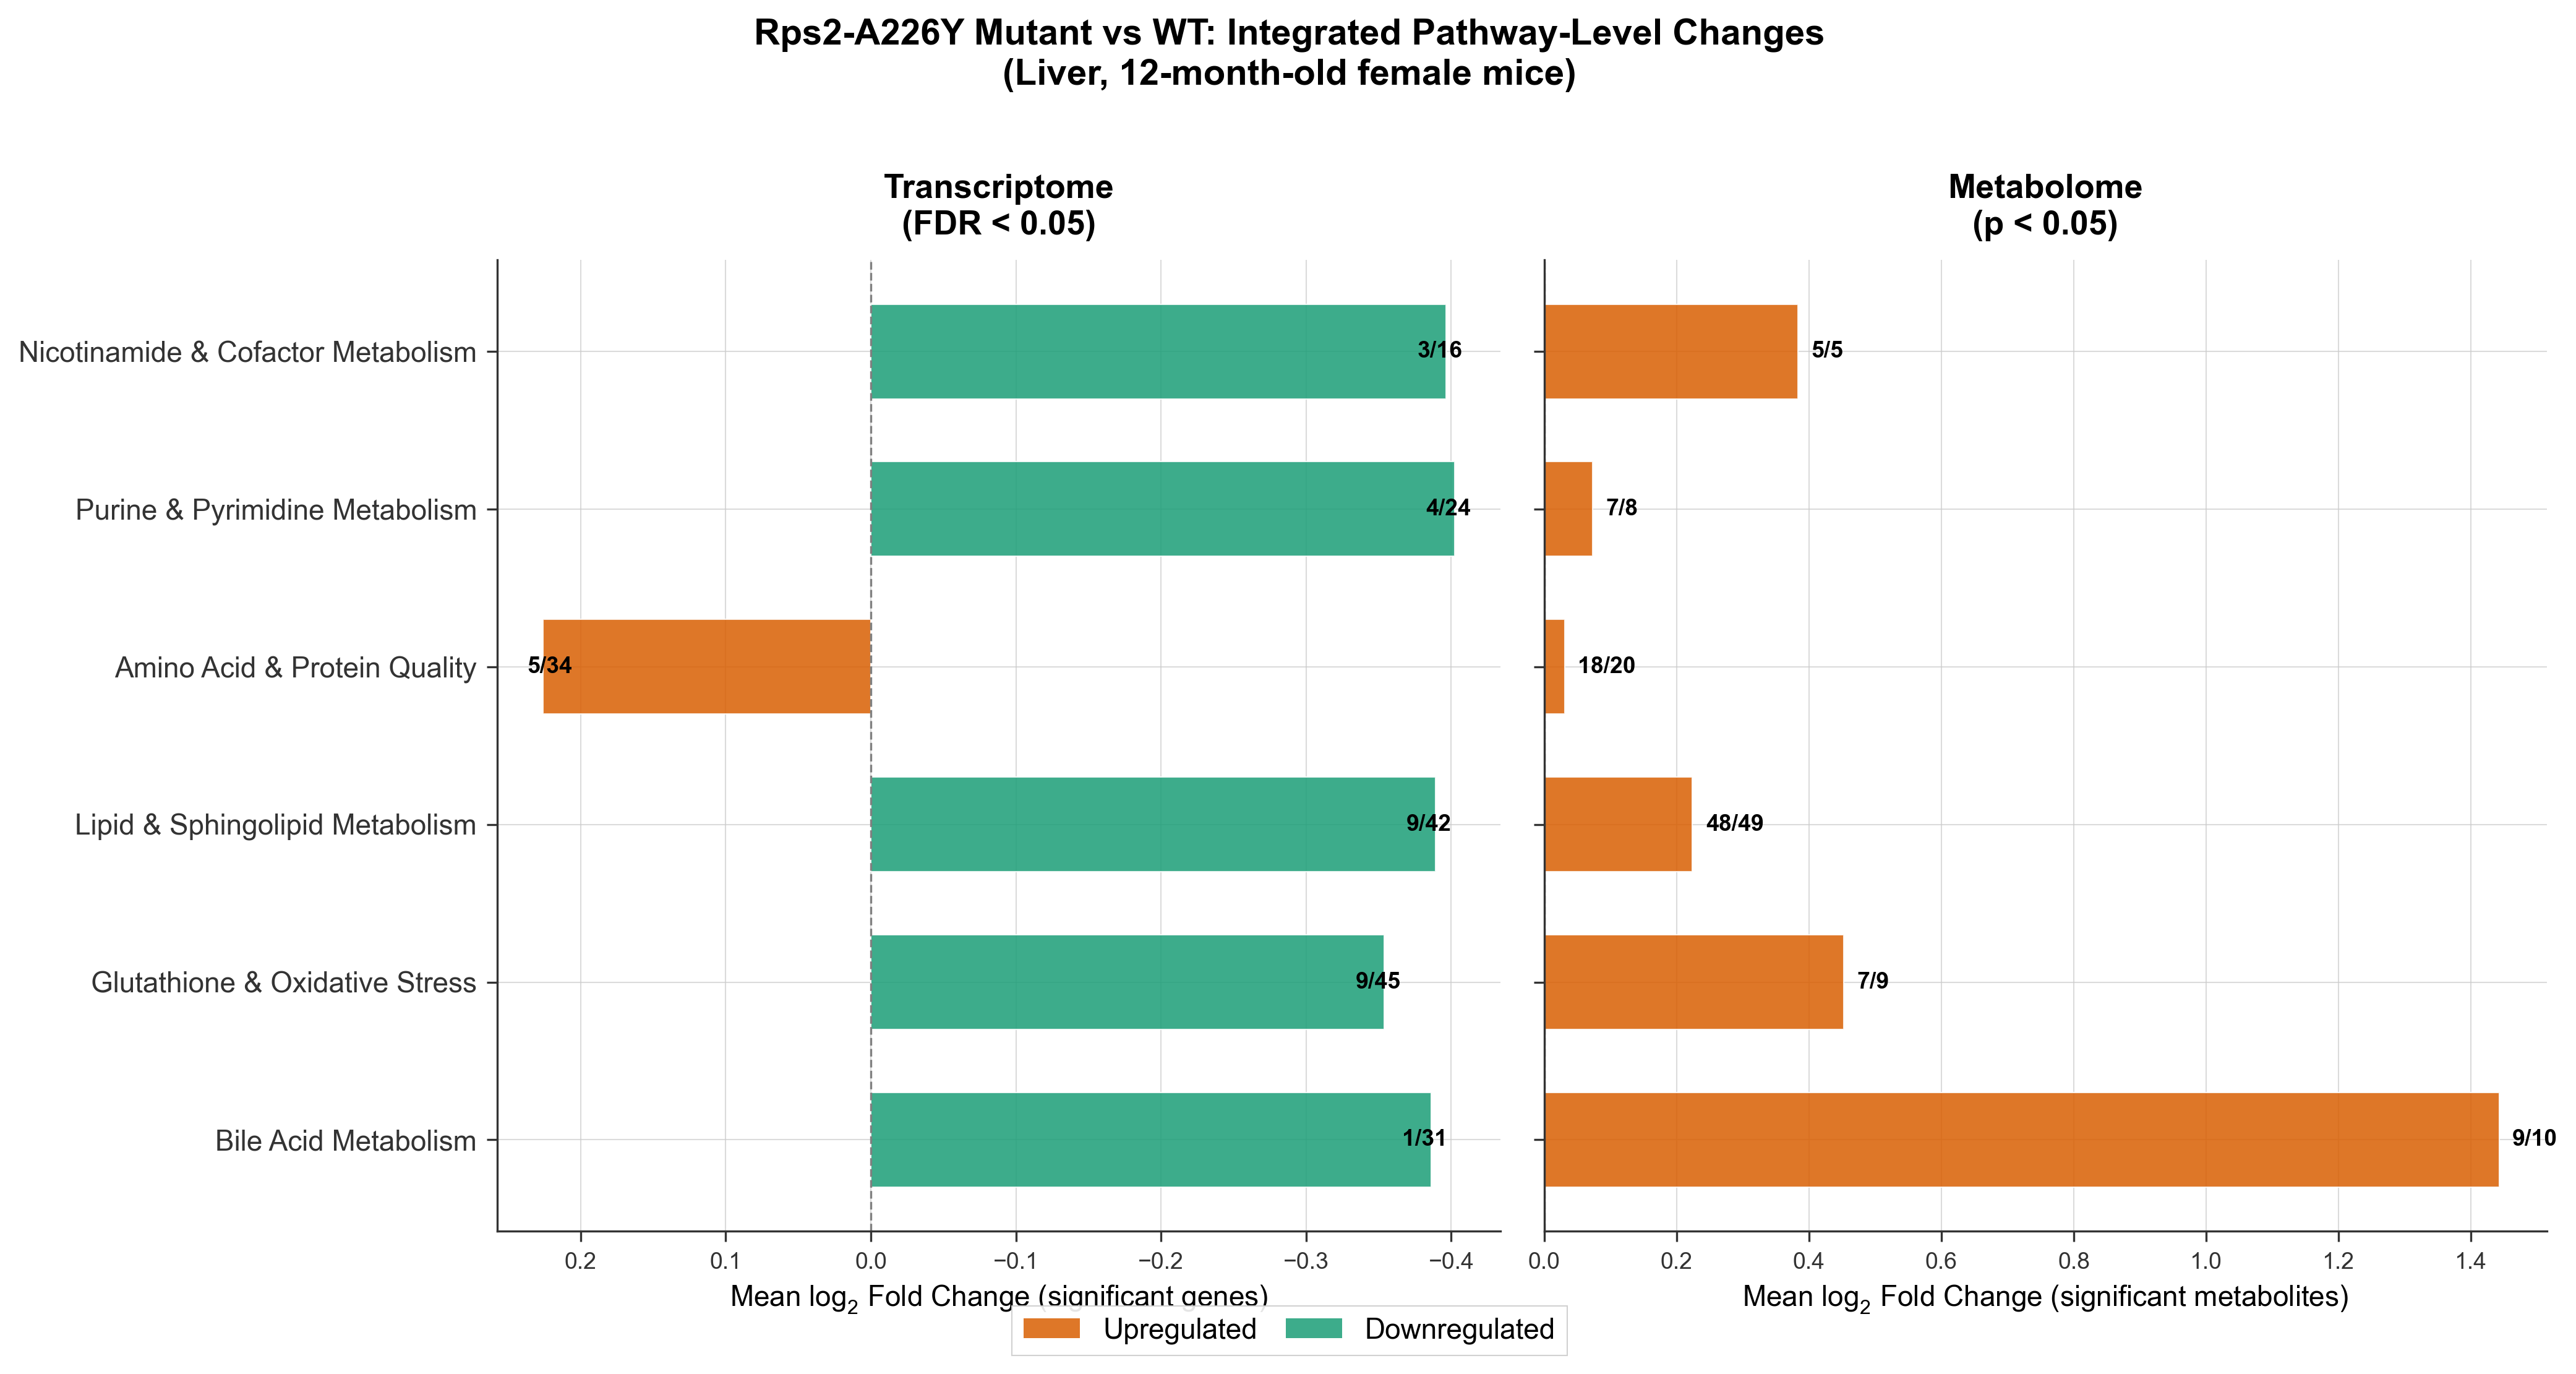

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

plt.style.use("science_machine")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

pathways = pdf['Pathway'].values
y_pos = np.arange(len(pathways))

# Color mapping based on direction
cmap = plt.cm.get_cmap('mako')

# --- Left panel: Transcriptomics ---
ax1 = axes[0]
colors_gene = ['#d95f02' if v > 0 else '#1b9e77' for v in pdf['mean_gene_log2FC']]
bars1 = ax1.barh(y_pos, pdf['mean_gene_log2FC'], color=colors_gene, edgecolor='white', height=0.6, alpha=0.85)

# Add gene count annotations
for i, (fc, n_sig, n_total) in enumerate(zip(pdf['mean_gene_log2FC'], pdf['n_genes_sig'], pdf['n_genes_found'])):
    offset = 0.02 if fc < 0 else -0.02
    ha = 'left' if fc < 0 else 'right'
    ax1.text(fc + offset, i, f'{n_sig}/{n_total}', va='center', ha=ha, fontsize=9, fontweight='bold')

ax1.set_yticks(y_pos)
ax1.set_yticklabels(pathways, fontsize=11)
ax1.set_xlabel(r'Mean $log_2$ Fold Change (significant genes)', fontsize=11)
ax1.set_title('Transcriptome\n(FDR < 0.05)', fontsize=13, fontweight='bold')
ax1.axvline(0, color='grey', linewidth=0.8, linestyle='--')
ax1.invert_xaxis()

# --- Right panel: Metabolomics ---
ax2 = axes[1]
colors_met = ['#d95f02' if v > 0 else '#1b9e77' for v in pdf['mean_met_log2FC']]
bars2 = ax2.barh(y_pos, pdf['mean_met_log2FC'], color=colors_met, edgecolor='white', height=0.6, alpha=0.85)

# Add metabolite count annotations
for i, (fc, n_sig, n_total) in enumerate(zip(pdf['mean_met_log2FC'], pdf['n_met_sig'], pdf['n_met_found'])):
    offset = 0.02 if fc > 0 else -0.02
    ha = 'left' if fc > 0 else 'right'
    ax2.text(fc + offset, i, f'{n_sig}/{n_total}', va='center', ha=ha, fontsize=9, fontweight='bold')

ax2.set_xlabel(r'Mean $log_2$ Fold Change (significant metabolites)', fontsize=11)
ax2.set_title('Metabolome\n(p < 0.05)', fontsize=13, fontweight='bold')
ax2.axvline(0, color='grey', linewidth=0.8, linestyle='--')

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#d95f02', alpha=0.85, label='Upregulated'),
                   Patch(facecolor='#1b9e77', alpha=0.85, label='Downregulated')]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, fontsize=11, frameon=True, bbox_to_anchor=(0.5, -0.02))

fig.suptitle('Rps2-A226Y Mutant vs WT: Integrated Pathway-Level Changes\n(Liver, 12-month-old female mice)', 
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('figures/figure1_pathway_overview.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure1_pathway_overview.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# Prepare detailed data for Figure 2 - a combined heatmap of individual genes and metabolites
# Focus on the 3 most interesting pathways with clear biological stories

# 1. Collect all significant genes and metabolites per pathway
detail_data = []

for pathway, info in pathway_gene_map.items():
    genes = info['genes']
    met_subpaths = info['metabolites']
    
    # Significant genes
    tx_genes = tx_clean[tx_clean['gene_name'].str.lower().isin([g.lower() for g in genes])]
    sig_genes = tx_genes[tx_genes['fdr'] < 0.05].copy()
    for _, row in sig_genes.iterrows():
        detail_data.append({
            'Pathway': pathway,
            'Name': row['gene_name'],
            'Type': 'Gene',
            'log2FC': row['log2 Ratio'],
            'pval': row['pValue'],
            'fdr_or_pval': row['fdr']
        })
    
    # Significant metabolites
    met_sub = met_clean[met_clean['Sub Pathway'].isin(met_subpaths)]
    sig_met = met_sub[met_sub['p-value'] < 0.05].copy()
    for _, row in sig_met.iterrows():
        detail_data.append({
            'Pathway': pathway,
            'Name': row['Biochem'],
            'Type': 'Metabolite',
            'log2FC': row['log2FC'],
            'pval': row['p-value'],
            'fdr_or_pval': row['p-value']
        })

detail_df = pd.DataFrame(detail_data)
print(f"Total entries: {len(detail_df)}")
print(detail_df.groupby(['Pathway', 'Type']).size())


Total entries: 125
Pathway                             Type      
Amino Acid & Protein Quality        Gene           5
                                    Metabolite    18
Bile Acid Metabolism                Gene           1
                                    Metabolite     9
Glutathione & Oxidative Stress      Gene           9
                                    Metabolite     7
Lipid & Sphingolipid Metabolism     Gene           9
                                    Metabolite    48
Nicotinamide & Cofactor Metabolism  Gene           3
                                    Metabolite     5
Purine & Pyrimidine Metabolism      Gene           4
                                    Metabolite     7
dtype: int64


In [ ]:
# For Figure 2, I'll create a detailed dot plot showing individual genes and metabolites
# organized by pathway, with size = significance and color = direction/magnitude

# Let's focus on the top metabolites per pathway (limit to keep readable)
# and all significant genes

# For lipid pathway, too many metabolites - take top 10 by significance
filtered = []
for pathway in detail_df['Pathway'].unique():
    sub = detail_df[detail_df['Pathway'] == pathway]
    genes = sub[sub['Type'] == 'Gene']
    mets = sub[sub['Type'] == 'Metabolite'].nsmallest(10, 'pval')
    filtered.append(genes)
    filtered.append(mets)

filt_df = pd.concat(filtered).reset_index(drop=True)
print(f"Filtered entries: {len(filt_df)}")
print(filt_df.groupby(['Pathway', 'Type']).size())


Filtered entries: 79
Pathway                             Type      
Amino Acid & Protein Quality        Gene           5
                                    Metabolite    10
Bile Acid Metabolism                Gene           1
                                    Metabolite     9
Glutathione & Oxidative Stress      Gene           9
                                    Metabolite     7
Lipid & Sphingolipid Metabolism     Gene           9
                                    Metabolite    10
Nicotinamide & Cofactor Metabolism  Gene           3
                                    Metabolite     5
Purine & Pyrimidine Metabolism      Gene           4
                                    Metabolite     7
dtype: int64


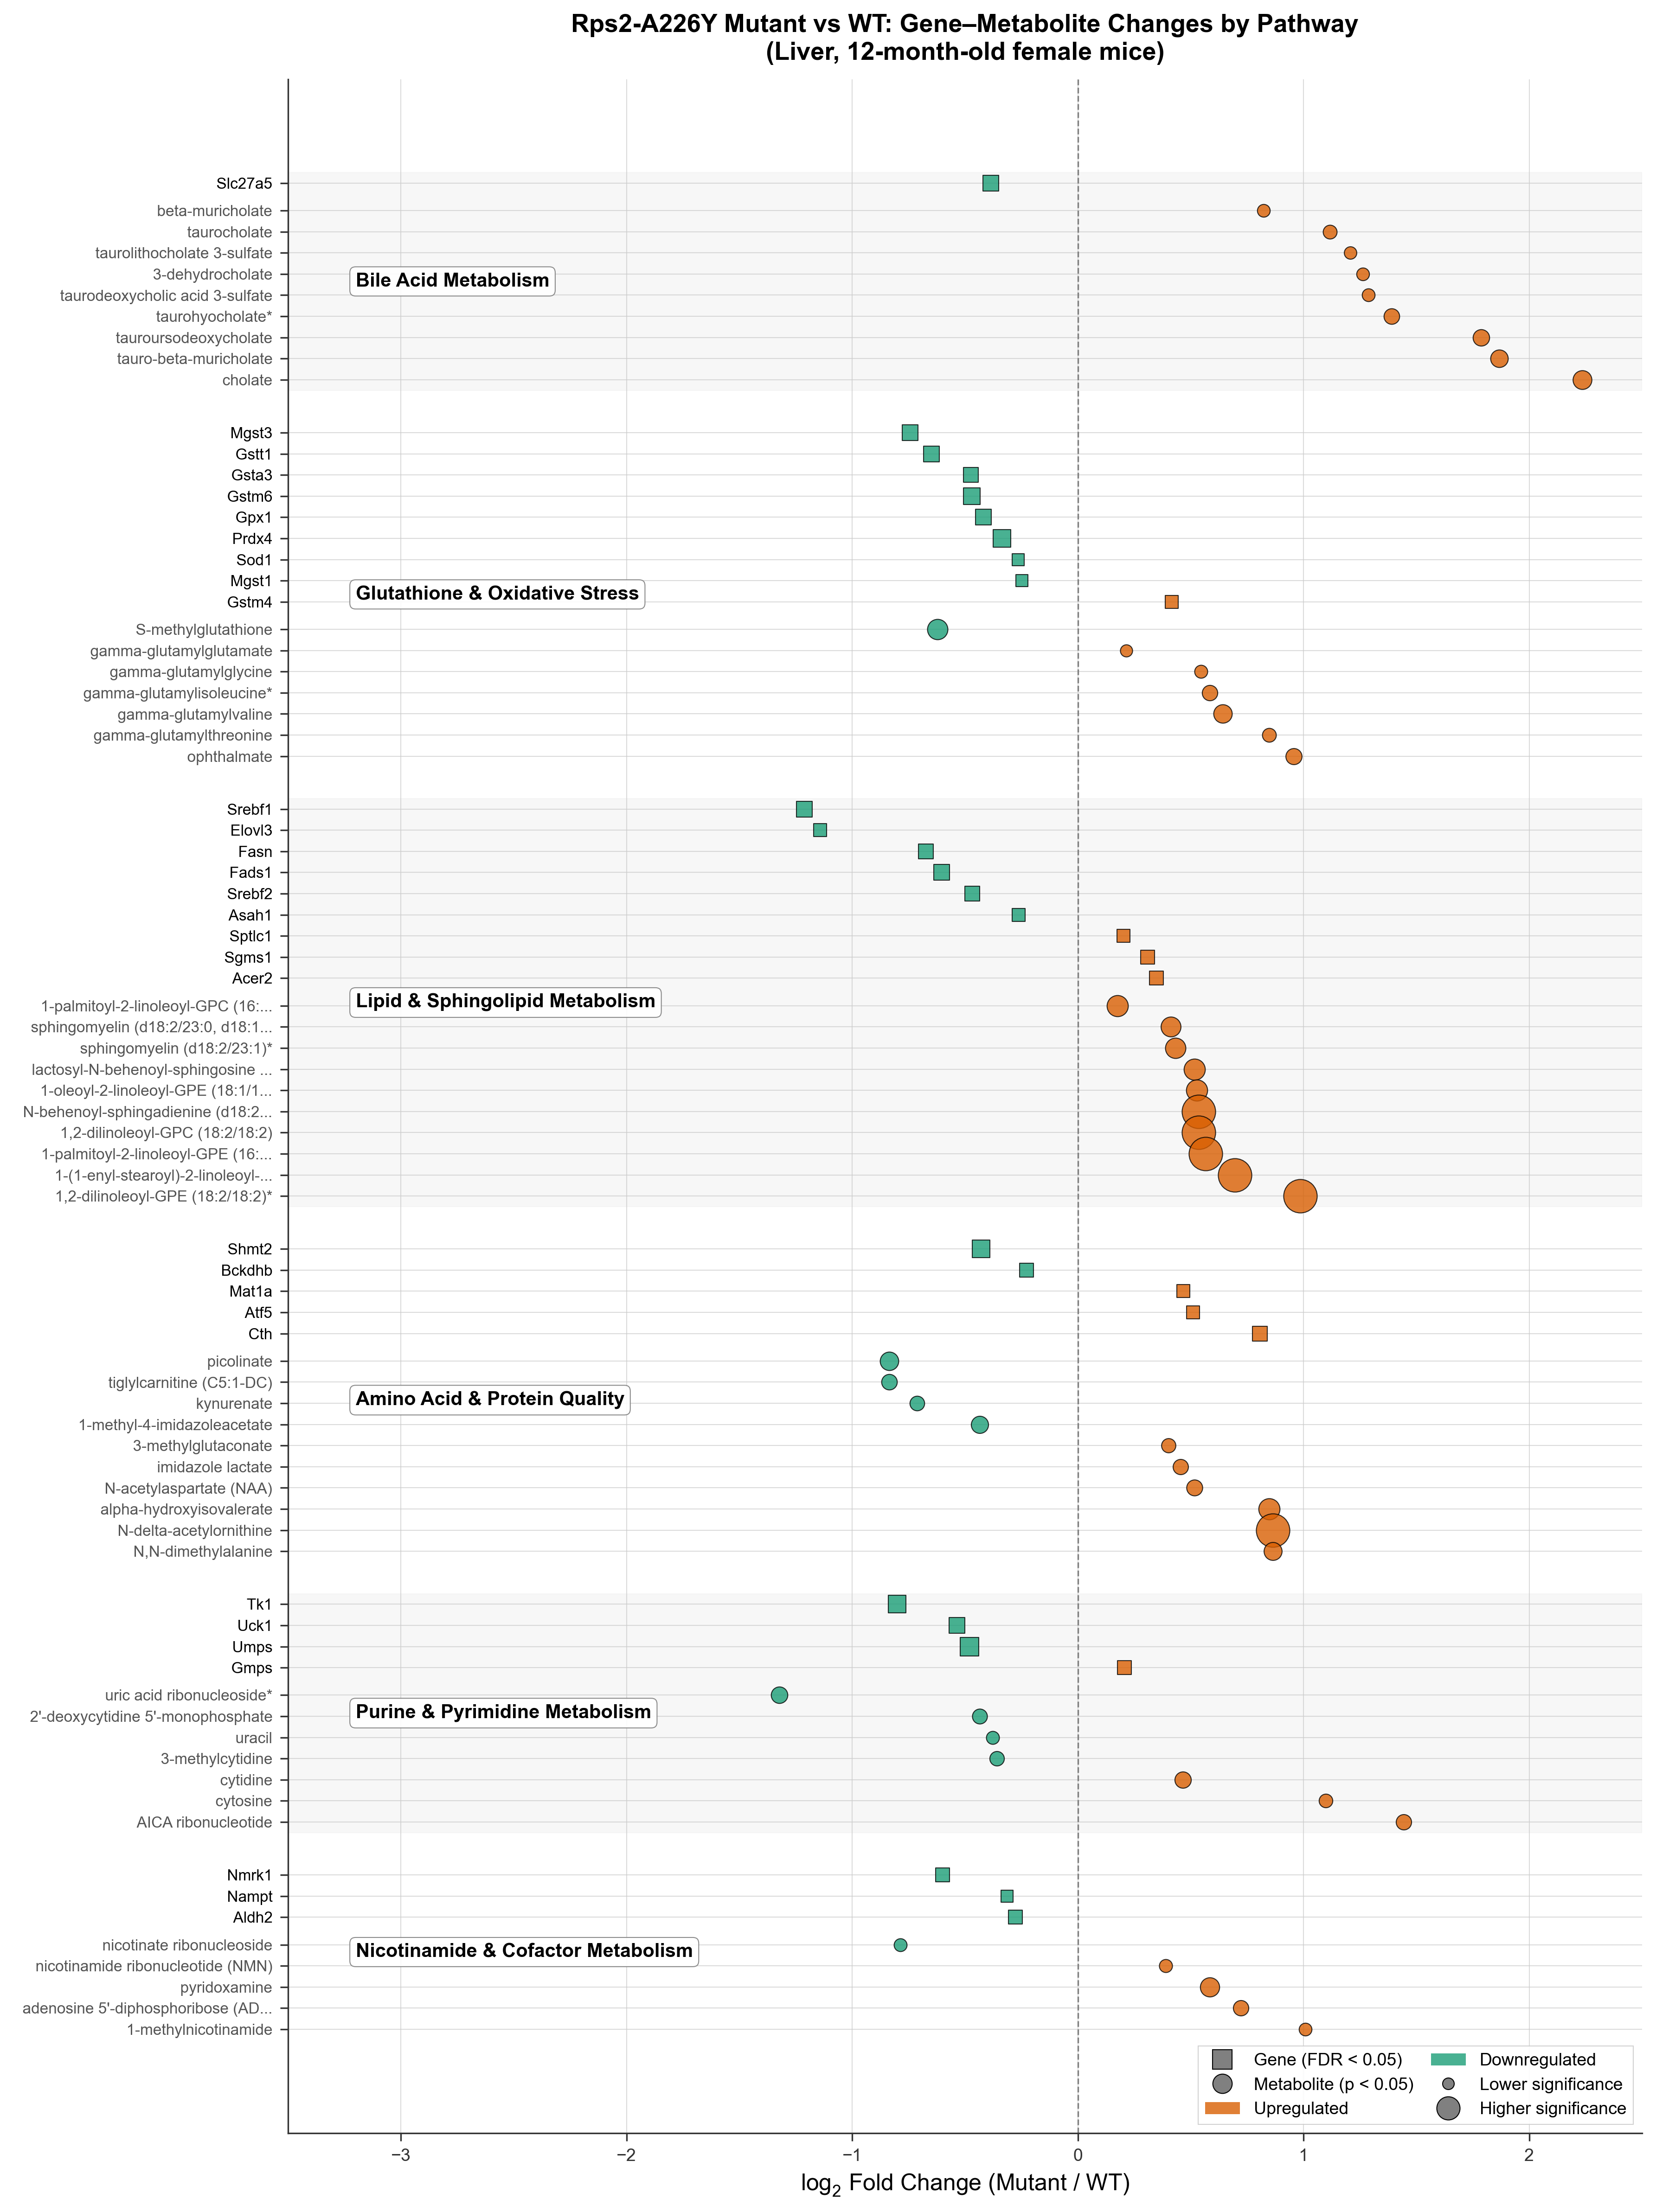

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.style.use("science_machine")

# Order pathways
pathway_order = [
    'Bile Acid Metabolism',
    'Glutathione & Oxidative Stress', 
    'Lipid & Sphingolipid Metabolism',
    'Amino Acid & Protein Quality',
    'Purine & Pyrimidine Metabolism',
    'Nicotinamide & Cofactor Metabolism'
]

# Build the figure
fig, ax = plt.subplots(figsize=(12, 16))

y_counter = 0
y_ticks = []
y_labels = []
y_colors = []
pathway_boundaries = []

for pi, pathway in enumerate(pathway_order):
    sub = filt_df[filt_df['Pathway'] == pathway].copy()
    
    # Sort: genes first (by FC), then metabolites (by FC)
    genes = sub[sub['Type'] == 'Gene'].sort_values('log2FC', ascending=True)
    mets = sub[sub['Type'] == 'Metabolite'].sort_values('log2FC', ascending=True)
    
    # Add pathway label
    pathway_start = y_counter
    
    # Plot genes
    for _, row in genes.iterrows():
        size = min(max(-np.log10(row['fdr_or_pval']) * 30, 30), 300)
        color = '#d95f02' if row['log2FC'] > 0 else '#1b9e77'
        ax.scatter(row['log2FC'], y_counter, s=size, c=color, alpha=0.8, 
                  edgecolors='black', linewidth=0.5, marker='s', zorder=3)
        y_ticks.append(y_counter)
        y_labels.append(f"  {row['Name']}")
        y_colors.append('black')
        y_counter += 1
    
    # Small gap between genes and metabolites
    y_counter += 0.3
    
    # Plot metabolites
    for _, row in mets.iterrows():
        size = min(max(-np.log10(max(row['fdr_or_pval'], 1e-10)) * 30, 30), 300)
        color = '#d95f02' if row['log2FC'] > 0 else '#1b9e77'
        # Truncate long names
        name = row['Name']
        if len(name) > 35:
            name = name[:32] + '...'
        ax.scatter(row['log2FC'], y_counter, s=size, c=color, alpha=0.8,
                  edgecolors='black', linewidth=0.5, marker='o', zorder=3)
        y_ticks.append(y_counter)
        y_labels.append(f"  {name}")
        y_colors.append('#555555')
        y_counter += 1
    
    pathway_end = y_counter - 1
    pathway_boundaries.append((pathway_start - 0.5, pathway_end + 0.5, pathway))
    
    # Add separator
    y_counter += 1.5

# Add pathway background shading and labels
colors_bg = ['#f0f0f0', '#ffffff'] * 3
for i, (ymin, ymax, pname) in enumerate(pathway_boundaries):
    ax.axhspan(ymin, ymax, color=colors_bg[i], alpha=0.5, zorder=0)
    ax.text(-3.2, (ymin + ymax) / 2, pname, fontsize=10, fontweight='bold',
            va='center', ha='left', rotation=0,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='grey', alpha=0.9))

ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels, fontsize=8)
# Color gene names vs metabolite names
for tick, color in zip(ax.get_yticklabels(), y_colors):
    tick.set_color(color)

ax.axvline(0, color='grey', linewidth=0.8, linestyle='--', zorder=1)
ax.set_xlabel(r'$log_2$ Fold Change (Mutant / WT)', fontsize=12)
ax.set_xlim(-3.5, 2.5)

# Legend
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='grey', markersize=10, 
           markeredgecolor='black', label='Gene (FDR < 0.05)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markersize=10,
           markeredgecolor='black', label='Metabolite (p < 0.05)'),
    Patch(facecolor='#d95f02', alpha=0.8, label='Upregulated'),
    Patch(facecolor='#1b9e77', alpha=0.8, label='Downregulated'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markersize=6,
           markeredgecolor='black', label='Lower significance'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markersize=12,
           markeredgecolor='black', label='Higher significance'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=True, ncol=2)

ax.set_title('Rps2-A226Y Mutant vs WT: Gene–Metabolite Changes by Pathway\n(Liver, 12-month-old female mice)', 
             fontsize=13, fontweight='bold')

ax.invert_yaxis()
plt.tight_layout()
plt.savefig('figures/figure2_gene_metabolite_detail.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure2_gene_metabolite_detail.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
import pandas as pd
# Read the 6m metabolomics file - check structure
met6_raw = pd.read_csv("Liver 6m mice metabolomics mut vs wt differential analysis.csv", sep=";", nrows=5)
print("Columns:", met6_raw.columns.tolist())
print(met6_raw.head())


Columns: ['Super Pathway', 'Sub Pathway', 'Biochemical Name', 'Comp ID', 'KEGG', 'HMDB', 'PubChem', 'FC', 'Mutant 6 Months / WT 6 Months', 'Unnamed: 9']
  Super Pathway                               Sub Pathway Biochemical Name  \
0           NaN                                       NaN              NaN   
1    Amino Acid  Glycine, Serine and Threonine Metabolism          glycine   
2           NaN                                       NaN  N-acetylglycine   
3           NaN                                       NaN        sarcosine   
4           NaN                                       NaN  dimethylglycine   

   Comp ID    KEGG       HMDB  PubChem        FC  \
0      NaN     NaN        NaN      NaN  6 Months   
1     58.0  C00037  HMDB00123    750.0      0.87   
2  27710.0     NaN  HMDB00532  10972.0      0.81   
3   1516.0  C00213  HMDB00271   1088.0      0.98   
4   5086.0  C01026  HMDB00092    673.0      0.95   

  Mutant 6 Months / WT 6 Months Unnamed: 9  
0                   

In [ ]:
# The header is messy - row 0 contains sub-headers. Let me read it properly
met6_raw = pd.read_csv("Liver 6m mice metabolomics mut vs wt differential analysis.csv", sep=";")
print("Shape:", met6_raw.shape)
print("\nFirst 5 rows:")
print(met6_raw.head())
print("\nLast 5 rows:")
print(met6_raw.tail())


Shape: (739, 10)

First 5 rows:
  Super Pathway                               Sub Pathway Biochemical Name  \
0           NaN                                       NaN              NaN   
1    Amino Acid  Glycine, Serine and Threonine Metabolism          glycine   
2           NaN                                       NaN  N-acetylglycine   
3           NaN                                       NaN        sarcosine   
4           NaN                                       NaN  dimethylglycine   

   Comp ID    KEGG       HMDB PubChem        FC Mutant 6 Months / WT 6 Months  \
0      NaN     NaN        NaN     NaN  6 Months                       p-value   
1     58.0  C00037  HMDB00123     750      0.87                        0.0993   
2  27710.0     NaN  HMDB00532   10972      0.81                        0.0476   
3   1516.0  C00213  HMDB00271    1088      0.98                        0.6756   
4   5086.0  C01026  HMDB00092     673      0.95                        0.9314   

  Unnamed: 9

In [ ]:
# Clean the 6m metabolomics data
# Row 0 is a sub-header row, skip it
# Super Pathway and Sub Pathway have forward-fill pattern (NaN means same as above)

met6 = pd.read_csv("Liver 6m mice metabolomics mut vs wt differential analysis.csv", sep=";", skiprows=[1])
# Rename columns properly
met6.columns = ['Super Pathway', 'Sub Pathway', 'Biochem', 'Comp ID', 'KEGG', 'HMDB', 'PubChem', 'FC', 'p-value', 'q-value']
# Forward fill Super Pathway and Sub Pathway
met6['Super Pathway'] = met6['Super Pathway'].ffill()
met6['Sub Pathway'] = met6['Sub Pathway'].ffill()
# Drop rows with no biochemical name
met6 = met6.dropna(subset=['Biochem']).copy()
# Convert FC and p-value to numeric
met6['FC'] = pd.to_numeric(met6['FC'], errors='coerce')
met6['p-value'] = pd.to_numeric(met6['p-value'], errors='coerce')
met6['q-value'] = pd.to_numeric(met6['q-value'], errors='coerce')
met6 = met6.dropna(subset=['FC']).copy()

import numpy as np
met6['log2FC'] = np.log2(met6['FC'])
met6['neg_log10p'] = -np.log10(met6['p-value'].replace(0, 1e-10))
met6['significant'] = met6['p-value'] < 0.05

print(f"6m Metabolomics: {met6.shape[0]} metabolites")
print(f"  Significant (p<0.05): {met6['significant'].sum()}")
print(f"  Up: {((met6['log2FC'] > 0) & met6['significant']).sum()}")
print(f"  Down: {((met6['log2FC'] < 0) & met6['significant']).sum()}")
print(f"\nSuper Pathway counts:")
print(met6['Super Pathway'].value_counts())


6m Metabolomics: 738 metabolites
  Significant (p<0.05): 92
  Up: 35
  Down: 57

Super Pathway counts:
Super Pathway
Lipid                                365
Amino Acid                           165
Nucleotide                            54
Carbohydrate                          48
Cofactors and Vitamins                47
Xenobiotics                           27
Peptide                               19
Energy                                12
Partially Characterized Molecules      1
Name: count, dtype: int64


In [ ]:
# Read 6m transcriptomics
tx6 = pd.read_excel("custom edgeR output 6M mice Mut v Wtcr transcriptome.xlsx", sheet_name="Sheet1")
print("Shape:", tx6.shape)
print("Columns:", tx6.columns.tolist())
print(tx6.head())
print(f"\nFDR < 0.05: {(tx6['fdr'] < 0.05).sum()}")
print(f"FDR < 0.1: {(tx6['fdr'] < 0.1).sum()}")
print(f"pValue < 0.05: {(tx6['pValue'] < 0.05).sum()}")


Shape: (22524, 5)
Columns: ['gene_name', 'pValue', 'fdr', 'log2 Ratio', 'gfold (log2 Change)']
   gene_name        pValue           fdr  log2 Ratio  gfold (log2 Change)
0     Gm9825  2.789000e-12  3.635000e-08      2.3980               3.3010
1      Abca3  5.231000e-10  3.409000e-06      0.9267               0.4542
2     Dnaja4  3.582000e-08  1.556000e-04      1.1130               0.6879
3  Hmga1-rs1  1.224000e-07  3.987000e-04      1.0670               1.6450
4    Atp6v0c  2.434000e-07  6.343000e-04     -0.6582              -0.2397

FDR < 0.05: 255
FDR < 0.1: 587
pValue < 0.05: 2420


In [ ]:
# Much fewer significant genes at 6m! Let's check the distribution
tx6_clean = tx6.dropna(subset=['gene_name']).copy()
tx6_clean['significant'] = tx6_clean['fdr'] < 0.05
tx6_clean['neg_log10p'] = -np.log10(tx6_clean['pValue'].replace(0, 1e-10))

print("6m Transcriptomics summary:")
print(f"  Total genes: {tx6_clean.shape[0]}")
print(f"  FDR < 0.05: {tx6_clean['significant'].sum()}")
print(f"    Up: {((tx6_clean['log2 Ratio'] > 0) & tx6_clean['significant']).sum()}")
print(f"    Down: {((tx6_clean['log2 Ratio'] < 0) & tx6_clean['significant']).sum()}")
print(f"\n  log2 Ratio range: {tx6_clean['log2 Ratio'].min():.2f} to {tx6_clean['log2 Ratio'].max():.2f}")

# Compare with 12m
print("\n--- Comparison with 12m ---")
print(f"12m: {tx_clean['significant'].sum()} sig genes (FDR<0.05), {met_clean['significant'].sum()} sig metabolites (p<0.05)")
print(f"6m:  {tx6_clean['significant'].sum()} sig genes (FDR<0.05), {met6['significant'].sum()} sig metabolites (p<0.05)")


6m Transcriptomics summary:
  Total genes: 22524
  FDR < 0.05: 255
    Up: 131
    Down: 124

  log2 Ratio range: -3.61 to 2.99

--- Comparison with 12m ---


In [ ]:
# Reload 12m data
tx12 = pd.read_excel("custom edgeR output 12M mice Mut v Wtcr transcriptome.xlsx", sheet_name="Sheet1")
tx12_clean = tx12.dropna(subset=['gene_name']).copy()
tx12_clean['significant'] = tx12_clean['fdr'] < 0.05

met12 = pd.read_csv("Liver 12m mice metabolomics mut vs wt differential analysis.csv", sep=";")
met12_clean = met12.dropna(subset=['Biochem']).copy()
met12_clean['log2FC'] = np.log2(met12_clean['12 Months'])
met12_clean['significant'] = met12_clean['p-value'] < 0.05

print("--- Comparison ---")
print(f"12m: {tx12_clean['significant'].sum()} sig genes, {met12_clean['significant'].sum()}/{met12_clean.shape[0]} sig metabolites")
print(f"6m:  {tx6_clean['significant'].sum()} sig genes, {met6['significant'].sum()}/{met6.shape[0]} sig metabolites")


--- Comparison ---
12m: 1892 sig genes, 157/173 sig metabolites
6m:  255 sig genes, 92/738 sig metabolites


In [ ]:
# Check sub-pathway distribution in 6m metabolomics
print("6m Sub Pathway counts (top 20):")
print(met6['Sub Pathway'].value_counts().head(20))
print("\n6m significant metabolites by Super Pathway:")
print(met6[met6['significant']].groupby('Super Pathway').size().sort_values(ascending=False))


6m Sub Pathway counts (top 20):
Sub Pathway
Lysophospholipid                                        28
Diacylglycerol                                          26
Leucine, Isoleucine and Valine Metabolism               25
Sphingomyelins                                          24
Phosphatidylcholine (PC)                                23
Long Chain Polyunsaturated Fatty Acid (n3 and n6)       21
Fatty Acid, Dicarboxylate                               19
Methionine, Cysteine, SAM and Taurine Metabolism        19
Urea cycle; Arginine and Proline Metabolism             18
Food Component/Plant                                    16
Lysine Metabolism                                       16
Histidine Metabolism                                    15
Phosphatidylethanolamine (PE)                           15
Secondary Bile Acid Metabolism                          14
Fatty Acid, Monohydroxy                                 13
Endocannabinoid                                         12
Purine Metab

In [ ]:
# Step 1: Metabolite Pathway Enrichment Analysis for 6m
# Use Over-Representation Analysis (ORA) with Fisher's exact test
from scipy.stats import fisher_exact

def metabolite_pathway_ora(met_df, fc_col='log2FC', pval_col='p-value', pathway_col='Sub Pathway', 
                           sig_threshold=0.05, fc_threshold=0):
    """Perform ORA on metabolite sub-pathways."""
    results = []
    sig_mets = met_df[met_df[pval_col] < sig_threshold]
    total_sig = len(sig_mets)
    total_nonsig = len(met_df) - total_sig
    
    for pathway in met_df[pathway_col].unique():
        pw_mets = met_df[met_df[pathway_col] == pathway]
        pw_sig = sig_mets[sig_mets[pathway_col] == pathway]
        
        if len(pw_mets) < 2:
            continue
        
        # Fisher's exact test: enrichment of significant metabolites in this pathway
        a = len(pw_sig)  # sig in pathway
        b = total_sig - a  # sig not in pathway
        c = len(pw_mets) - a  # not sig in pathway
        d = total_nonsig - c  # not sig not in pathway
        
        _, pval = fisher_exact([[a, b], [c, d]], alternative='greater')
        
        mean_fc = pw_sig[fc_col].mean() if len(pw_sig) > 0 else 0
        direction = 'Up' if mean_fc > 0 else 'Down'
        
        results.append({
            'Pathway': pathway,
            'n_total': len(pw_mets),
            'n_sig': a,
            'pct_sig': a / len(pw_mets) * 100,
            'mean_log2FC': pw_sig[fc_col].mean() if len(pw_sig) > 0 else np.nan,
            'fisher_p': pval,
            'direction': direction
        })
    
    res_df = pd.DataFrame(results).sort_values('fisher_p')
    # FDR correction
    from statsmodels.stats.multitest import multipletests
    _, res_df['fisher_fdr'], _, _ = multipletests(res_df['fisher_p'], method='fdr_bh')
    return res_df

met6_ora = metabolite_pathway_ora(met6)
print("6m Metabolite Pathway ORA (top 15):")
print(met6_ora.head(15).to_string(index=False))


6m Metabolite Pathway ORA (top 15):
                                          Pathway  n_total  n_sig   pct_sig  mean_log2FC  fisher_p direction  fisher_fdr
                                           Sterol        5      3 60.000000     0.476412  0.015567        Up    0.707989
                    Phosphatidylethanolamine (PE)       15      5 33.333333     0.264926  0.029280        Up    0.707989
Long Chain Polyunsaturated Fatty Acid (n3 and n6)       21      6 28.571429    -0.381548  0.036423      Down    0.707989
                             Glutamate Metabolism       11      4 36.363636    -0.420580  0.037425      Down    0.707989
                                Lysine Metabolism       16      5 31.250000    -0.018306  0.038478      Down    0.707989
                         Phosphatidylcholine (PC)       23      6 26.086957    -0.020679  0.055112      Down    0.845056
              Hemoglobin and Porphyrin Metabolism        4      2 50.000000    -0.590902  0.077980      Down    1.000

In [ ]:
# Also do ORA for 12m metabolomics for comparison
met12_ora = metabolite_pathway_ora(met12_clean, fc_col='log2FC', pval_col='p-value', pathway_col='Sub Pathway')
print("12m Metabolite Pathway ORA (top 15):")
print(met12_ora.head(15).to_string(index=False))


12m Metabolite Pathway ORA (top 15):
                                          Pathway  n_total  n_sig  pct_sig  mean_log2FC  fisher_p direction  fisher_fdr
                                   Sphingomyelins       12     12    100.0     0.357201  0.299590        Up    0.991934
                         Phosphatidylcholine (PC)        7      7    100.0     0.104491  0.500561        Up    0.991934
                                      Plasmalogen        5      5    100.0     0.385940  0.611874        Up    0.991934
                    Phosphatidylethanolamine (PE)        5      5    100.0     0.415433  0.611874        Up    0.991934
        Leucine, Isoleucine and Valine Metabolism        4      4    100.0    -0.020519  0.675861      Down    0.991934
Long Chain Polyunsaturated Fatty Acid (n3 and n6)        4      4    100.0    -0.097376  0.675861      Down    0.991934
           Nicotinate and Nicotinamide Metabolism        4      4    100.0     0.333338  0.675861        Up    0.991934
   

In [ ]:
# The 12m metabolomics data is pre-filtered (only 173 metabolites, mostly significant)
# so ORA is not very informative. Let me use Quantitative Enrichment Analysis instead.
# Use Wilcoxon rank-sum test on log2FC values per pathway

from scipy.stats import ranksums, mannwhitneyu
from statsmodels.stats.multitest import multipletests

def metabolite_pathway_qea(met_df, fc_col='log2FC', pathway_col='Sub Pathway', min_size=3):
    """Quantitative enrichment: test if pathway metabolites have different FC than background."""
    results = []
    all_fc = met_df[fc_col].dropna().values
    
    for pathway in met_df[pathway_col].unique():
        pw_mets = met_df[met_df[pathway_col] == pathway]
        pw_fc = pw_mets[fc_col].dropna().values
        bg_fc = met_df[met_df[pathway_col] != pathway][fc_col].dropna().values
        
        if len(pw_fc) < min_size:
            continue
        
        stat, pval = ranksums(pw_fc, bg_fc)
        
        results.append({
            'Pathway': pathway,
            'n': len(pw_fc),
            'mean_log2FC': pw_fc.mean(),
            'median_log2FC': np.median(pw_fc),
            'wilcoxon_p': pval,
            'direction': 'Up' if pw_fc.mean() > 0 else 'Down'
        })
    
    res_df = pd.DataFrame(results).sort_values('wilcoxon_p')
    _, res_df['wilcoxon_fdr'], _, _ = multipletests(res_df['wilcoxon_p'], method='fdr_bh')
    return res_df

# QEA for 6m
met6_qea = metabolite_pathway_qea(met6)
print("6m Metabolite Pathway QEA (top 15):")
print(met6_qea.head(15).to_string(index=False))


6m Metabolite Pathway QEA (top 15):
                                             Pathway  n  mean_log2FC  median_log2FC  wilcoxon_p direction  wilcoxon_fdr
                             Fatty Acid, Monohydroxy 13     0.268263       0.214125    0.000093        Up      0.005066
                           Fatty Acid, Dicarboxylate 19     0.200906       0.111031    0.000133        Up      0.005066
                        Primary Bile Acid Metabolism  8     0.471873       0.427357    0.000545        Up      0.013810
                                         Glycosyl PE  7    -0.378990      -0.415037    0.002051      Down      0.038974
               Purine Metabolism, Adenine containing 12    -0.261545      -0.286411    0.003031      Down      0.046064
   Long Chain Polyunsaturated Fatty Acid (n3 and n6) 21    -0.206172      -0.251539    0.006594      Down      0.081679
                     Pantothenate and CoA Metabolism  4    -0.830183      -0.910053    0.007523      Down      0.081679
    

In [ ]:
# Now do gene set enrichment analysis (GSEA) on the 6m transcriptome using gseapy
import gseapy as gp

# Prepare ranked gene list for GSEA (rank by signed -log10 p-value)
tx6_ranked = tx6_clean[['gene_name', 'log2 Ratio', 'pValue']].copy()
tx6_ranked['rank_metric'] = -np.log10(tx6_ranked['pValue']) * np.sign(tx6_ranked['log2 Ratio'])
tx6_ranked = tx6_ranked.sort_values('rank_metric', ascending=False)
tx6_ranked = tx6_ranked.drop_duplicates(subset='gene_name', keep='first')

# Create ranking series
rnk = tx6_ranked.set_index('gene_name')['rank_metric']
print(f"Ranked gene list: {len(rnk)} genes")
print(rnk.head())


Ranked gene list: 22473 genes
gene_name
Gm9825       11.554551
Abca3         9.281415
Dnaja4        7.445874
Hmga1-rs1     6.912219
Meiob         6.261140
Name: rank_metric, dtype: float64


In [ ]:
# Run GSEA with KEGG gene sets
pre_res_6m = gp.prerank(
    rnk=rnk,
    gene_sets='KEGG_2019_Mouse',
    min_size=10,
    max_size=500,
    permutation_num=1000,
    seed=42,
    no_plot=True,
    verbose=False
)

gsea_6m = pre_res_6m.res2d.sort_values('FDR q-val')
print("6m GSEA KEGG results (top 20):")
print(gsea_6m[['Term', 'NES', 'NOM p-val', 'FDR q-val', 'Tag %']].head(20).to_string(index=False))


2026-05-18 23:34:33,967 [WARNING] Duplicated values found in preranked stats: 44.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


In [ ]:
# There's a gene name that got parsed as datetime. Let's fix it
print("Non-string gene names:")
non_str = rnk.index[~rnk.index.map(lambda x: isinstance(x, str))]
print(non_str)
print(rnk.loc[non_str])


Non-string gene names:
Index([2005-09-01 00:00:00, 2003-09-01 00:00:00, 2009-09-01 00:00:00,
       2011-09-01 00:00:00, 2015-09-01 00:00:00, 2002-09-01 00:00:00,
       2008-09-01 00:00:00, 2012-09-01 00:00:00, 2014-09-01 00:00:00,
       2007-09-01 00:00:00, 2001-09-01 00:00:00, 2004-09-01 00:00:00,
       2006-09-01 00:00:00, 2010-09-01 00:00:00],
      dtype='object', name='gene_name')
gene_name
2005-09-01 00:00:00    2.742321
2003-09-01 00:00:00    0.661743
2009-09-01 00:00:00    0.640924
2011-09-01 00:00:00    0.335170
2015-09-01 00:00:00    0.284498
2002-09-01 00:00:00    0.279510
2008-09-01 00:00:00    0.007093
2012-09-01 00:00:00   -0.000000
2014-09-01 00:00:00   -0.002090
2007-09-01 00:00:00   -0.119987
2001-09-01 00:00:00   -0.392331
2004-09-01 00:00:00   -0.515131
2006-09-01 00:00:00   -0.826522
2010-09-01 00:00:00   -1.336770
Name: rank_metric, dtype: float64


In [ ]:
# These are Sep-family genes (Sep1, Sep2, etc.) that Excel converted to dates
# Filter them out and convert index to string
rnk_clean = rnk[rnk.index.map(lambda x: isinstance(x, str))].copy()
print(f"Cleaned ranked list: {len(rnk_clean)} genes (removed {len(rnk) - len(rnk_clean)} date-converted entries)")

# Run GSEA
pre_res_6m = gp.prerank(
    rnk=rnk_clean,
    gene_sets='KEGG_2019_Mouse',
    min_size=10, max_size=500,
    permutation_num=1000, seed=42, no_plot=True, verbose=False
)
gsea_6m = pre_res_6m.res2d.sort_values('FDR q-val')
print("\n6m GSEA KEGG (top 20):")
print(gsea_6m[['Term', 'NES', 'NOM p-val', 'FDR q-val']].head(20).to_string(index=False))


2026-05-18 23:34:50,416 [WARNING] Duplicated values found in preranked stats: 44.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Cleaned ranked list: 22459 genes (removed 14 date-converted entries)


In [ ]:
# gseapy download issue. Let me try with Enrichr-based library or use gprofiler instead
from gprofiler import GProfiler
gp_client = GProfiler(return_dataframe=True)

# Get significant genes for 6m
sig_genes_6m_up = tx6_clean[(tx6_clean['fdr'] < 0.05) & (tx6_clean['log2 Ratio'] > 0)]['gene_name'].tolist()
sig_genes_6m_down = tx6_clean[(tx6_clean['fdr'] < 0.05) & (tx6_clean['log2 Ratio'] < 0)]['gene_name'].tolist()
sig_genes_6m_all = tx6_clean[tx6_clean['fdr'] < 0.05]['gene_name'].tolist()

print(f"6m sig genes: {len(sig_genes_6m_all)} total ({len(sig_genes_6m_up)} up, {len(sig_genes_6m_down)} down)")

# Run g:Profiler enrichment
enrich_6m = gp_client.profile(
    organism='mmusculus',
    query=sig_genes_6m_all,
    sources=['KEGG', 'REAC', 'GO:BP'],
    significance_threshold_method='fdr',
    user_threshold=0.05
)
print(f"\n6m enrichment results: {len(enrich_6m)} significant terms")
if len(enrich_6m) > 0:
    print(enrich_6m[['source', 'native', 'name', 'p_value', 'intersection_size', 'term_size']].head(20).to_string(index=False))


6m sig genes: 255 total (131 up, 124 down)



6m enrichment results: 92 significant terms
source             native                                       name      p_value  intersection_size  term_size
 GO:BP         GO:0170033             L-amino acid metabolic process 4.103172e-12                 16        111
 GO:BP         GO:0006082             organic acid metabolic process 1.752851e-11                 33        789
 GO:BP         GO:0019752          carboxylic acid metabolic process 1.752851e-11                 33        769
 GO:BP         GO:0043436                  oxoacid metabolic process 1.752851e-11                 33        783
 GO:BP         GO:0170039 proteinogenic amino acid metabolic process 1.752851e-11                 15        108
 GO:BP         GO:0044282           small molecule catabolic process 2.563317e-11                 21        287
 GO:BP         GO:0016054             organic acid catabolic process 2.648031e-11                 18        196
 GO:BP         GO:0046395          carboxylic acid cataboli

In [ ]:
# Also run for 12m
sig_genes_12m_all = tx12_clean[tx12_clean['fdr'] < 0.05]['gene_name'].tolist()
# Filter out date-converted entries
sig_genes_12m_all = [g for g in sig_genes_12m_all if isinstance(g, str)]

enrich_12m = gp_client.profile(
    organism='mmusculus',
    query=sig_genes_12m_all,
    sources=['KEGG', 'REAC', 'GO:BP'],
    significance_threshold_method='fdr',
    user_threshold=0.05
)
print(f"12m enrichment results: {len(enrich_12m)} significant terms")
if len(enrich_12m) > 0:
    print(enrich_12m[['source', 'native', 'name', 'p_value', 'intersection_size', 'term_size']].head(20).to_string(index=False))


12m enrichment results: 1609 significant terms
source     native                                      name      p_value  intersection_size  term_size
 GO:BP GO:0009056                         catabolic process 1.116428e-47                324       2141
 GO:BP GO:0019538                 protein metabolic process 2.920972e-46                473       3854
 GO:BP GO:0044281          small molecule metabolic process 3.453129e-44                257       1549
 GO:BP GO:0051179                              localization 6.370394e-37                523       4803
 GO:BP GO:0009987                          cellular process 6.370394e-37               1481      20290
 GO:BP GO:0048518 positive regulation of biological process 1.722687e-35                588       5712
 GO:BP GO:0008152                         metabolic process 2.741975e-35               1095      13249
 GO:BP GO:0006629                   lipid metabolic process 4.399172e-35                209       1266
 GO:BP GO:0051234         

In [ ]:
# Let's focus on KEGG and Reactome terms for cleaner comparison
kegg_6m = enrich_6m[enrich_6m['source'].isin(['KEGG', 'REAC'])].copy()
kegg_12m = enrich_12m[enrich_12m['source'].isin(['KEGG', 'REAC'])].copy()

print("6m KEGG/Reactome enriched pathways:")
print(kegg_6m[['source', 'name', 'p_value', 'intersection_size', 'term_size']].to_string(index=False))
print(f"\n--- Total: {len(kegg_6m)} pathways ---")


6m KEGG/Reactome enriched pathways:
source                                                                                name      p_value  intersection_size  term_size
  KEGG                                                                  Metabolic pathways 1.119931e-08                 50       1646
  REAC                                                                          Metabolism 1.512911e-05                 53       1740
  REAC                                           Metabolism of amino acids and derivatives 3.378407e-04                 15        229
  REAC                                                                Protein localization 1.839852e-02                  8        100
  REAC                                                                           Drug ADME 1.942935e-02                  8        105
  REAC                                                          Peroxisomal protein import 3.157533e-02                  6         63
  REAC                    

In [ ]:
print("12m KEGG/Reactome enriched pathways (top 30):")
print(kegg_12m[['source', 'name', 'p_value', 'intersection_size', 'term_size']].head(30).to_string(index=False))
print(f"\n--- Total: {len(kegg_12m)} pathways ---")


12m KEGG/Reactome enriched pathways (top 30):
source                                                   name      p_value  intersection_size  term_size
  KEGG                                     Metabolic pathways 4.210656e-22                254       1646
  REAC                                             Metabolism 1.759456e-11                285       1740
  REAC              Metabolism of amino acids and derivatives 3.793833e-07                 58        229
  REAC                                   Metabolism of lipids 9.466958e-06                109        592
  REAC                               Cholesterol biosynthesis 1.214625e-05                 15         28
  KEGG                                      Carbon metabolism 3.474083e-05                 29        121
  KEGG                                             Peroxisome 2.630316e-04                 22         87
  KEGG                                          Toxoplasmosis 7.500827e-04                 24        109
  KEGG   

In [ ]:
# Apply the same pathway-gene mapping to 6m data
pathway_gene_map = {
    'Bile Acid Metabolism': {
        'genes': ['Cyp7a1', 'Cyp8b1', 'Cyp27a1', 'Cyp7b1', 'Baat', 'Slc27a5', 'Abcb11', 'Abcc2', 
                  'Abcc3', 'Abcc4', 'Abcb4', 'Nr1h4', 'Nr0b2', 'Slco1a1', 'Slco1b2', 'Slc10a1',
                  'Hsd3b7', 'Akr1d1', 'Amacr', 'Scp2', 'Slc51a', 'Slc51b',
                  'Cyp2c70', 'Cyp2a12', 'Sult2a1', 'Sult2a2', 'Sult2a3', 'Sult2a4', 'Sult2a5', 'Sult2a6', 'Sult2a7', 'Sult2a8'],
        'metabolites': ['Primary Bile Acid Metabolism', 'Secondary Bile Acid Metabolism']
    },
    'Glutathione & Oxidative Stress': {
        'genes': ['Gclc', 'Gclm', 'Gss', 'Gpx1', 'Gpx2', 'Gpx3', 'Gpx4', 'Gsr', 'Gsta1', 'Gsta2', 
                  'Gsta3', 'Gsta4', 'Gstm1', 'Gstm2', 'Gstm3', 'Gstm4', 'Gstm5', 'Gstm6', 'Gstm7',
                  'Gstp1', 'Gstp2', 'Gstt1', 'Gstt2', 'Gstt3', 'Nfe2l2', 'Keap1', 'Nqo1', 'Hmox1', 'Hmox2',
                  'Sod1', 'Sod2', 'Cat', 'Txn1', 'Txn2', 'Txnrd1', 'Txnrd2', 'Prdx1', 'Prdx2', 'Prdx3',
                  'Prdx4', 'Prdx5', 'Prdx6', 'Mgst1', 'Mgst2', 'Mgst3'],
        'metabolites': ['Glutathione Metabolism', 'Gamma-glutamyl Amino Acid']
    },
    'Lipid & Sphingolipid Metabolism': {
        'genes': ['Smpd1', 'Smpd2', 'Smpd3', 'Sgms1', 'Sgms2', 'Cers1', 'Cers2', 'Cers3', 'Cers4', 
                  'Cers5', 'Cers6', 'Sptlc1', 'Sptlc2', 'Kdsr', 'Degs1', 'Degs2', 'Ugcg', 'Asah1', 'Asah2',
                  'Acer1', 'Acer2', 'Acer3', 'Sphk1', 'Sphk2', 'Sgpl1', 'Ppara', 'Pparg', 'Ppard',
                  'Srebf1', 'Srebf2', 'Fasn', 'Acaca', 'Scd1', 'Scd2', 'Elovl1', 'Elovl2', 'Elovl3',
                  'Elovl4', 'Elovl5', 'Elovl6', 'Fads1', 'Fads2'],
        'metabolites': ['Sphingomyelins', 'Ceramides', 'Lactosylceramides (LCER)', 'Phosphatidylcholine (PC)', 
                       'Phosphatidylethanolamine (PE)', 'Plasmalogen', 'Lysophospholipid', 'Lysoplasmalogen',
                       'Diacylglycerol', 'Phospholipid Metabolism']
    },
    'Amino Acid & Protein Quality': {
        'genes': ['Atf4', 'Atf3', 'Atf5', 'Atf6', 'Ddit3', 'Eif2ak1', 'Eif2ak2', 'Eif2ak3', 'Eif2ak4',
                  'Eif2s1', 'Asns', 'Psat1', 'Phgdh', 'Shmt2', 'Mthfd2', 'Cth', 'Cbs', 'Mat1a', 'Mat2a',
                  'Bhmt', 'Gnmt', 'Ahcy', 'Mtr', 'Mtrr', 'Bcat1', 'Bcat2', 'Bckdha', 'Bckdhb',
                  'Hspa5', 'Hsp90b1', 'Calr', 'Canx', 'Ern1', 'Xbp1'],
        'metabolites': ['Leucine, Isoleucine and Valine Metabolism', 'Glutamate Metabolism', 
                       'Methionine, Cysteine, SAM and Taurine Metabolism', 'Tryptophan Metabolism',
                       'Histidine Metabolism', 'Alanine and Aspartate Metabolism',
                       'Urea cycle; Arginine and Proline Metabolism']
    },
    'Purine & Pyrimidine Metabolism': {
        'genes': ['Hprt', 'Xdh', 'Ada', 'Pnp', 'Atic', 'Gart', 'Pfas', 'Paics', 'Adsl', 'Adss',
                  'Impdh1', 'Impdh2', 'Gmps', 'Umps', 'Cad', 'Dhodh', 'Ctps1', 'Ctps2',
                  'Rrm1', 'Rrm2', 'Tyms', 'Tk1', 'Dck', 'Uck1', 'Uck2'],
        'metabolites': ['Purine Metabolism, (Hypo)Xanthine/Inosine containing', 'Pyrimidine Metabolism, Cytidine containing',
                       'Pyrimidine Metabolism, Uracil containing', 'Purine Metabolism, Adenine containing',
                       'Purine Metabolism, Guanine containing']
    },
    'Nicotinamide & Cofactor Metabolism': {
        'genes': ['Nampt', 'Nmnat1', 'Nmnat2', 'Nmnat3', 'Nmrk1', 'Nmrk2', 'Nadsyn1', 'Qprt', 'Naprt',
                  'Nnmt', 'Aox1', 'Aox3', 'Aldh1a1', 'Aldh1a2', 'Aldh1a3', 'Aldh2'],
        'metabolites': ['Nicotinate and Nicotinamide Metabolism', 'Vitamin B6 Metabolism',
                       'Pantothenate and CoA Metabolism', 'Riboflavin Metabolism']
    }
}

# Build pathway summary for both timepoints
def build_pathway_summary(tx_df, met_df, met_fc_col, met_pval_col, tx_fdr_thresh=0.05, met_p_thresh=0.05):
    data = []
    for pathway, info in pathway_gene_map.items():
        genes = info['genes']
        met_subpaths = info['metabolites']
        
        tx_genes = tx_df[tx_df['gene_name'].str.lower().isin([g.lower() for g in genes])]
        sig_genes = tx_genes[tx_genes['fdr'] < tx_fdr_thresh]
        
        met_sub = met_df[met_df['Sub Pathway'].isin(met_subpaths)]
        sig_met = met_sub[met_sub[met_pval_col] < met_p_thresh]
        
        data.append({
            'Pathway': pathway,
            'n_genes_found': len(tx_genes),
            'n_genes_sig': len(sig_genes),
            'mean_gene_log2FC': sig_genes['log2 Ratio'].mean() if len(sig_genes) > 0 else 0,
            'n_met_found': len(met_sub),
            'n_met_sig': len(sig_met),
            'mean_met_log2FC': sig_met[met_fc_col].mean() if len(sig_met) > 0 else 0,
        })
    return pd.DataFrame(data)

# 6m summary
pdf_6m = build_pathway_summary(tx6_clean, met6, 'log2FC', 'p-value')
# 12m summary
pdf_12m = build_pathway_summary(tx12_clean, met12_clean, 'log2FC', 'p-value')

print("6m pathway summary:")
print(pdf_6m.to_string(index=False))
print("\n12m pathway summary:")
print(pdf_12m.to_string(index=False))


6m pathway summary:
                           Pathway  n_genes_found  n_genes_sig  mean_gene_log2FC  n_met_found  n_met_sig  mean_met_log2FC
              Bile Acid Metabolism             31            1           -0.3650           22          1         1.232661
    Glutathione & Oxidative Stress             45            2            0.2107           20          4         0.630358
   Lipid & Sphingolipid Metabolism             42            0            0.0000          149         22        -0.078142
      Amino Acid & Protein Quality             34            2            0.5616          104         17        -0.167499
    Purine & Pyrimidine Metabolism             24            1            0.3952           46          4        -0.571351
Nicotinamide & Cofactor Metabolism             16            0            0.0000           22          1         0.704872

12m pathway summary:
                           Pathway  n_genes_found  n_genes_sig  mean_gene_log2FC  n_met_found  n_met_sig

In [ ]:
# Check which genes are significant at 6m in each pathway
for pathway, info in pathway_gene_map.items():
    genes = info['genes']
    tx_genes = tx6_clean[tx6_clean['gene_name'].str.lower().isin([g.lower() for g in genes])]
    sig_genes = tx_genes[tx_genes['fdr'] < 0.05]
    if len(sig_genes) > 0:
        print(f"\n{pathway} (6m sig genes):")
        print(sig_genes[['gene_name', 'log2 Ratio', 'fdr']].to_string(index=False))



Bile Acid Metabolism (6m sig genes):
gene_name  log2 Ratio     fdr
    Abcc3      -0.365 0.03782

Glutathione & Oxidative Stress (6m sig genes):
gene_name  log2 Ratio     fdr
    Gstt1     -0.3953 0.03620
    Gstm3      0.8167 0.04249

Amino Acid & Protein Quality (6m sig genes):
gene_name  log2 Ratio     fdr
    Psat1      0.5111 0.04503
    Hspa5      0.6121 0.04855

Purine & Pyrimidine Metabolism (6m sig genes):
gene_name  log2 Ratio     fdr
   Impdh1      0.3952 0.03653


In [ ]:
# Check significant metabolites at 6m in each pathway
for pathway, info in pathway_gene_map.items():
    met_subpaths = info['metabolites']
    met_sub = met6[met6['Sub Pathway'].isin(met_subpaths)]
    sig_met = met_sub[met_sub['p-value'] < 0.05]
    if len(sig_met) > 0:
        print(f"\n{pathway} (6m sig metabolites):")
        print(sig_met[['Biochem', 'FC', 'p-value', 'Sub Pathway']].to_string(index=False))



Bile Acid Metabolism (6m sig metabolites):
              Biochem   FC  p-value                    Sub Pathway
tauroursodeoxycholate 2.35   0.0333 Secondary Bile Acid Metabolism

Glutathione & Oxidative Stress (6m sig metabolites):
                Biochem   FC  p-value               Sub Pathway
            ophthalmate 1.80   0.0265    Glutathione Metabolism
gamma-glutamylglutamine 1.56   0.0482 Gamma-glutamyl Amino Acid
  gamma-glutamylleucine 1.27   0.0423 Gamma-glutamyl Amino Acid
   gamma-glutamylvaline 1.61   0.0007 Gamma-glutamyl Amino Acid

Lipid & Sphingolipid Metabolism (6m sig metabolites):
                                                        Biochem   FC  p-value                   Sub Pathway
                                                        choline 1.44   0.0000       Phospholipid Metabolism
                                   cytidine 5'-diphosphocholine 1.41   0.0258       Phospholipid Metabolism
                    1-palmitoyl-2-palmitoleoyl-GPC (16:0/16:1)* 1.17 

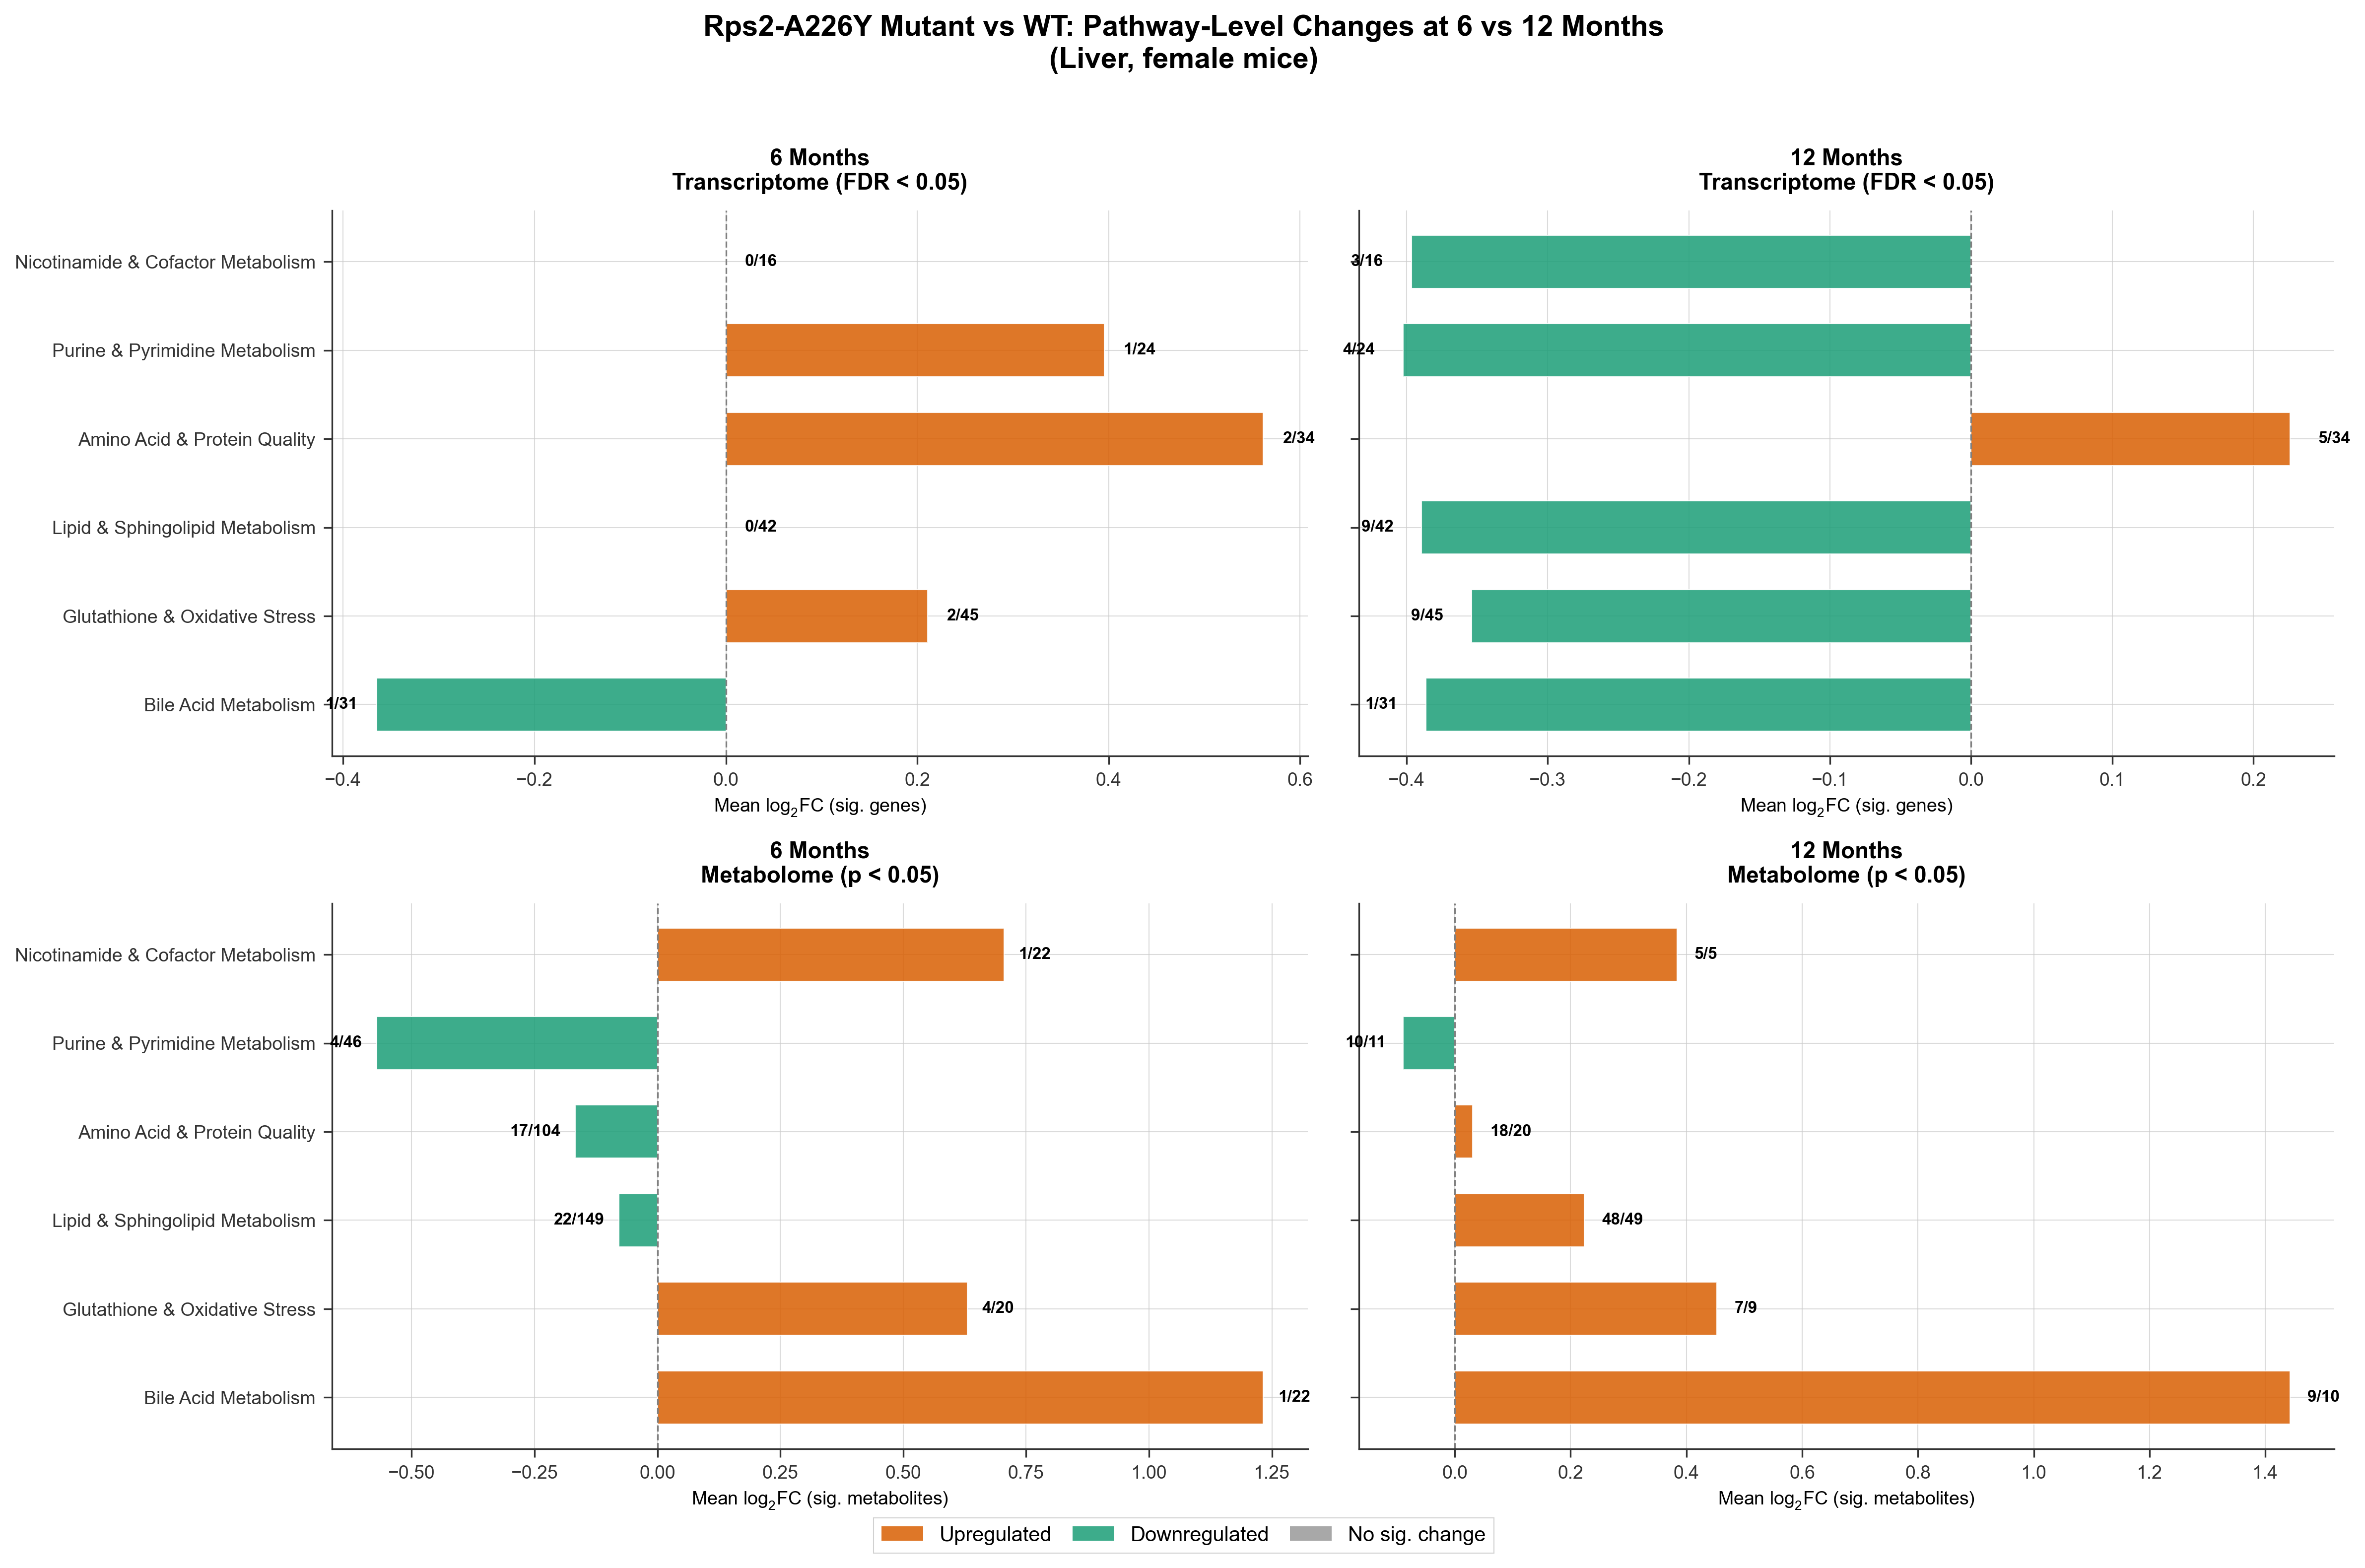

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.style.use("science_machine")

# Figure 3: Comparative butterfly plot - 6m vs 12m side by side
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey='row')

pathway_order = [
    'Bile Acid Metabolism',
    'Glutathione & Oxidative Stress', 
    'Lipid & Sphingolipid Metabolism',
    'Amino Acid & Protein Quality',
    'Purine & Pyrimidine Metabolism',
    'Nicotinamide & Cofactor Metabolism'
]

y_pos = np.arange(len(pathway_order))

for col_idx, (pdf, timepoint) in enumerate([(pdf_6m, '6 Months'), (pdf_12m, '12 Months')]):
    pdf_ordered = pdf.set_index('Pathway').loc[pathway_order].reset_index()
    
    # Left: Transcriptome
    ax1 = axes[0, col_idx]
    colors_gene = ['#d95f02' if v > 0 else ('#1b9e77' if v < 0 else '#999999') for v in pdf_ordered['mean_gene_log2FC']]
    bars1 = ax1.barh(y_pos, pdf_ordered['mean_gene_log2FC'], color=colors_gene, edgecolor='white', height=0.6, alpha=0.85)
    for i, (fc, n_sig, n_total) in enumerate(zip(pdf_ordered['mean_gene_log2FC'], pdf_ordered['n_genes_sig'], pdf_ordered['n_genes_found'])):
        if fc != 0:
            offset = 0.02 if fc > 0 else -0.02
            ha = 'left' if fc > 0 else 'right'
        else:
            offset = 0.02
            ha = 'left'
        ax1.text(fc + offset, i, f'{n_sig}/{n_total}', va='center', ha=ha, fontsize=8, fontweight='bold')
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(pathway_order, fontsize=9)
    ax1.axvline(0, color='grey', linewidth=0.8, linestyle='--')
    ax1.set_title(f'{timepoint}\nTranscriptome (FDR < 0.05)', fontsize=11, fontweight='bold')
    ax1.set_xlabel(r'Mean $log_2$FC (sig. genes)', fontsize=9)
    
    # Right: Metabolome
    ax2 = axes[1, col_idx]
    colors_met = ['#d95f02' if v > 0 else ('#1b9e77' if v < 0 else '#999999') for v in pdf_ordered['mean_met_log2FC']]
    bars2 = ax2.barh(y_pos, pdf_ordered['mean_met_log2FC'], color=colors_met, edgecolor='white', height=0.6, alpha=0.85)
    for i, (fc, n_sig, n_total) in enumerate(zip(pdf_ordered['mean_met_log2FC'], pdf_ordered['n_met_sig'], pdf_ordered['n_met_found'])):
        if fc != 0:
            offset = 0.03 if fc > 0 else -0.03
            ha = 'left' if fc > 0 else 'right'
        else:
            offset = 0.03
            ha = 'left'
        ax2.text(fc + offset, i, f'{n_sig}/{n_total}', va='center', ha=ha, fontsize=8, fontweight='bold')
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(pathway_order, fontsize=9)
    ax2.axvline(0, color='grey', linewidth=0.8, linestyle='--')
    ax2.set_title(f'{timepoint}\nMetabolome (p < 0.05)', fontsize=11, fontweight='bold')
    ax2.set_xlabel(r'Mean $log_2$FC (sig. metabolites)', fontsize=9)

legend_elements = [Patch(facecolor='#d95f02', alpha=0.85, label='Upregulated'),
                   Patch(facecolor='#1b9e77', alpha=0.85, label='Downregulated'),
                   Patch(facecolor='#999999', alpha=0.85, label='No sig. change')]
fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=10, frameon=True, bbox_to_anchor=(0.5, -0.02))

fig.suptitle('Rps2-A226Y Mutant vs WT: Pathway-Level Changes at 6 vs 12 Months\n(Liver, female mice)', 
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('figures/figure3_6m_pathway_overview.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure3_6m_pathway_overview.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# Build detailed data for both timepoints for comparison
def build_detail_data(tx_df, met_df, met_fc_col, met_pval_col, tx_fdr_thresh=0.05, met_p_thresh=0.05):
    detail_data = []
    for pathway, info in pathway_gene_map.items():
        genes = info['genes']
        met_subpaths = info['metabolites']
        
        tx_genes = tx_df[tx_df['gene_name'].str.lower().isin([g.lower() for g in genes])]
        sig_genes = tx_genes[tx_genes['fdr'] < tx_fdr_thresh].copy()
        for _, row in sig_genes.iterrows():
            detail_data.append({
                'Pathway': pathway, 'Name': row['gene_name'], 'Type': 'Gene',
                'log2FC': row['log2 Ratio'], 'pval': row['pValue'], 'fdr_or_pval': row['fdr']
            })
        
        met_sub = met_df[met_df['Sub Pathway'].isin(met_subpaths)]
        sig_met = met_sub[met_sub[met_pval_col] < met_p_thresh].copy()
        for _, row in sig_met.iterrows():
            detail_data.append({
                'Pathway': pathway, 'Name': row['Biochem'], 'Type': 'Metabolite',
                'log2FC': row[met_fc_col], 'pval': row[met_pval_col], 'fdr_or_pval': row[met_pval_col]
            })
    return pd.DataFrame(detail_data)

detail_6m = build_detail_data(tx6_clean, met6, 'log2FC', 'p-value')
detail_12m = build_detail_data(tx12_clean, met12_clean, 'log2FC', 'p-value')

print("6m detail entries:", len(detail_6m))
print(detail_6m.groupby(['Pathway', 'Type']).size())
print("\n12m detail entries:", len(detail_12m))
print(detail_12m.groupby(['Pathway', 'Type']).size())


6m detail entries: 55
Pathway                             Type      
Amino Acid & Protein Quality        Gene           2
                                    Metabolite    17
Bile Acid Metabolism                Gene           1
                                    Metabolite     1
Glutathione & Oxidative Stress      Gene           2
                                    Metabolite     4
Lipid & Sphingolipid Metabolism     Metabolite    22
Nicotinamide & Cofactor Metabolism  Metabolite     1
Purine & Pyrimidine Metabolism      Gene           1
                                    Metabolite     4
dtype: int64

12m detail entries: 128
Pathway                             Type      
Amino Acid & Protein Quality        Gene           5
                                    Metabolite    18
Bile Acid Metabolism                Gene           1
                                    Metabolite     9
Glutathione & Oxidative Stress      Gene           9
                                    Metabolite     

In [ ]:
# Now create Figure 4: A comprehensive comparison figure
# I'll create a paired dot plot showing log2FC at 6m vs 12m for metabolites that appear in both datasets
# This will show the temporal trajectory

# Find common metabolites between 6m and 12m
# First, let's match metabolites by name
met6_all = met6[['Biochem', 'FC', 'log2FC', 'p-value', 'Sub Pathway', 'Super Pathway']].copy()
met6_all.columns = ['Biochem', 'FC_6m', 'log2FC_6m', 'pval_6m', 'Sub Pathway', 'Super Pathway']

met12_all = met12_clean[['Biochem', '12 Months', 'log2FC', 'p-value', 'Sub Pathway', 'Super Pathway']].copy()
met12_all.columns = ['Biochem', 'FC_12m', 'log2FC_12m', 'pval_12m', 'Sub Pathway', 'Super Pathway']

# Merge on biochemical name
met_merged = met6_all.merge(met12_all[['Biochem', 'FC_12m', 'log2FC_12m', 'pval_12m']], on='Biochem', how='inner')
print(f"Common metabolites: {len(met_merged)}")
print(f"Sig at 6m only: {((met_merged['pval_6m'] < 0.05) & (met_merged['pval_12m'] >= 0.05)).sum()}")
print(f"Sig at 12m only: {((met_merged['pval_6m'] >= 0.05) & (met_merged['pval_12m'] < 0.05)).sum()}")
print(f"Sig at both: {((met_merged['pval_6m'] < 0.05) & (met_merged['pval_12m'] < 0.05)).sum()}")
print(f"Sig at neither: {((met_merged['pval_6m'] >= 0.05) & (met_merged['pval_12m'] >= 0.05)).sum()}")


Common metabolites: 173
Sig at 6m only: 1
Sig at 12m only: 132
Sig at both: 25
Sig at neither: 15


In [ ]:
# Similarly for genes
tx_merged = tx6_clean[['gene_name', 'log2 Ratio', 'pValue', 'fdr']].merge(
    tx12_clean[['gene_name', 'log2 Ratio', 'pValue', 'fdr']], 
    on='gene_name', suffixes=('_6m', '_12m')
)
print(f"Common genes: {len(tx_merged)}")
print(f"Sig at 6m only: {((tx_merged['fdr_6m'] < 0.05) & (tx_merged['fdr_12m'] >= 0.05)).sum()}")
print(f"Sig at 12m only: {((tx_merged['fdr_6m'] >= 0.05) & (tx_merged['fdr_12m'] < 0.05)).sum()}")
print(f"Sig at both: {((tx_merged['fdr_6m'] < 0.05) & (tx_merged['fdr_12m'] < 0.05)).sum()}")

# Correlation of fold changes
from scipy.stats import pearsonr, spearmanr
r_met, p_met = pearsonr(met_merged['log2FC_6m'], met_merged['log2FC_12m'])
rho_met, p_rho_met = spearmanr(met_merged['log2FC_6m'], met_merged['log2FC_12m'])
print(f"\nMetabolite FC correlation (6m vs 12m): Pearson r={r_met:.3f} (p={p_met:.2e}), Spearman ρ={rho_met:.3f}")

r_tx, p_tx = pearsonr(tx_merged['log2 Ratio_6m'], tx_merged['log2 Ratio_12m'])
rho_tx, p_rho_tx = spearmanr(tx_merged['log2 Ratio_6m'], tx_merged['log2 Ratio_12m'])
print(f"Gene FC correlation (6m vs 12m): Pearson r={r_tx:.3f} (p={p_tx:.2e}), Spearman ρ={rho_tx:.3f}")


Common genes: 22660
Sig at 6m only: 139
Sig at 12m only: 1747
Sig at both: 118

Metabolite FC correlation (6m vs 12m): Pearson r=0.462 (p=1.55e-10), Spearman ρ=0.430
Gene FC correlation (6m vs 12m): Pearson r=0.456 (p=0.00e+00), Spearman ρ=0.376


/app/backend/.venv/lib/python3.11/site-packages/matplotlib/pyplot.py:1250: UserWarning: Text labels overlap each other. This should be avoided.
  res = fig.savefig(*args, **kwargs)  # type: ignore[func-returns-value]


/app/backend/.venv/lib/python3.11/site-packages/matplotlib/pyplot.py:1250: UserWarning: Text labels overlap each other. This should be avoided.
  res = fig.savefig(*args, **kwargs)  # type: ignore[func-returns-value]


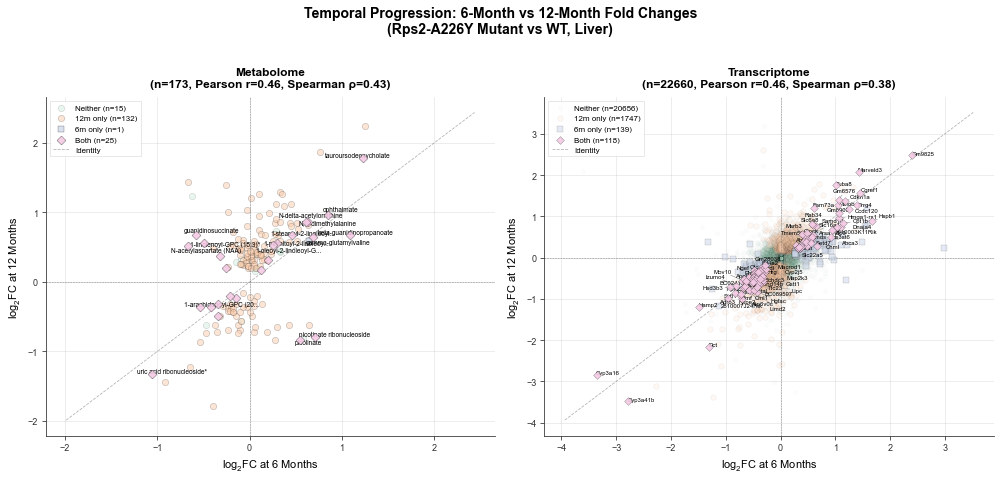

In [ ]:
# Create Figure 4: Scatter plots of 6m vs 12m fold changes for both omics
# This is a key comparison figure

plt.style.use("science_machine")
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))

# --- Panel A: Metabolites ---
ax1 = axes[0]

# Assign pathway colors to metabolites
pathway_colors = {
    'Primary Bile Acid Metabolism': '#e41a1c',
    'Secondary Bile Acid Metabolism': '#e41a1c',
    'Glutathione Metabolism': '#377eb8',
    'Gamma-glutamyl Amino Acid': '#377eb8',
    'Sphingomyelins': '#4daf4a',
    'Ceramides': '#4daf4a',
    'Phosphatidylcholine (PC)': '#984ea3',
    'Phosphatidylethanolamine (PE)': '#984ea3',
    'Endocannabinoid': '#ff7f00',
    'Nicotinate and Nicotinamide Metabolism': '#a65628',
}

# Categorize significance
met_merged['sig_cat'] = 'Neither'
met_merged.loc[(met_merged['pval_6m'] < 0.05) & (met_merged['pval_12m'] < 0.05), 'sig_cat'] = 'Both'
met_merged.loc[(met_merged['pval_6m'] < 0.05) & (met_merged['pval_12m'] >= 0.05), 'sig_cat'] = '6m only'
met_merged.loc[(met_merged['pval_6m'] >= 0.05) & (met_merged['pval_12m'] < 0.05), 'sig_cat'] = '12m only'

# Plot non-significant first
for cat, marker, alpha, zorder in [('Neither', 'o', 0.3, 1), ('12m only', 'o', 0.5, 2), 
                                     ('6m only', 's', 0.7, 3), ('Both', 'D', 0.9, 4)]:
    sub = met_merged[met_merged['sig_cat'] == cat]
    ax1.scatter(sub['log2FC_6m'], sub['log2FC_12m'], s=40, alpha=alpha, marker=marker, 
               edgecolors='black', linewidth=0.3, zorder=zorder, label=f'{cat} (n={len(sub)})')

# Label key metabolites (significant at both timepoints with large FC)
from adjustText import adjust_text
texts = []
label_mets = met_merged[(met_merged['sig_cat'] == 'Both') & 
                         ((met_merged['log2FC_12m'].abs() > 0.5) | (met_merged['log2FC_6m'].abs() > 0.5))]
for _, row in label_mets.iterrows():
    name = row['Biochem']
    if len(name) > 25:
        name = name[:22] + '...'
    texts.append(ax1.text(row['log2FC_6m'], row['log2FC_12m'], name, fontsize=6.5))

adjust_text(texts, ax=ax1, arrowprops=dict(arrowstyle='-', color='grey', lw=0.5))

# Add reference lines
ax1.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax1.axvline(0, color='grey', linewidth=0.5, linestyle='--')
lims = [min(ax1.get_xlim()[0], ax1.get_ylim()[0]), max(ax1.get_xlim()[1], ax1.get_ylim()[1])]
ax1.plot(lims, lims, 'k--', alpha=0.3, linewidth=0.8, label='Identity')

ax1.set_xlabel(r'$log_2$FC at 6 Months', fontsize=11)
ax1.set_ylabel(r'$log_2$FC at 12 Months', fontsize=11)
ax1.set_title(f'Metabolome\n(n={len(met_merged)}, Pearson r={r_met:.2f}, Spearman ρ={rho_met:.2f})', 
              fontsize=12, fontweight='bold')
ax1.legend(fontsize=8, loc='upper left', frameon=True)

# --- Panel B: Transcriptome ---
ax2 = axes[1]

tx_merged['sig_cat'] = 'Neither'
tx_merged.loc[(tx_merged['fdr_6m'] < 0.05) & (tx_merged['fdr_12m'] < 0.05), 'sig_cat'] = 'Both'
tx_merged.loc[(tx_merged['fdr_6m'] < 0.05) & (tx_merged['fdr_12m'] >= 0.05), 'sig_cat'] = '6m only'
tx_merged.loc[(tx_merged['fdr_6m'] >= 0.05) & (tx_merged['fdr_12m'] < 0.05), 'sig_cat'] = '12m only'

for cat, marker, alpha, zorder in [('Neither', 'o', 0.05, 1), ('12m only', 'o', 0.15, 2), 
                                     ('6m only', 's', 0.5, 3), ('Both', 'D', 0.9, 4)]:
    sub = tx_merged[tx_merged['sig_cat'] == cat]
    ax2.scatter(sub['log2 Ratio_6m'], sub['log2 Ratio_12m'], s=15 if cat == 'Neither' else 30, 
               alpha=alpha, marker=marker, edgecolors='black', linewidth=0.2, zorder=zorder,
               label=f'{cat} (n={len(sub)})')

# Label key genes
texts2 = []
label_genes = tx_merged[(tx_merged['sig_cat'] == 'Both') & 
                          ((tx_merged['log2 Ratio_12m'].abs() > 0.5) | (tx_merged['log2 Ratio_6m'].abs() > 0.5))]
for _, row in label_genes.iterrows():
    texts2.append(ax2.text(row['log2 Ratio_6m'], row['log2 Ratio_12m'], row['gene_name'], fontsize=6))

adjust_text(texts2, ax=ax2, arrowprops=dict(arrowstyle='-', color='grey', lw=0.5))

ax2.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax2.axvline(0, color='grey', linewidth=0.5, linestyle='--')
lims2 = [min(ax2.get_xlim()[0], ax2.get_ylim()[0]), max(ax2.get_xlim()[1], ax2.get_ylim()[1])]
ax2.plot(lims2, lims2, 'k--', alpha=0.3, linewidth=0.8, label='Identity')

ax2.set_xlabel(r'$log_2$FC at 6 Months', fontsize=11)
ax2.set_ylabel(r'$log_2$FC at 12 Months', fontsize=11)
ax2.set_title(f'Transcriptome\n(n={len(tx_merged)}, Pearson r={r_tx:.2f}, Spearman ρ={rho_tx:.2f})', 
              fontsize=12, fontweight='bold')
ax2.legend(fontsize=8, loc='upper left', frameon=True)

fig.suptitle('Temporal Progression: 6-Month vs 12-Month Fold Changes\n(Rps2-A226Y Mutant vs WT, Liver)', 
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('figures/figure4_temporal_scatter.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure4_temporal_scatter.pdf', bbox_inches='tight', facecolor='white')
plt.show()


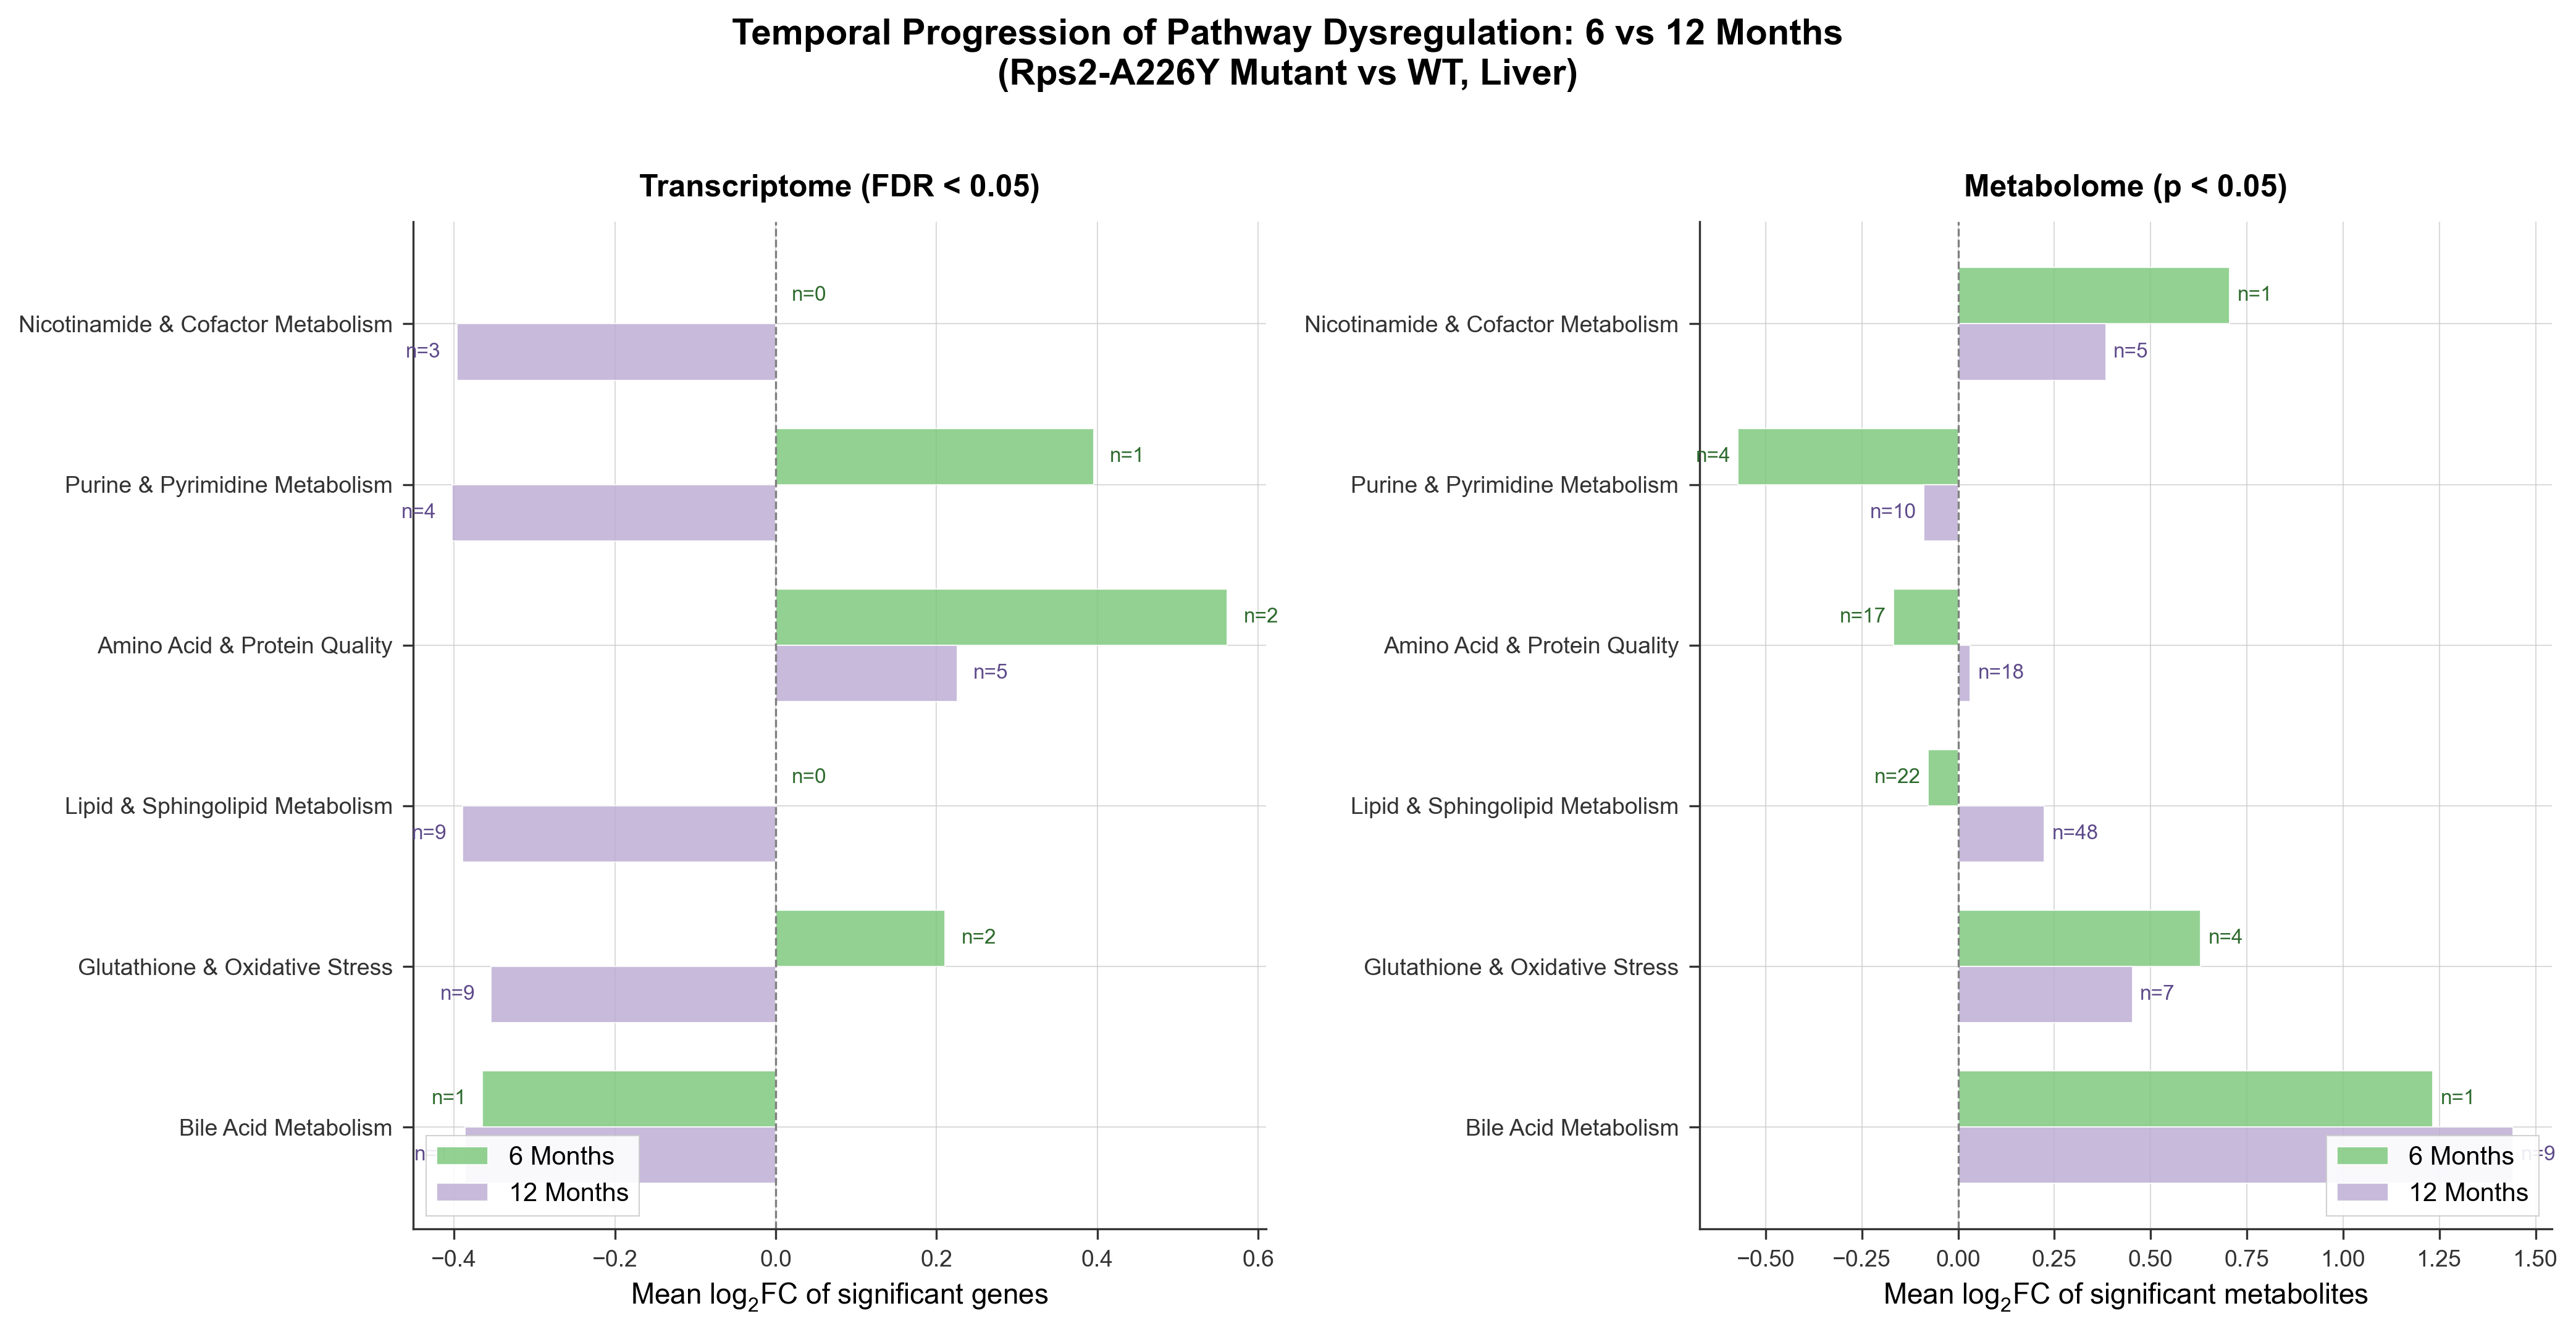

In [ ]:
# Create Figure 5: Pathway-level temporal comparison - a clean paired bar chart
plt.style.use("science_machine")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

pathway_order = [
    'Bile Acid Metabolism',
    'Glutathione & Oxidative Stress', 
    'Lipid & Sphingolipid Metabolism',
    'Amino Acid & Protein Quality',
    'Purine & Pyrimidine Metabolism',
    'Nicotinamide & Cofactor Metabolism'
]

y_pos = np.arange(len(pathway_order))
bar_width = 0.35

# --- Panel A: Transcriptome comparison ---
ax1 = axes[0]
pdf_6m_ord = pdf_6m.set_index('Pathway').loc[pathway_order]
pdf_12m_ord = pdf_12m.set_index('Pathway').loc[pathway_order]

bars_6m = ax1.barh(y_pos + bar_width/2, pdf_6m_ord['mean_gene_log2FC'], bar_width, 
                    color='#7fc97f', edgecolor='white', alpha=0.85, label='6 Months')
bars_12m = ax1.barh(y_pos - bar_width/2, pdf_12m_ord['mean_gene_log2FC'], bar_width, 
                     color='#beaed4', edgecolor='white', alpha=0.85, label='12 Months')

# Annotate with n sig
for i in range(len(pathway_order)):
    fc6 = pdf_6m_ord.iloc[i]['mean_gene_log2FC']
    fc12 = pdf_12m_ord.iloc[i]['mean_gene_log2FC']
    n6 = int(pdf_6m_ord.iloc[i]['n_genes_sig'])
    n12 = int(pdf_12m_ord.iloc[i]['n_genes_sig'])
    
    offset6 = 0.02 if fc6 >= 0 else -0.02
    ha6 = 'left' if fc6 >= 0 else 'right'
    offset12 = 0.02 if fc12 >= 0 else -0.02
    ha12 = 'left' if fc12 >= 0 else 'right'
    
    ax1.text(fc6 + offset6, i + bar_width/2, f'n={n6}', va='center', ha=ha6, fontsize=8, color='#2d6a2d')
    ax1.text(fc12 + offset12, i - bar_width/2, f'n={n12}', va='center', ha=ha12, fontsize=8, color='#5e4a8a')

ax1.set_yticks(y_pos)
ax1.set_yticklabels(pathway_order, fontsize=9)
ax1.axvline(0, color='grey', linewidth=0.8, linestyle='--')
ax1.set_xlabel(r'Mean $log_2$FC of significant genes', fontsize=11)
ax1.set_title('Transcriptome (FDR < 0.05)', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10, loc='lower left')

# --- Panel B: Metabolome comparison ---
ax2 = axes[1]

bars_6m_m = ax2.barh(y_pos + bar_width/2, pdf_6m_ord['mean_met_log2FC'], bar_width, 
                      color='#7fc97f', edgecolor='white', alpha=0.85, label='6 Months')
bars_12m_m = ax2.barh(y_pos - bar_width/2, pdf_12m_ord['mean_met_log2FC'], bar_width, 
                       color='#beaed4', edgecolor='white', alpha=0.85, label='12 Months')

for i in range(len(pathway_order)):
    fc6 = pdf_6m_ord.iloc[i]['mean_met_log2FC']
    fc12 = pdf_12m_ord.iloc[i]['mean_met_log2FC']
    n6 = int(pdf_6m_ord.iloc[i]['n_met_sig'])
    n12 = int(pdf_12m_ord.iloc[i]['n_met_sig'])
    
    offset6 = 0.02 if fc6 >= 0 else -0.02
    ha6 = 'left' if fc6 >= 0 else 'right'
    offset12 = 0.02 if fc12 >= 0 else -0.02
    ha12 = 'left' if fc12 >= 0 else 'right'
    
    ax2.text(fc6 + offset6, i + bar_width/2, f'n={n6}', va='center', ha=ha6, fontsize=8, color='#2d6a2d')
    ax2.text(fc12 + offset12, i - bar_width/2, f'n={n12}', va='center', ha=ha12, fontsize=8, color='#5e4a8a')

ax2.set_yticks(y_pos)
ax2.set_yticklabels(pathway_order, fontsize=9)
ax2.axvline(0, color='grey', linewidth=0.8, linestyle='--')
ax2.set_xlabel(r'Mean $log_2$FC of significant metabolites', fontsize=11)
ax2.set_title('Metabolome (p < 0.05)', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10, loc='lower right')

fig.suptitle('Temporal Progression of Pathway Dysregulation: 6 vs 12 Months\n(Rps2-A226Y Mutant vs WT, Liver)', 
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('figures/figure5_temporal_pathway_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure5_temporal_pathway_comparison.pdf', bbox_inches='tight', facecolor='white')
plt.show()


/app/backend/.venv/lib/python3.11/site-packages/matplotlib/pyplot.py:1250: UserWarning: Text labels overlap each other. This should be avoided.
  res = fig.savefig(*args, **kwargs)  # type: ignore[func-returns-value]


/app/backend/.venv/lib/python3.11/site-packages/matplotlib/pyplot.py:1250: UserWarning: Text labels overlap each other. This should be avoided.
  res = fig.savefig(*args, **kwargs)  # type: ignore[func-returns-value]


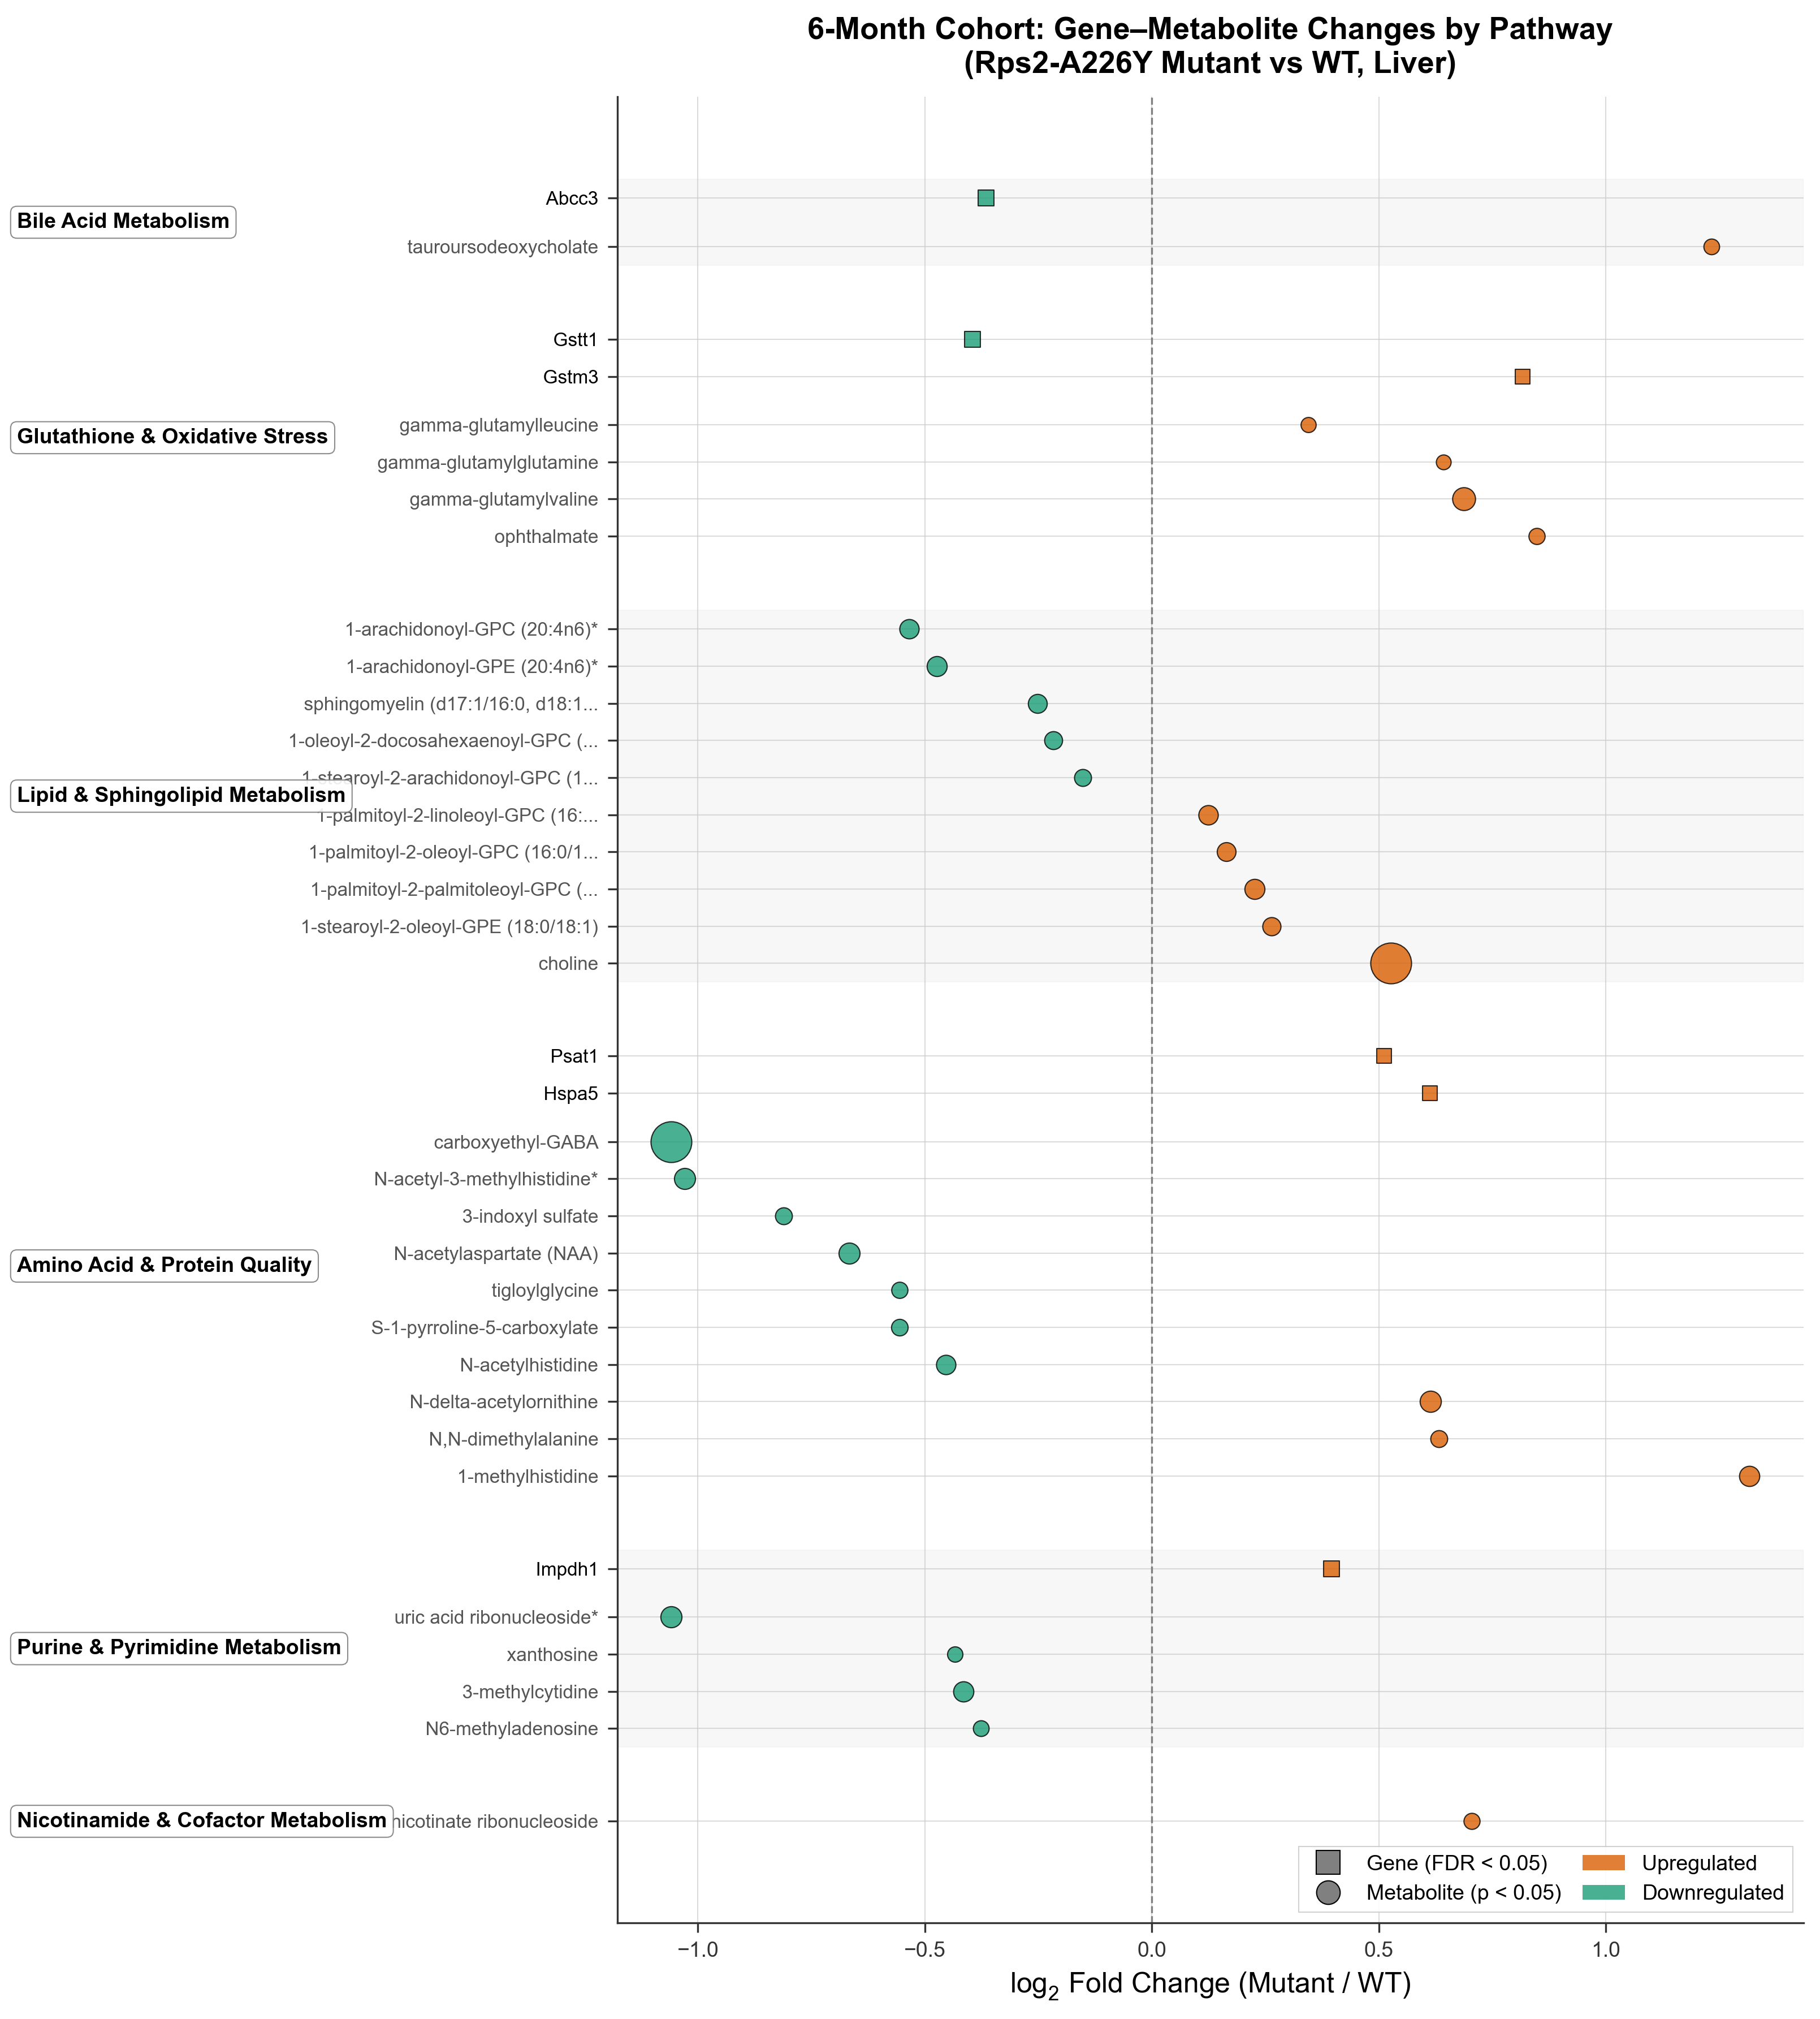

In [ ]:
# Figure 6: 6m Gene-Metabolite Dot Plot (equivalent to Figure 2)
# Filter to top 10 metabolites per pathway for readability
filtered_6m = []
for pathway in detail_6m['Pathway'].unique():
    sub = detail_6m[detail_6m['Pathway'] == pathway]
    genes = sub[sub['Type'] == 'Gene']
    mets = sub[sub['Type'] == 'Metabolite'].nsmallest(10, 'pval')
    filtered_6m.append(genes)
    filtered_6m.append(mets)

filt_6m = pd.concat(filtered_6m).reset_index(drop=True)

plt.style.use("science_machine")
fig, ax = plt.subplots(figsize=(12, 12))

y_counter = 0
y_ticks = []
y_labels = []
y_colors = []
pathway_boundaries = []

for pi, pathway in enumerate(pathway_order):
    sub = filt_6m[filt_6m['Pathway'] == pathway].copy()
    if len(sub) == 0:
        # Still show pathway name
        pathway_boundaries.append((y_counter - 0.5, y_counter + 0.5, pathway))
        y_counter += 2
        continue
    
    pathway_start = y_counter
    
    genes = sub[sub['Type'] == 'Gene'].sort_values('log2FC', ascending=True)
    mets = sub[sub['Type'] == 'Metabolite'].sort_values('log2FC', ascending=True)
    
    for _, row in genes.iterrows():
        size = min(max(-np.log10(row['fdr_or_pval']) * 30, 30), 300)
        color = '#d95f02' if row['log2FC'] > 0 else '#1b9e77'
        ax.scatter(row['log2FC'], y_counter, s=size, c=color, alpha=0.8, 
                  edgecolors='black', linewidth=0.5, marker='s', zorder=3)
        y_ticks.append(y_counter)
        y_labels.append(f"  {row['Name']}")
        y_colors.append('black')
        y_counter += 1
    
    if len(genes) > 0 and len(mets) > 0:
        y_counter += 0.3
    
    for _, row in mets.iterrows():
        size = min(max(-np.log10(max(row['fdr_or_pval'], 1e-10)) * 30, 30), 300)
        color = '#d95f02' if row['log2FC'] > 0 else '#1b9e77'
        name = row['Name']
        if len(name) > 35:
            name = name[:32] + '...'
        ax.scatter(row['log2FC'], y_counter, s=size, c=color, alpha=0.8,
                  edgecolors='black', linewidth=0.5, marker='o', zorder=3)
        y_ticks.append(y_counter)
        y_labels.append(f"  {name}")
        y_colors.append('#555555')
        y_counter += 1
    
    pathway_end = y_counter - 1
    pathway_boundaries.append((pathway_start - 0.5, pathway_end + 0.5, pathway))
    y_counter += 1.5

colors_bg = ['#f0f0f0', '#ffffff'] * 3
for i, (ymin, ymax, pname) in enumerate(pathway_boundaries):
    ax.axhspan(ymin, ymax, color=colors_bg[i], alpha=0.5, zorder=0)
    ax.text(-2.5, (ymin + ymax) / 2, pname, fontsize=9, fontweight='bold',
            va='center', ha='left',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='grey', alpha=0.9))

ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels, fontsize=8)
for tick, color in zip(ax.get_yticklabels(), y_colors):
    tick.set_color(color)

ax.axvline(0, color='grey', linewidth=0.8, linestyle='--', zorder=1)
ax.set_xlabel(r'$log_2$ Fold Change (Mutant / WT)', fontsize=12)

legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='grey', markersize=10, markeredgecolor='black', label='Gene (FDR < 0.05)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markersize=10, markeredgecolor='black', label='Metabolite (p < 0.05)'),
    Patch(facecolor='#d95f02', alpha=0.8, label='Upregulated'),
    Patch(facecolor='#1b9e77', alpha=0.8, label='Downregulated'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=True, ncol=2)
ax.set_title('6-Month Cohort: Gene–Metabolite Changes by Pathway\n(Rps2-A226Y Mutant vs WT, Liver)', fontsize=13, fontweight='bold')
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('figures/figure6_6m_gene_metabolite_detail.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure6_6m_gene_metabolite_detail.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# Key metabolites: those significant at both timepoints
both_sig = met_merged[(met_merged['pval_6m'] < 0.05) & (met_merged['pval_12m'] < 0.05)].copy()
both_sig['direction_change'] = ''
both_sig.loc[(both_sig['log2FC_6m'] > 0) & (both_sig['log2FC_12m'] > 0), 'direction_change'] = 'Up→Up'
both_sig.loc[(both_sig['log2FC_6m'] < 0) & (both_sig['log2FC_12m'] < 0), 'direction_change'] = 'Down→Down'
both_sig.loc[(both_sig['log2FC_6m'] > 0) & (both_sig['log2FC_12m'] < 0), 'direction_change'] = 'Up→Down'
both_sig.loc[(both_sig['log2FC_6m'] < 0) & (both_sig['log2FC_12m'] > 0), 'direction_change'] = 'Down→Up'
both_sig['amplification'] = both_sig['log2FC_12m'] / both_sig['log2FC_6m']

print("Metabolites significant at BOTH timepoints (sorted by 12m FC):")
print(both_sig[['Biochem', 'FC_6m', 'FC_12m', 'pval_6m', 'pval_12m', 'Sub Pathway', 'direction_change']].sort_values('FC_12m', ascending=False).to_string(index=False))


Metabolites significant at BOTH timepoints (sorted by 12m FC):
                                    Biochem  FC_6m  FC_12m  pval_6m  pval_12m                                          Sub Pathway direction_change
                      tauroursodeoxycholate   2.35    3.45   0.0333    0.0038                       Secondary Bile Acid Metabolism            Up→Up
                                ophthalmate   1.80    1.94   0.0265    0.0048                               Glutathione Metabolism            Up→Up
                        N,N-dimethylalanine   1.55    1.82   0.0191    0.0013                     Alanine and Aspartate Metabolism            Up→Up
                    N-delta-acetylornithine   1.53    1.82   0.0020    0.0000          Urea cycle; Arginine and Proline Metabolism            Up→Up
                         guanidinosuccinate   0.67    1.60   0.0491    0.0146                   Guanidino and Acetamido Metabolism          Down→Up
     1-stearoyl-2-linoleoyl-GPI (18:0/18:2)   1.3

In [ ]:
# Key genes: those significant at both timepoints
both_sig_genes = tx_merged[(tx_merged['fdr_6m'] < 0.05) & (tx_merged['fdr_12m'] < 0.05)].copy()
both_sig_genes['direction_change'] = ''
both_sig_genes.loc[(both_sig_genes['log2 Ratio_6m'] > 0) & (both_sig_genes['log2 Ratio_12m'] > 0), 'direction_change'] = 'Up→Up'
both_sig_genes.loc[(both_sig_genes['log2 Ratio_6m'] < 0) & (both_sig_genes['log2 Ratio_12m'] < 0), 'direction_change'] = 'Down→Down'
both_sig_genes.loc[(both_sig_genes['log2 Ratio_6m'] > 0) & (both_sig_genes['log2 Ratio_12m'] < 0), 'direction_change'] = 'Up→Down'
both_sig_genes.loc[(both_sig_genes['log2 Ratio_6m'] < 0) & (both_sig_genes['log2 Ratio_12m'] > 0), 'direction_change'] = 'Down→Up'

print(f"Genes significant at both timepoints: {len(both_sig_genes)}")
print(f"Direction consistency:")
print(both_sig_genes['direction_change'].value_counts())

# Show top genes by absolute FC at 12m
print("\nTop genes significant at both (sorted by |12m FC|):")
both_sig_genes_sorted = both_sig_genes.reindex(both_sig_genes['log2 Ratio_12m'].abs().sort_values(ascending=False).index)
print(both_sig_genes_sorted[['gene_name', 'log2 Ratio_6m', 'log2 Ratio_12m', 'fdr_6m', 'fdr_12m', 'direction_change']].head(25).to_string(index=False))


Genes significant at both timepoints: 118
Direction consistency:
direction_change
Down→Down    71
Up→Up        47
Name: count, dtype: int64

Top genes significant at both (sorted by |12m FC|):
    gene_name  log2 Ratio_6m  log2 Ratio_12m       fdr_6m      fdr_12m direction_change
     Cyp3a41b        -2.7770         -3.4730 2.491000e-02 1.438000e-02        Down→Down
      Cyp3a16        -3.3580         -2.8330 2.341000e-02 4.809000e-02        Down→Down
       Gm9825         2.3980          2.4850 3.635000e-08 2.847000e-08            Up→Up
          Dct        -1.3120         -2.1590 2.562000e-02 1.292000e-03        Down→Down
     Marveld3         1.4250          2.0800 1.140000e-02 2.306000e-03            Up→Up
        Tuba8         1.0220          1.7490 3.162000e-03 1.125000e-02            Up→Up
       Cgref1         1.4470          1.5630 4.503000e-02 2.578000e-03            Up→Up
       Gm6576         1.0640          1.3970 2.641000e-02 6.431000e-04            Up→Up
       Cdkn1a  

In [ ]:
# Interesting: 100% directional consistency (no reversals) for genes sig at both timepoints!
# Let's also check key pathway genes specifically

# Check our pathway genes at both timepoints
print("Key pathway genes - comparison across timepoints:")
print("="*80)
for pathway, info in pathway_gene_map.items():
    genes = info['genes']
    pw_genes = tx_merged[tx_merged['gene_name'].str.lower().isin([g.lower() for g in genes])]
    pw_sig_either = pw_genes[(pw_genes['fdr_6m'] < 0.05) | (pw_genes['fdr_12m'] < 0.05)]
    if len(pw_sig_either) > 0:
        print(f"\n{pathway}:")
        for _, row in pw_sig_either.sort_values('fdr_12m').iterrows():
            sig6 = '*' if row['fdr_6m'] < 0.05 else ' '
            sig12 = '*' if row['fdr_12m'] < 0.05 else ' '
            print(f"  {row['gene_name']:12s}  6m: {row['log2 Ratio_6m']:+.3f}{sig6}  12m: {row['log2 Ratio_12m']:+.3f}{sig12}")


Key pathway genes - comparison across timepoints:

Bile Acid Metabolism:
  Slc27a5       6m: -0.296   12m: -0.386*
  Abcc3         6m: -0.365*  12m: -0.458 

Glutathione & Oxidative Stress:
  Prdx4         6m: -0.157   12m: -0.337*
  Gstm6         6m: -0.248   12m: -0.470*
  Gstt1         6m: -0.395*  12m: -0.648*
  Mgst3         6m: -0.024   12m: -0.744*
  Gpx1          6m: -0.100   12m: -0.418*
  Gsta3         6m: -0.160   12m: -0.474*
  Gstm4         6m: +0.144   12m: +0.416*
  Mgst1         6m: -0.208   12m: -0.248*
  Sod1          6m: -0.161   12m: -0.263*
  Gstm3         6m: +0.817*  12m: +0.191 

Lipid & Sphingolipid Metabolism:
  Srebf1        6m: -0.822   12m: -1.211*
  Fads1         6m: -0.018   12m: -0.604*
  Fasn          6m: -0.269   12m: -0.674*
  Srebf2        6m: +0.023   12m: -0.469*
  Sgms1         6m: +0.034   12m: +0.308*
  Acer2         6m: +0.261   12m: +0.348*
  Elovl3        6m: -0.039   12m: -1.142*
  Sptlc1        6m: +0.116   12m: +0.203*
  Asah1         6m: 

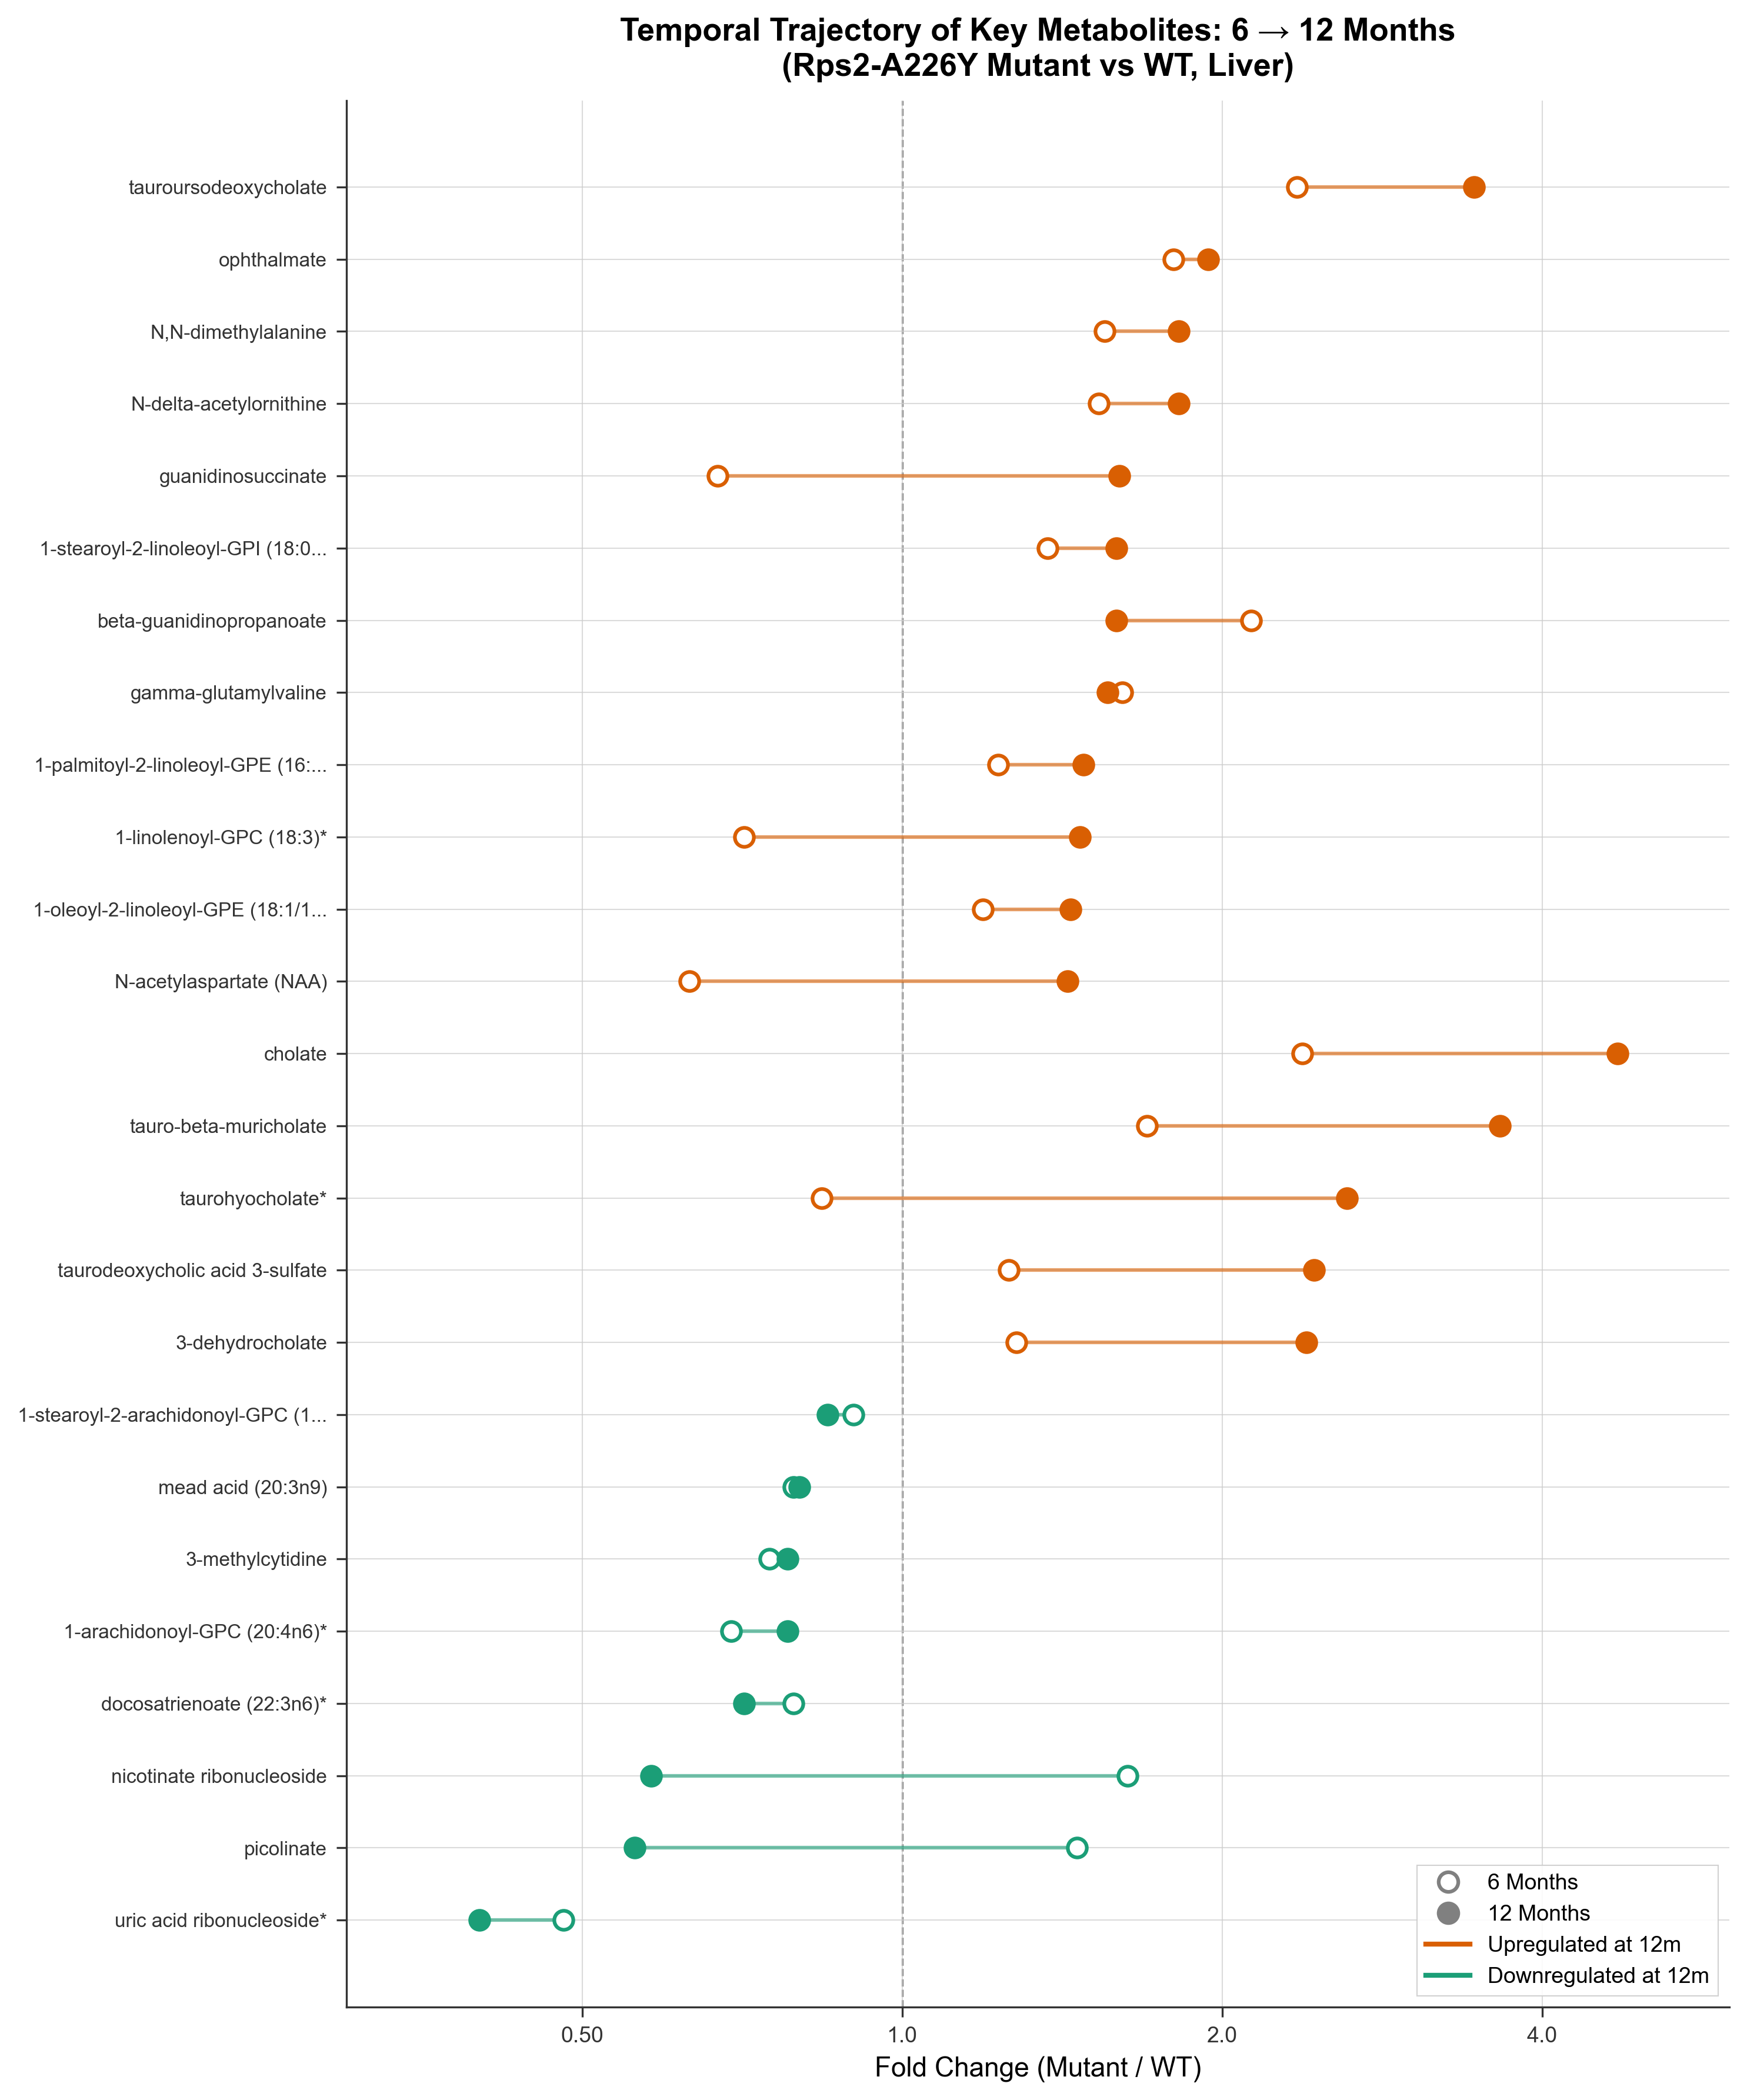

In [ ]:
# Figure 7: Temporal trajectory of key metabolites and genes
# Show FC at 6m and 12m as connected dots (slope chart / dumbbell plot)

plt.style.use("science_machine")

# Select key metabolites that are significant at both timepoints
key_mets = both_sig.sort_values('FC_12m', ascending=False)[['Biochem', 'FC_6m', 'FC_12m', 'Sub Pathway']].copy()
# Also add some key metabolites only significant at 12m (bile acids)
bile_acids_12m_only = met_merged[
    (met_merged['pval_12m'] < 0.05) & 
    (met_merged['pval_6m'] >= 0.05) & 
    (met_merged['Sub Pathway'].isin(['Primary Bile Acid Metabolism', 'Secondary Bile Acid Metabolism']))
].sort_values('FC_12m', ascending=False).head(5)

# Combine
key_display = pd.concat([
    key_mets.head(12),
    bile_acids_12m_only[['Biochem', 'FC_6m', 'FC_12m', 'Sub Pathway']],
    key_mets.tail(8)
]).drop_duplicates(subset='Biochem')

fig, ax = plt.subplots(figsize=(10, 12))

y_pos = np.arange(len(key_display))

for i, (_, row) in enumerate(key_display.iterrows()):
    fc6 = row['FC_6m']
    fc12 = row['FC_12m']
    
    # Color based on direction at 12m
    if fc12 > 1:
        color = '#d95f02'
    elif fc12 < 1:
        color = '#1b9e77'
    else:
        color = 'grey'
    
    # Draw line connecting 6m to 12m
    ax.plot([fc6, fc12], [i, i], color=color, linewidth=1.5, alpha=0.6, zorder=1)
    # 6m point (open circle)
    ax.scatter(fc6, i, s=60, facecolors='white', edgecolors=color, linewidth=1.5, zorder=3, marker='o')
    # 12m point (filled circle)
    ax.scatter(fc12, i, s=60, facecolors=color, edgecolors=color, linewidth=1.5, zorder=3, marker='o')

ax.set_yticks(y_pos)
# Truncate long names
labels = []
for name in key_display['Biochem']:
    if len(name) > 35:
        name = name[:32] + '...'
    labels.append(name)
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()

ax.axvline(1, color='grey', linewidth=0.8, linestyle='--', zorder=0)
ax.set_xlabel('Fold Change (Mutant / WT)', fontsize=11)
ax.set_xscale('log', base=2)
ax.set_xlim(0.3, 6)

# Custom x-ticks
import matplotlib.ticker as ticker
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:.1f}' if x >= 1 else f'{x:.2f}'))

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='white', markeredgecolor='grey', 
           markersize=8, markeredgewidth=1.5, label='6 Months'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markeredgecolor='grey', 
           markersize=8, markeredgewidth=1.5, label='12 Months'),
    Line2D([0], [0], color='#d95f02', linewidth=2, label='Upregulated at 12m'),
    Line2D([0], [0], color='#1b9e77', linewidth=2, label='Downregulated at 12m'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=True)

ax.set_title('Temporal Trajectory of Key Metabolites: 6 → 12 Months\n(Rps2-A226Y Mutant vs WT, Liver)', 
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/figure7_metabolite_trajectory.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure7_metabolite_trajectory.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# Create Figure 8: Enrichment analysis comparison - bubble plot of g:Profiler results
# Focus on KEGG and Reactome terms that appear at either or both timepoints

# Get KEGG/REAC terms
kegg_6m_terms = set(kegg_6m['name'].values)
kegg_12m_terms = set(kegg_12m['name'].values)

# Common terms
common = kegg_6m_terms & kegg_12m_terms
only_6m = kegg_6m_terms - kegg_12m_terms
only_12m = kegg_12m_terms - kegg_6m_terms

print(f"KEGG/Reactome enriched terms:")
print(f"  Common: {len(common)}")
print(f"  6m only: {len(only_6m)}")
print(f"  12m only: {len(only_12m)}")
print(f"\nCommon terms: {common}")
print(f"\n6m only terms: {only_6m}")


KEGG/Reactome enriched terms:
  Common: 4
  6m only: 9
  12m only: 95

Common terms: {'Biological oxidations', 'Metabolism', 'Metabolism of amino acids and derivatives', 'Metabolic pathways'}

6m only terms: {'Xenobiotics', 'Aspirin ADME', 'Proline catabolism', 'HSP90 chaperone cycle for steroid hormone receptors (SHR) in the presence of ligand', 'Drug ADME', 'Peroxisomal protein import', 'Biosynthesis of maresin-like SPMs', 'Protein localization', 'Lysine catabolism'}


In [ ]:
# Create a comprehensive enrichment comparison figure
# Select interesting terms from both timepoints

# Combine and select key terms
selected_terms = [
    'Metabolic pathways',
    'Metabolism',
    'Metabolism of amino acids and derivatives',
    'Biological oxidations',
    'Metabolism of lipids',
    'Cholesterol biosynthesis',
    'Metabolism of steroids',
    'Fatty acid metabolism',
    'Carbon metabolism',
    'Peroxisome',
    'AMPK signaling pathway',
    'Insulin signaling pathway',
    'Ubiquitin mediated proteolysis',
    'Biosynthesis of amino acids',
    'Biosynthesis of cofactors',
    'Protein localization',
    'Drug ADME',
    'Xenobiotics',
    'Alcoholic liver disease',
    'Hepatocellular carcinoma',
]

# Build comparison dataframe
comparison_data = []
for term in selected_terms:
    row = {'Term': term}
    
    # 6m
    match_6m = kegg_6m[kegg_6m['name'] == term]
    if len(match_6m) > 0:
        row['pval_6m'] = match_6m.iloc[0]['p_value']
        row['n_genes_6m'] = match_6m.iloc[0]['intersection_size']
        row['neg_log10p_6m'] = -np.log10(match_6m.iloc[0]['p_value'])
    else:
        row['pval_6m'] = 1
        row['n_genes_6m'] = 0
        row['neg_log10p_6m'] = 0
    
    # 12m
    match_12m = kegg_12m[kegg_12m['name'] == term]
    if len(match_12m) > 0:
        row['pval_12m'] = match_12m.iloc[0]['p_value']
        row['n_genes_12m'] = match_12m.iloc[0]['intersection_size']
        row['neg_log10p_12m'] = -np.log10(match_12m.iloc[0]['p_value'])
    else:
        row['pval_12m'] = 1
        row['n_genes_12m'] = 0
        row['neg_log10p_12m'] = 0
    
    comparison_data.append(row)

comp_df = pd.DataFrame(comparison_data)
# Only keep terms enriched at at least one timepoint
comp_df = comp_df[(comp_df['pval_6m'] < 0.05) | (comp_df['pval_12m'] < 0.05)]
comp_df = comp_df.sort_values('neg_log10p_12m', ascending=True)

print(comp_df[['Term', 'pval_6m', 'n_genes_6m', 'pval_12m', 'n_genes_12m']].to_string(index=False))


                                     Term      pval_6m  n_genes_6m     pval_12m  n_genes_12m
                     Protein localization 1.839852e-02           8 1.000000e+00            0
                                Drug ADME 1.942935e-02           8 1.000000e+00            0
                              Xenobiotics 3.468734e-02           4 1.000000e+00            0
                    Biological oxidations 4.149984e-02          10 4.734460e-03           43
                  Alcoholic liver disease 1.000000e+00           0 4.604692e-03           25
                    Fatty acid metabolism 1.000000e+00           0 4.268243e-03           37
           Ubiquitin mediated proteolysis 1.000000e+00           0 3.050713e-03           27
                   AMPK signaling pathway 1.000000e+00           0 3.050713e-03           24
                Biosynthesis of cofactors 1.000000e+00           0 2.136032e-03           28
                 Hepatocellular carcinoma 1.000000e+00           0 2.0

/tmp/ipykernel_1226/3797695348.py:16: UserWarning: You passed a edgecolor/edgecolors ('#7fc97f') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(0.1, i + offset, s=20, c='white', edgecolors='#7fc97f', linewidth=1, zorder=3,
/tmp/ipykernel_1226/3797695348.py:26: UserWarning: You passed a edgecolor/edgecolors ('#beaed4') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(0.1, i - offset, s=20, c='white', edgecolors='#beaed4', linewidth=1, zorder=3,


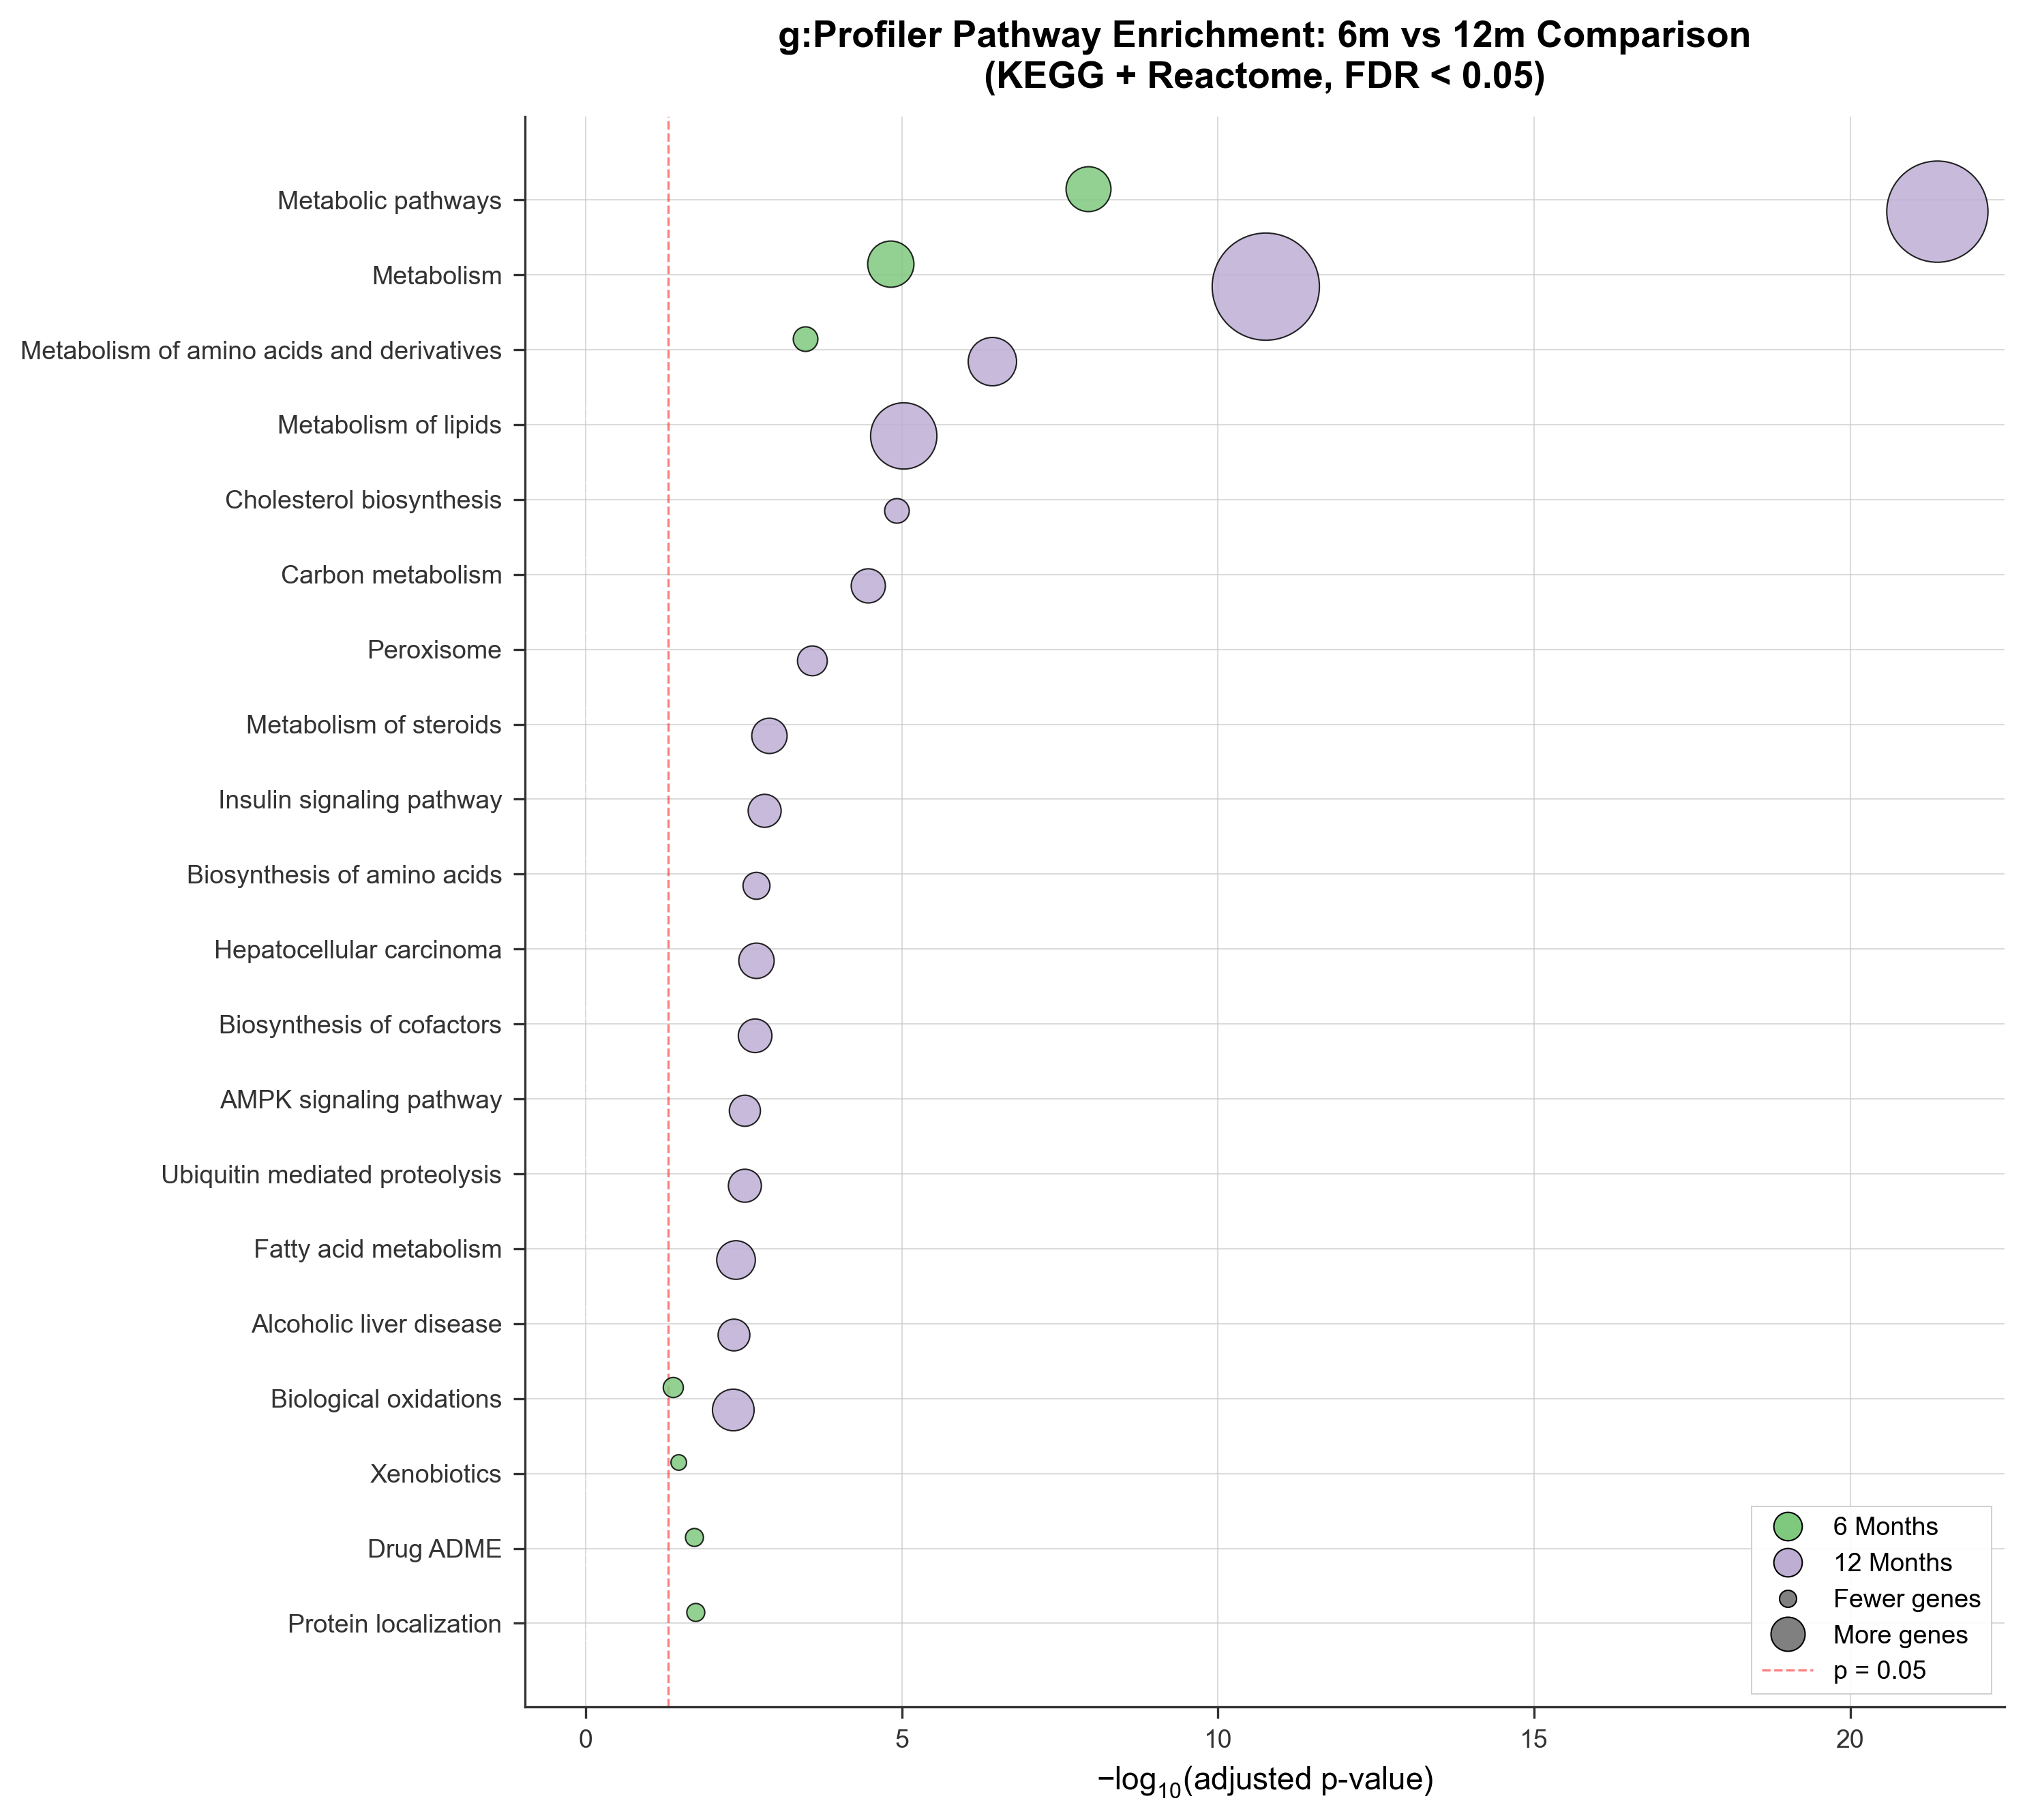

In [ ]:
# Figure 8: Enrichment comparison dot plot
plt.style.use("science_machine")

fig, ax = plt.subplots(figsize=(10, 9))

y_pos = np.arange(len(comp_df))
offset = 0.15

# 6m dots
for i, (_, row) in enumerate(comp_df.iterrows()):
    if row['pval_6m'] < 0.05:
        size = max(row['n_genes_6m'] * 5, 30)
        ax.scatter(row['neg_log10p_6m'], i + offset, s=size, c='#7fc97f', edgecolors='black', 
                  linewidth=0.5, zorder=3, alpha=0.85)
    else:
        ax.scatter(0.1, i + offset, s=20, c='white', edgecolors='#7fc97f', linewidth=1, zorder=3, 
                  marker='x', alpha=0.5)

# 12m dots
for i, (_, row) in enumerate(comp_df.iterrows()):
    if row['pval_12m'] < 0.05:
        size = max(row['n_genes_12m'] * 5, 30)
        ax.scatter(row['neg_log10p_12m'], i - offset, s=size, c='#beaed4', edgecolors='black', 
                  linewidth=0.5, zorder=3, alpha=0.85)
    else:
        ax.scatter(0.1, i - offset, s=20, c='white', edgecolors='#beaed4', linewidth=1, zorder=3, 
                  marker='x', alpha=0.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(comp_df['Term'].values, fontsize=9)
ax.set_xlabel(r'$-log_{10}$(adjusted p-value)', fontsize=11)
ax.axvline(-np.log10(0.05), color='red', linewidth=0.8, linestyle='--', alpha=0.5, label='p = 0.05')

# Legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#7fc97f', markersize=10, 
           markeredgecolor='black', label='6 Months'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#beaed4', markersize=10, 
           markeredgecolor='black', label='12 Months'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markersize=6, 
           markeredgecolor='black', label='Fewer genes'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markersize=12, 
           markeredgecolor='black', label='More genes'),
    Line2D([0], [0], color='red', linewidth=0.8, linestyle='--', alpha=0.5, label='p = 0.05'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=True)

ax.set_title('g:Profiler Pathway Enrichment: 6m vs 12m Comparison\n(KEGG + Reactome, FDR < 0.05)', 
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/figure8_enrichment_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure8_enrichment_comparison.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# Figure 9: Metabolite QEA comparison between 6m and 12m
# Run QEA for 12m as well (using the full 6m dataset as reference for pathway sizes)
met12_qea = metabolite_pathway_qea(met12_clean, fc_col='log2FC', pathway_col='Sub Pathway', min_size=3)

# Merge QEA results
qea_merged = met6_qea[['Pathway', 'n', 'mean_log2FC', 'wilcoxon_p', 'wilcoxon_fdr']].merge(
    met12_qea[['Pathway', 'n', 'mean_log2FC', 'wilcoxon_p', 'wilcoxon_fdr']], 
    on='Pathway', suffixes=('_6m', '_12m'), how='outer'
)

# Select pathways significant at either timepoint
qea_sig = qea_merged[(qea_merged['wilcoxon_p_6m'] < 0.05) | (qea_merged['wilcoxon_p_12m'].fillna(1) < 0.05)]
qea_sig = qea_sig.sort_values('wilcoxon_p_6m')

print("Metabolite QEA comparison (pathways significant at either timepoint):")
print(qea_sig[['Pathway', 'mean_log2FC_6m', 'wilcoxon_p_6m', 'mean_log2FC_12m', 'wilcoxon_p_12m']].to_string(index=False))


Metabolite QEA comparison (pathways significant at either timepoint):
                                             Pathway  mean_log2FC_6m  wilcoxon_p_6m  mean_log2FC_12m  wilcoxon_p_12m
                             Fatty Acid, Monohydroxy        0.268263       0.000093              NaN             NaN
                           Fatty Acid, Dicarboxylate        0.200906       0.000133         0.601718        0.050587
                        Primary Bile Acid Metabolism        0.471873       0.000545         1.511267        0.001897
                                         Glycosyl PE       -0.378990       0.002051              NaN             NaN
               Purine Metabolism, Adenine containing       -0.261545       0.003031              NaN             NaN
   Long Chain Polyunsaturated Fatty Acid (n3 and n6)       -0.206172       0.006594        -0.097376        0.399010
                     Pantothenate and CoA Metabolism       -0.830183       0.007523              NaN           

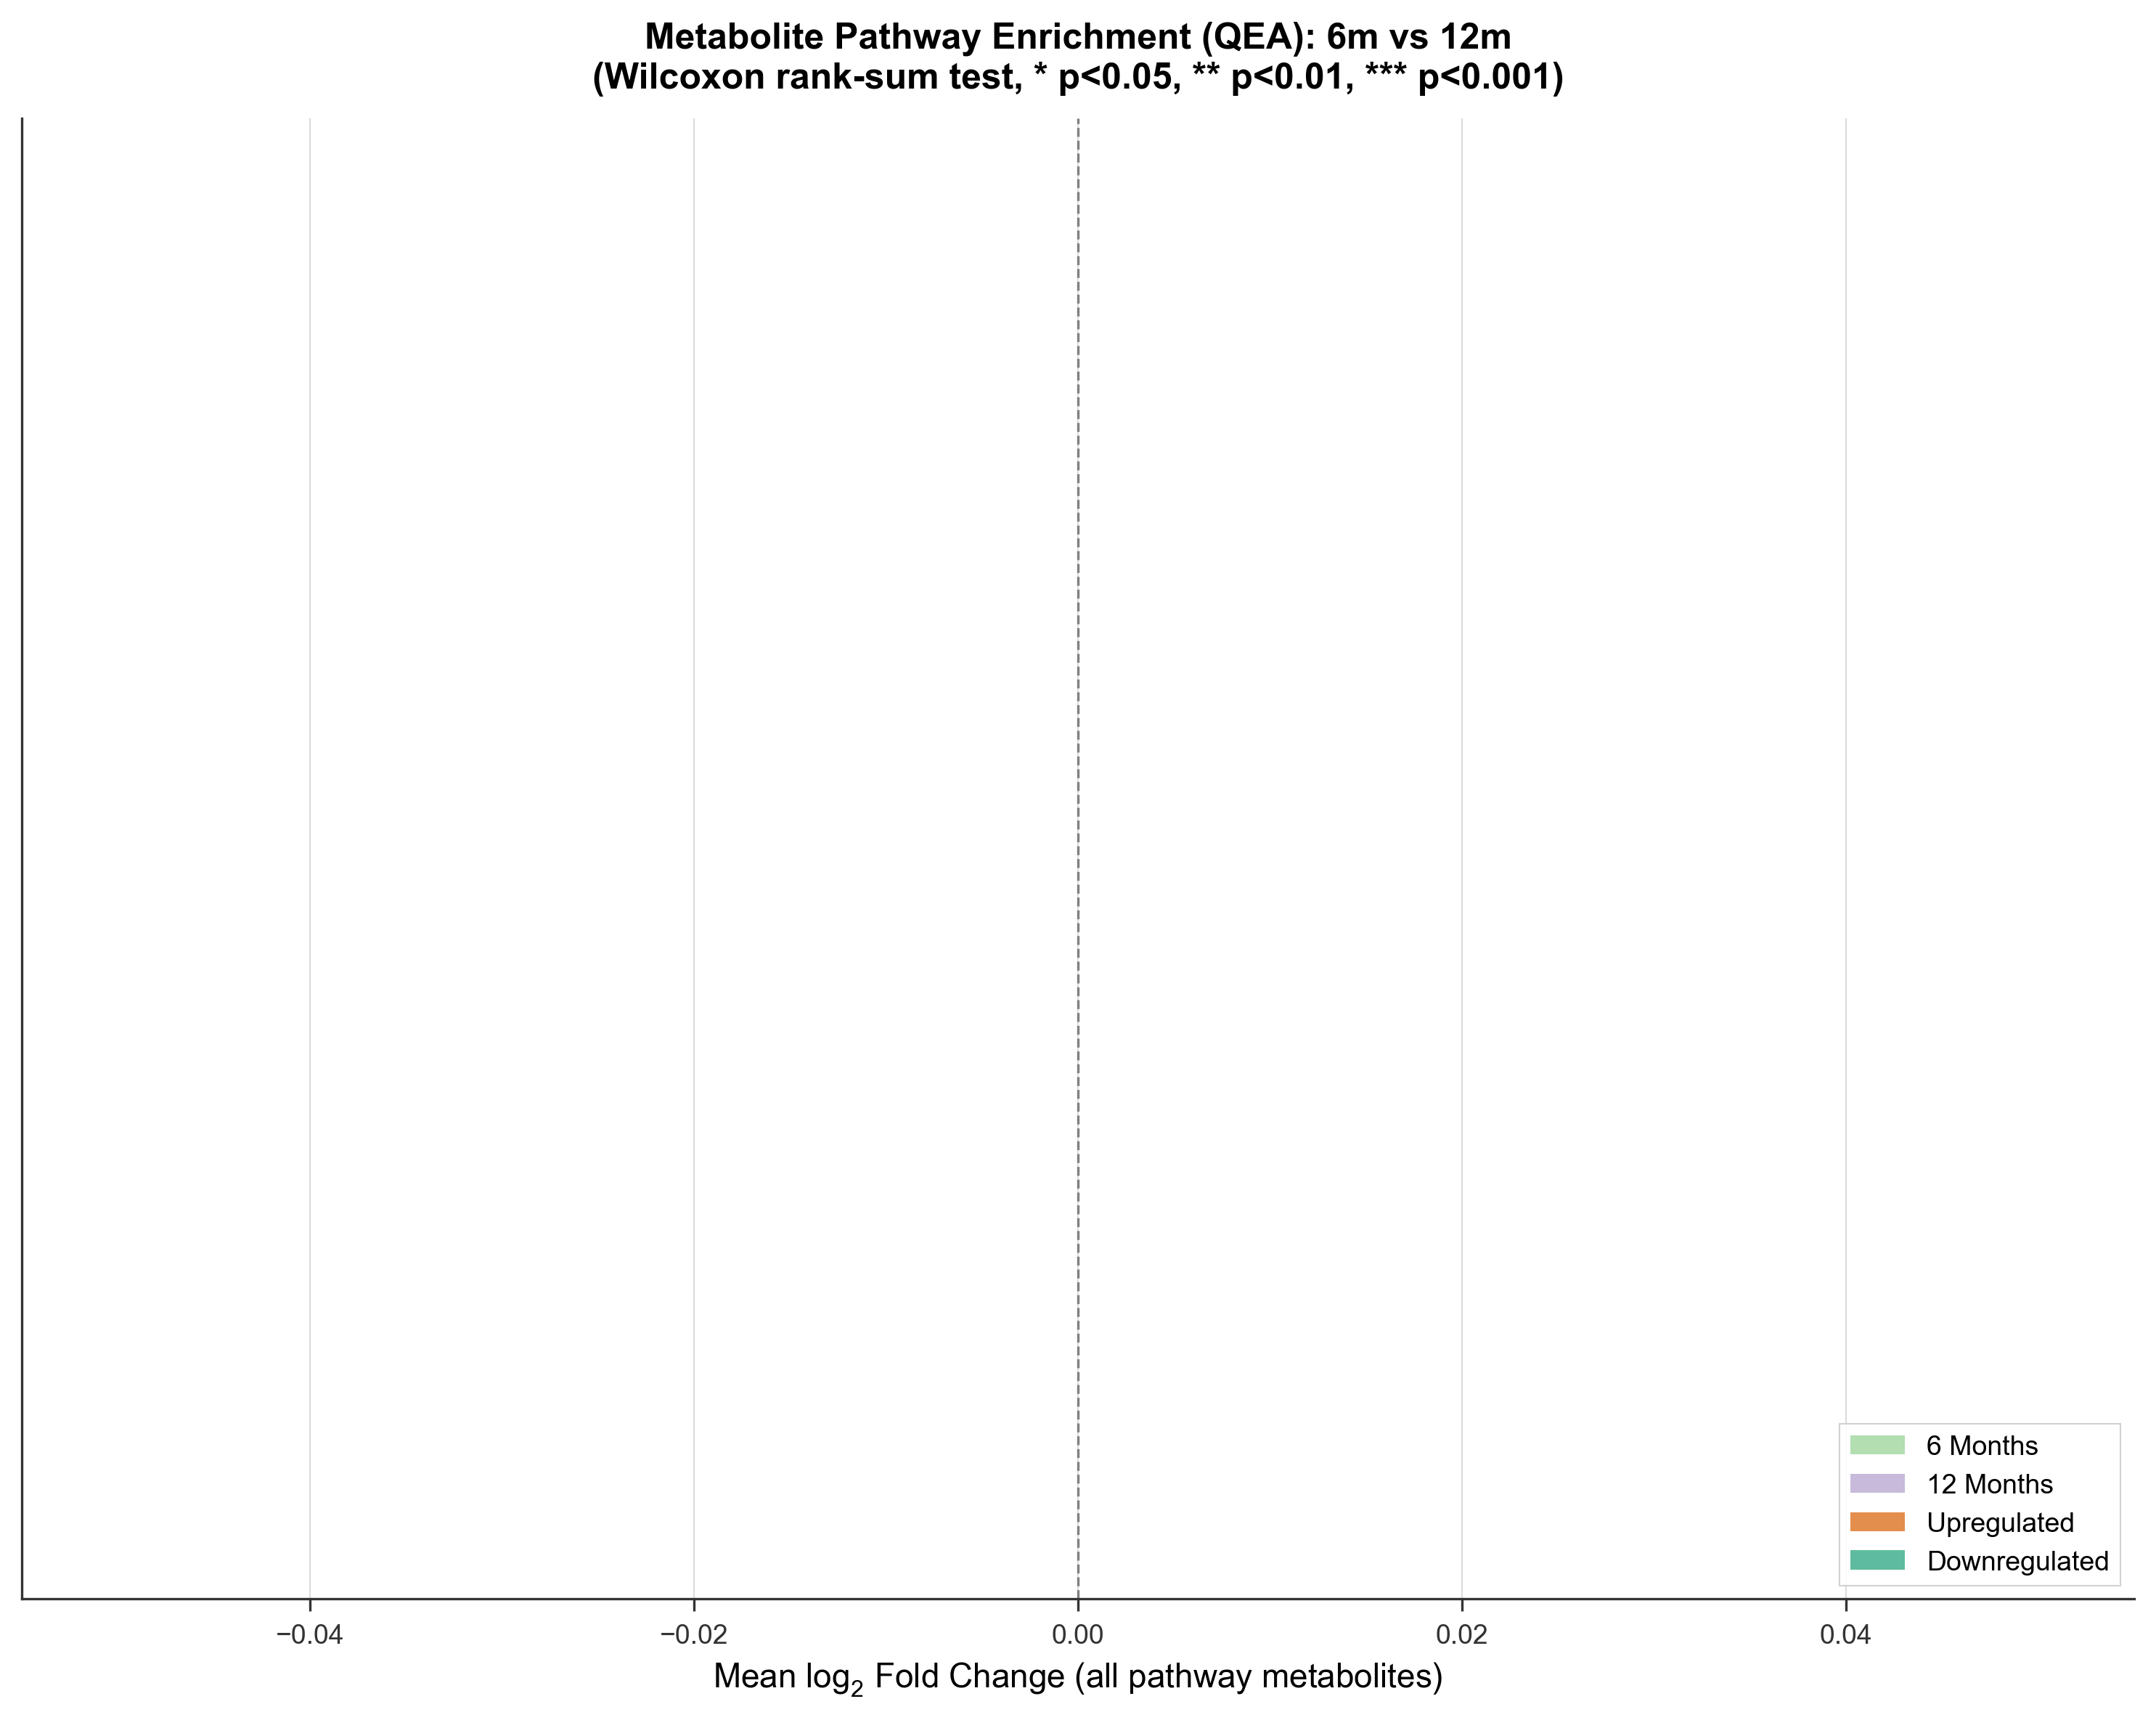

In [ ]:
# Create a clean metabolite pathway enrichment comparison
plt.style.use("science_machine")

# Select key pathways for display
key_met_pathways = [
    'Primary Bile Acid Metabolism',
    'Secondary Bile Acid Metabolism',
    'Fatty Acid, Monohydroxy',
    'Fatty Acid, Dicarboxylate',
    'Gamma-glutamyl Amino Acid',
    'Phosphatidylethanolamine (PE)',
    'Lysophospholipid',
    'Endocannabinoid',
    'Long Chain Polyunsaturated Fatty Acid (n3 and n6)',
    'Purine Metabolism, (Hypo)Xanthine/Inosine containing',
    'Purine Metabolism, Adenine containing',
    'Pantothenate and CoA Metabolism',
    'Phospholipid Metabolism',
    'Monoacylglycerol',
]

fig, ax = plt.subplots(figsize=(10, 8))

# Filter and order
plot_data = qea_merged[qea_merged['Pathway'].isin(key_met_pathways)].copy()
plot_data = plot_data.set_index('Pathway').loc[[p for p in key_met_pathways if p in plot_data.index.values]].reset_index()

y_pos = np.arange(len(plot_data))
bar_width = 0.35

# 6m bars
colors_6m = ['#d95f02' if v > 0 else '#1b9e77' for v in plot_data['mean_log2FC_6m'].fillna(0)]
ax.barh(y_pos + bar_width/2, plot_data['mean_log2FC_6m'].fillna(0), bar_width, 
        color=colors_6m, edgecolor='white', alpha=0.6, label='6 Months')

# 12m bars
colors_12m = ['#d95f02' if v > 0 else '#1b9e77' for v in plot_data['mean_log2FC_12m'].fillna(0)]
ax.barh(y_pos - bar_width/2, plot_data['mean_log2FC_12m'].fillna(0), bar_width, 
        color=colors_12m, edgecolor='white', alpha=0.85)

# Add hatching for 12m to distinguish
for i, (_, row) in enumerate(plot_data.iterrows()):
    fc12 = row['mean_log2FC_12m']
    if not np.isnan(fc12):
        color = '#d95f02' if fc12 > 0 else '#1b9e77'
        ax.barh(i - bar_width/2, fc12, bar_width, color=color, edgecolor='white', alpha=0.85)

# Add significance markers
for i, (_, row) in enumerate(plot_data.iterrows()):
    # 6m
    p6 = row['wilcoxon_p_6m']
    if not np.isnan(p6) and p6 < 0.05:
        fc6 = row['mean_log2FC_6m']
        offset = 0.02 if fc6 > 0 else -0.02
        ha = 'left' if fc6 > 0 else 'right'
        stars = '***' if p6 < 0.001 else ('**' if p6 < 0.01 else '*')
        ax.text(fc6 + offset, i + bar_width/2, stars, va='center', ha=ha, fontsize=9, color='#2d6a2d', fontweight='bold')
    
    # 12m
    p12 = row['wilcoxon_p_12m']
    if not np.isnan(p12) and p12 < 0.05:
        fc12 = row['mean_log2FC_12m']
        offset = 0.02 if fc12 > 0 else -0.02
        ha = 'left' if fc12 > 0 else 'right'
        stars = '***' if p12 < 0.001 else ('**' if p12 < 0.01 else '*')
        ax.text(fc12 + offset, i - bar_width/2, stars, va='center', ha=ha, fontsize=9, color='#5e4a8a', fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data['Pathway'].values, fontsize=9)
ax.axvline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel(r'Mean $log_2$ Fold Change (all pathway metabolites)', fontsize=11)

legend_elements = [
    Patch(facecolor='#7fc97f', alpha=0.6, label='6 Months'),
    Patch(facecolor='#beaed4', alpha=0.85, label='12 Months'),
    Patch(facecolor='#d95f02', alpha=0.7, label='Upregulated'),
    Patch(facecolor='#1b9e77', alpha=0.7, label='Downregulated'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=True)

ax.set_title('Metabolite Pathway Enrichment (QEA): 6m vs 12m\n(Wilcoxon rank-sum test, * p<0.05, ** p<0.01, *** p<0.001)', 
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/figure9_metabolite_qea_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure9_metabolite_qea_comparison.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# The issue is that 12m metabolomics only has 173 pre-filtered metabolites
# while 6m has 738. The QEA for 12m is unreliable because the background is already filtered.
# Let me instead create a focused comparison using the common metabolites

# Better approach: use the merged metabolite data to compare pathway-level changes
# Group by Sub Pathway and compute mean log2FC at each timepoint

pathway_comparison = met_merged.groupby('Sub Pathway').agg(
    n=('Biochem', 'count'),
    mean_log2FC_6m=('log2FC_6m', 'mean'),
    mean_log2FC_12m=('log2FC_12m', 'mean'),
    n_sig_6m=('pval_6m', lambda x: (x < 0.05).sum()),
    n_sig_12m=('pval_12m', lambda x: (x < 0.05).sum()),
).reset_index()

# Only pathways with >= 3 metabolites
pathway_comparison = pathway_comparison[pathway_comparison['n'] >= 3].sort_values('mean_log2FC_12m', ascending=False)
print(pathway_comparison.to_string(index=False))


                                      Sub Pathway  n  mean_log2FC_6m  mean_log2FC_12m  n_sig_6m  n_sig_12m
                     Primary Bile Acid Metabolism  4        0.733911         1.511267         0          4
                   Secondary Bile Acid Metabolism  6        0.177259         1.362126         1          5
                        Fatty Acid, Dicarboxylate  9        0.265081         0.601718         0          7
                        Gamma-glutamyl Amino Acid  6        0.321819         0.571525         2          5
                             Glutamate Metabolism  3        0.164203         0.493422         0          3
                                        Ceramides  3       -0.100972         0.461831         0          3
                    Phosphatidylethanolamine (PE)  5        0.220576         0.415433         3          5
                                      Plasmalogen  5        0.076924         0.385940         0          5
                                   Sp

/tmp/ipykernel_1226/1995183095.py:53: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/app/backend/projects/pipeline_planner/plotting_hooks.py:76: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.draw()


/app/backend/projects/pipeline_planner/plotting_hooks.py:95: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  _orig_savefig(self, folder_path / f"{ix}.png", *args, **png_kwargs)


/app/backend/projects/pipeline_planner/plotting_hooks.py:101: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  _orig_savefig(self, folder_path / f"{ix}.pdf", *args, **pdf_kwargs)


/app/backend/projects/pipeline_planner/plotting_hooks.py:107: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  _orig_savefig(self, folder_path / f"{ix}.svg", *args, **svg_kwargs)


/app/backend/projects/pipeline_planner/plotting_hooks.py:133: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  result = _orig_savefig(self, fname, *args, **kwargs)


...

/app/backend/projects/pipeline_planner/plotting_hooks.py:95: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  _orig_savefig(self, folder_path / f"{ix}.png", *args, **png_kwargs)


/app/backend/projects/pipeline_planner/plotting_hooks.py:101: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  _orig_savefig(self, folder_path / f"{ix}.pdf", *args, **pdf_kwargs)


/app/backend/projects/pipeline_planner/plotting_hooks.py:107: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  _orig_savefig(self, folder_path / f"{ix}.svg", *args, **svg_kwargs)
/app/backend/projects/pipeline_planner/plotting_hooks.py:133: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  result = _orig_savefig(self, fname, *args, **kwargs)


/tmp/ipykernel_1226/1995183095.py:55: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig('figures/figure9_metabolite_pathway_comparison.pdf', bbox_inches='tight', facecolor='white')
/app/backend/projects/pipeline_planner/plotting_hooks.py:145: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  _orig_savefig(plt.gcf(), path / f"{tool_call_id}.svg", format="svg")


/app/backend/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


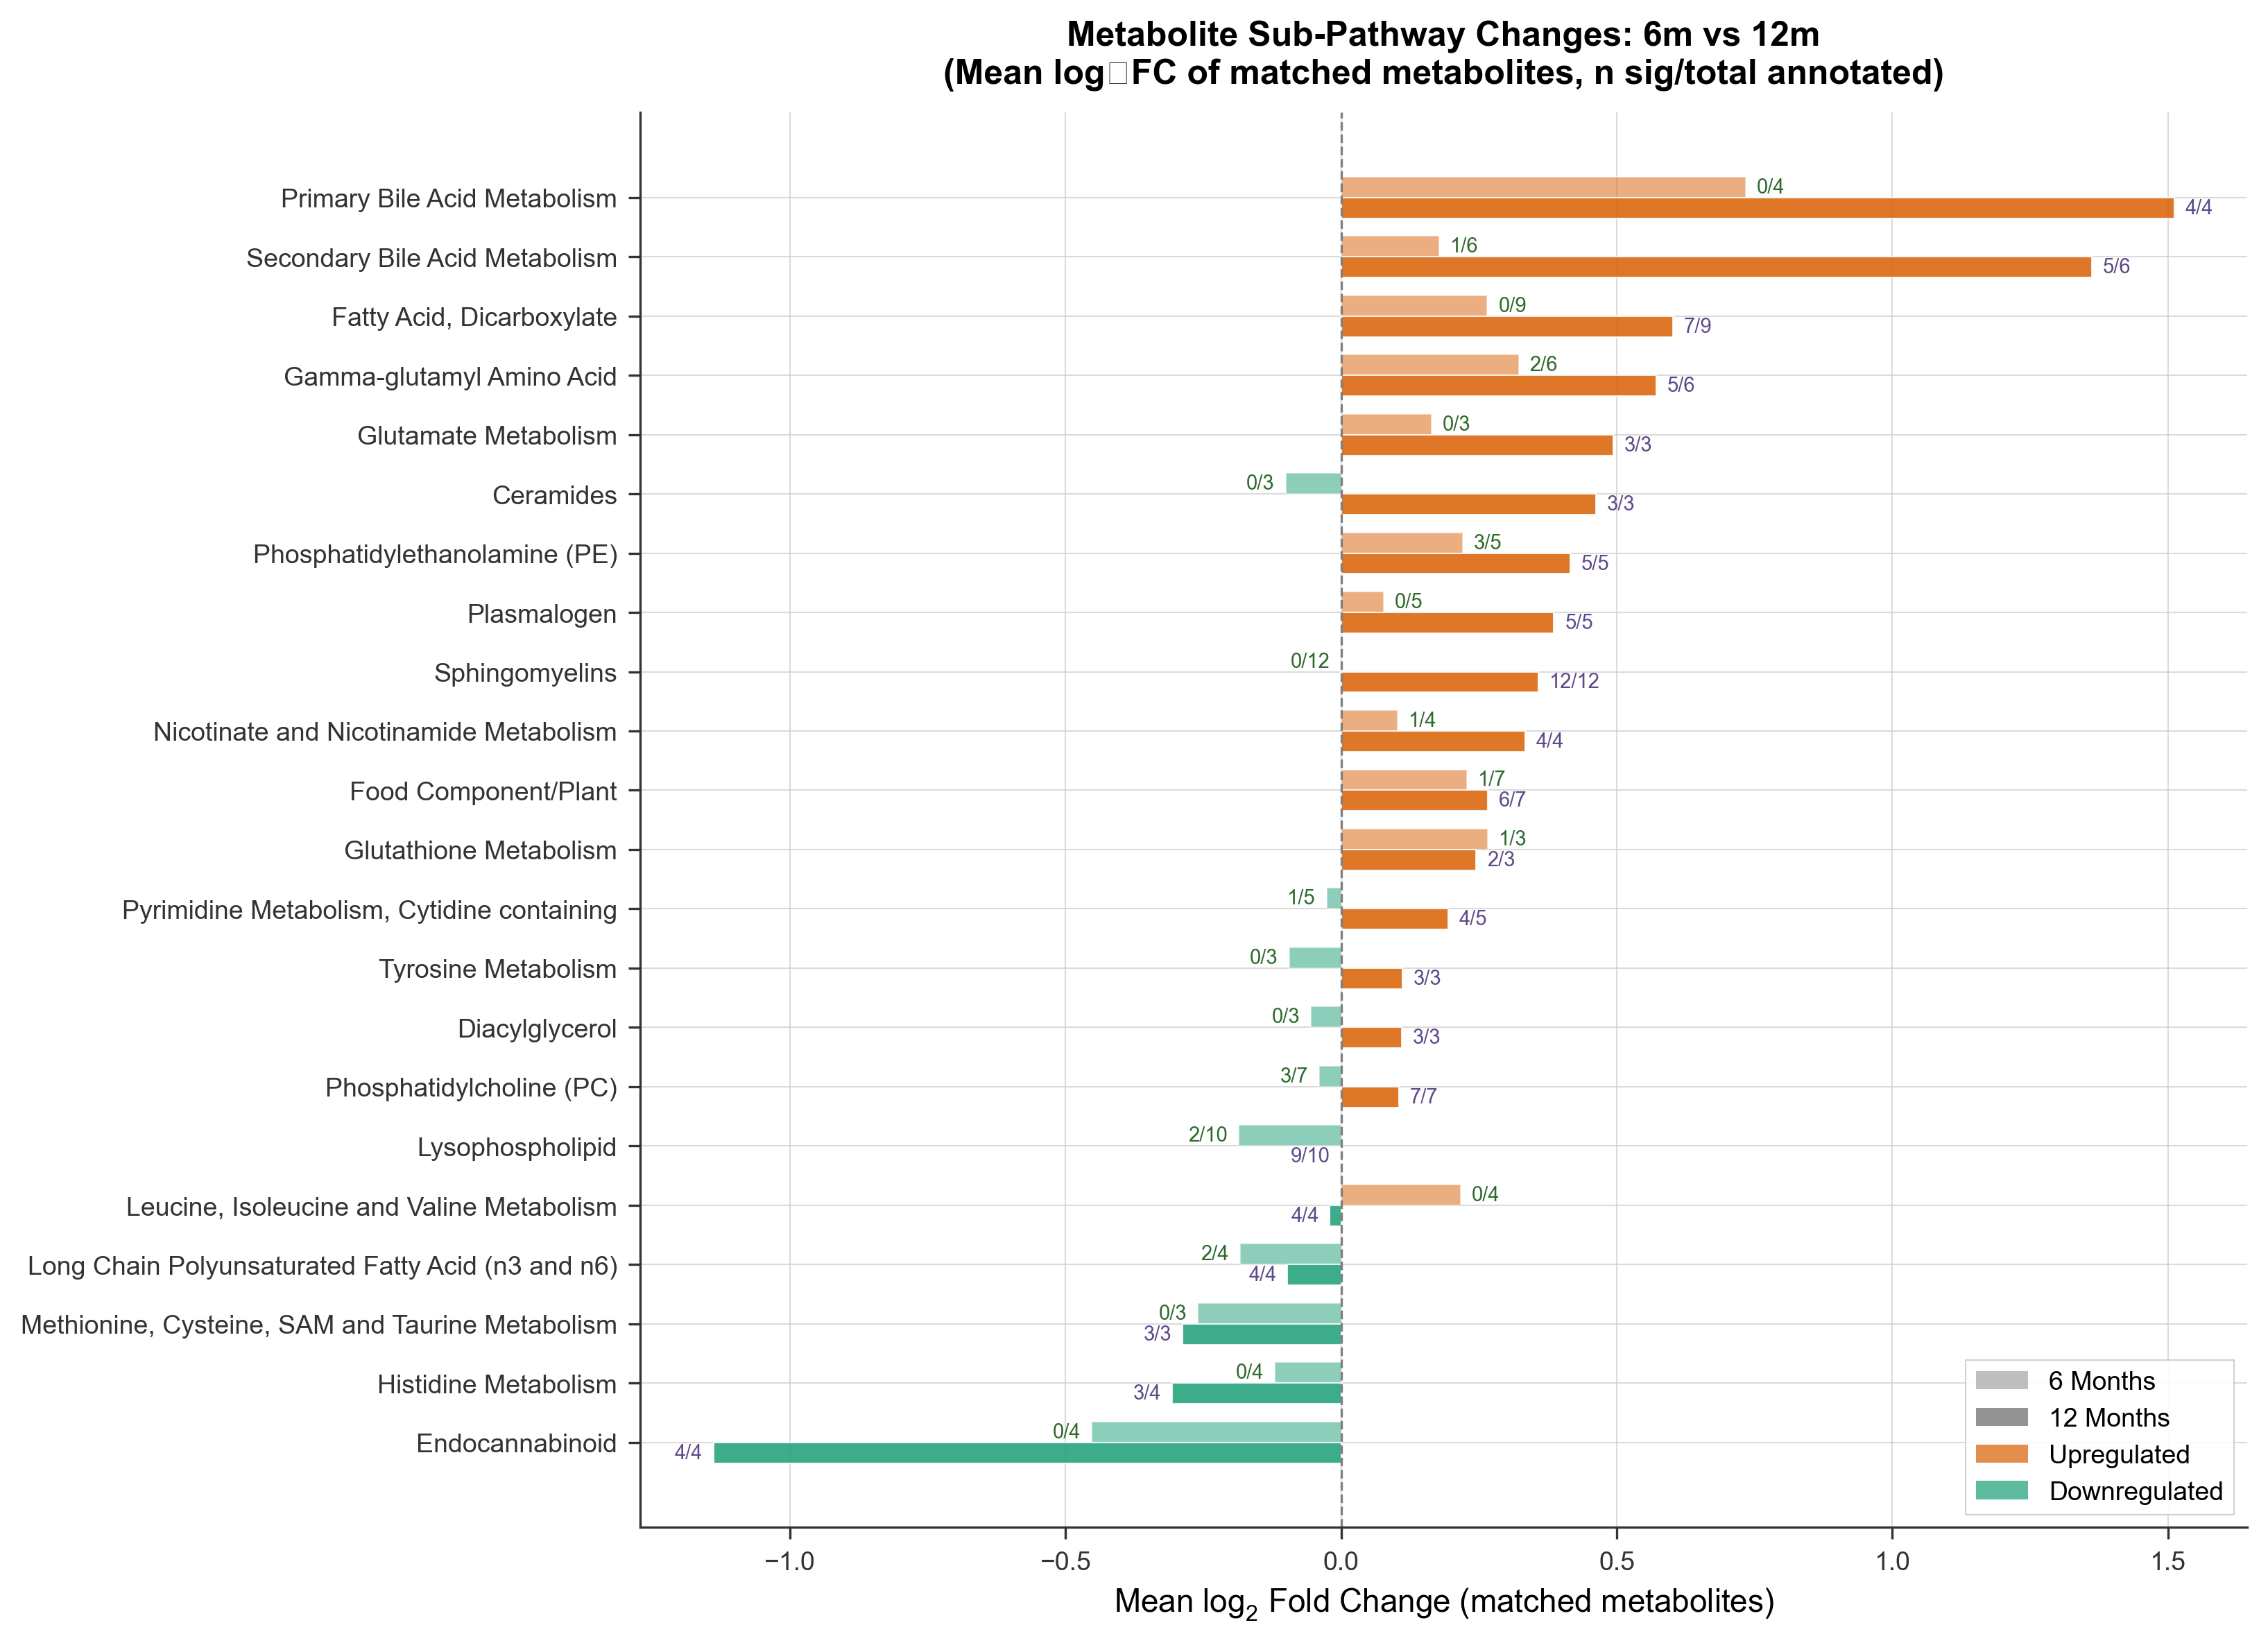

In [ ]:
# Create a clean paired comparison figure for metabolite pathways
plt.style.use("science_machine")

fig, ax = plt.subplots(figsize=(11, 8))

# Sort by 12m FC
pc = pathway_comparison.sort_values('mean_log2FC_12m', ascending=True).reset_index(drop=True)
y_pos = np.arange(len(pc))
bar_width = 0.35

# 6m bars
for i, (_, row) in enumerate(pc.iterrows()):
    color = '#d95f02' if row['mean_log2FC_6m'] > 0 else '#1b9e77'
    ax.barh(i + bar_width/2, row['mean_log2FC_6m'], bar_width, color=color, alpha=0.5, edgecolor='white')

# 12m bars
for i, (_, row) in enumerate(pc.iterrows()):
    color = '#d95f02' if row['mean_log2FC_12m'] > 0 else '#1b9e77'
    ax.barh(i - bar_width/2, row['mean_log2FC_12m'], bar_width, color=color, alpha=0.85, edgecolor='white')

# Add n sig annotations
for i, (_, row) in enumerate(pc.iterrows()):
    # 6m
    fc6 = row['mean_log2FC_6m']
    offset = 0.02 if fc6 >= 0 else -0.02
    ha = 'left' if fc6 >= 0 else 'right'
    ax.text(fc6 + offset, i + bar_width/2, f"{int(row['n_sig_6m'])}/{int(row['n'])}", 
            va='center', ha=ha, fontsize=7, color='#2d6a2d')
    
    # 12m
    fc12 = row['mean_log2FC_12m']
    offset = 0.02 if fc12 >= 0 else -0.02
    ha = 'left' if fc12 >= 0 else 'right'
    ax.text(fc12 + offset, i - bar_width/2, f"{int(row['n_sig_12m'])}/{int(row['n'])}", 
            va='center', ha=ha, fontsize=7, color='#5e4a8a')

ax.set_yticks(y_pos)
ax.set_yticklabels(pc['Sub Pathway'].values, fontsize=9)
ax.axvline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel(r'Mean $log_2$ Fold Change (matched metabolites)', fontsize=11)

legend_elements = [
    Patch(facecolor='grey', alpha=0.5, label='6 Months'),
    Patch(facecolor='grey', alpha=0.85, label='12 Months'),
    Patch(facecolor='#d95f02', alpha=0.7, label='Upregulated'),
    Patch(facecolor='#1b9e77', alpha=0.7, label='Downregulated'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9, frameon=True)

ax.set_title('Metabolite Sub-Pathway Changes: 6m vs 12m\n(Mean log₂FC of matched metabolites, n sig/total annotated)', 
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/figure9_metabolite_pathway_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure9_metabolite_pathway_comparison.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
import pandas as pd
# Read the updated 12m metabolomics file
met12_new = pd.read_csv("Liver 12m mice metabolomics mut vs wt differential analysis.csv", sep=";", nrows=5)
print("Columns:", met12_new.columns.tolist())
print(met12_new.head())


Columns: ['biochemical', 'mainpathway', 'subpathway', '12 Months', 'p-value']
                                         biochemical   mainpathway  \
0                   1,2-dilinoleoyl-GPE (18:2/18:2)*         Lipid   
1  1-(1-enyl-stearoyl)-2-linoleoyl-GPE (P-18:0/18...         Lipid   
2                            N-delta-acetylornithine    Amino Acid   
3                    1,2-dilinoleoyl-GPC (18:2/18:2)         Lipid   
4                             N6-carboxymethyllysine  Carbohydrate   

                                    subpathway  12 Months  p-value  
0                Phosphatidylethanolamine (PE)       1.98      0.0  
1                                  Plasmalogen       1.62      0.0  
2  Urea cycle; Arginine and Proline Metabolism       1.82      0.0  
3                     Phosphatidylcholine (PC)       1.45      0.0  
4               Advanced Glycation End-product       1.88      0.0  


In [ ]:
# Read full file
met12_new = pd.read_csv("Liver 12m mice metabolomics mut vs wt differential analysis.csv", sep=";")
print("Shape:", met12_new.shape)
print("Columns:", met12_new.columns.tolist())
print("\nFirst 10 rows:")
print(met12_new.head(10))
print("\nLast 5 rows:")
print(met12_new.tail(5))
print("\nSuper Pathway counts:")
print(met12_new['mainpathway'].value_counts())
print(f"\nFC range: {met12_new['12 Months'].min()} - {met12_new['12 Months'].max()}")
print(f"p-value range: {met12_new['p-value'].min()} - {met12_new['p-value'].max()}")
print(f"Significant (p<0.05): {(met12_new['p-value'] < 0.05).sum()}/{len(met12_new)}")


Shape: (738, 5)
Columns: ['biochemical', 'mainpathway', 'subpathway', '12 Months', 'p-value']

First 10 rows:
                                         biochemical   mainpathway  \
0                   1,2-dilinoleoyl-GPE (18:2/18:2)*         Lipid   
1  1-(1-enyl-stearoyl)-2-linoleoyl-GPE (P-18:0/18...         Lipid   
2                            N-delta-acetylornithine    Amino Acid   
3                    1,2-dilinoleoyl-GPC (18:2/18:2)         Lipid   
4                             N6-carboxymethyllysine  Carbohydrate   
5            1-palmitoyl-2-linoleoyl-GPE (16:0/18:2)         Lipid   
6            N-behenoyl-sphingadienine (d18:2/22:0)*         Lipid   
7      lactosyl-N-behenoyl-sphingosine (d18:1/22:0)*         Lipid   
8            1-palmitoyl-2-linoleoyl-GPC (16:0/18:2)         Lipid   
9                           alpha-hydroxyisovalerate    Amino Acid   

                                    subpathway  12 Months  p-value  
0                Phosphatidylethanolamine (PE)    

In [ ]:
import pandas as pd
import numpy as np

# Reload and clean the updated 15m metabolomics data
met15 = pd.read_csv("Liver 12m mice metabolomics mut vs wt differential analysis.csv", sep=";")
met15.columns = ['Biochem', 'Super Pathway', 'Sub Pathway', 'FC', 'p-value']
met15 = met15.dropna(subset=['Biochem']).copy()
met15['FC'] = pd.to_numeric(met15['FC'], errors='coerce')
met15['p-value'] = pd.to_numeric(met15['p-value'], errors='coerce')
met15 = met15.dropna(subset=['FC']).copy()
met15['log2FC'] = np.log2(met15['FC'])
met15['significant'] = met15['p-value'] < 0.05

print(f"15m Metabolomics: {met15.shape[0]} metabolites")
print(f"  Significant (p<0.05): {met15['significant'].sum()}")
print(f"  Up: {((met15['log2FC'] > 0) & met15['significant']).sum()}")
print(f"  Down: {((met15['log2FC'] < 0) & met15['significant']).sum()}")
print(f"\nSuper Pathway counts:")
print(met15['Super Pathway'].value_counts())


15m Metabolomics: 738 metabolites
  Significant (p<0.05): 157
  Up: 106
  Down: 51

Super Pathway counts:
Super Pathway
Lipid                                365
Amino Acid                           165
Nucleotide                            54
Carbohydrate                          48
Cofactors and Vitamins                47
Xenobiotics                           27
Peptide                               19
Energy                                12
Partially Characterized Molecules      1
Name: count, dtype: int64


In [ ]:
# Reload 9m (formerly "6m") metabolomics - already loaded as met6
# Reload 15m (formerly "12m") transcriptomics
tx15 = pd.read_excel("custom edgeR output 12M mice Mut v Wtcr transcriptome.xlsx", sheet_name="Sheet1")
tx15_clean = tx15.dropna(subset=['gene_name']).copy()
tx15_clean['significant'] = tx15_clean['fdr'] < 0.05

# Reload 9m (formerly "6m") transcriptomics
tx9 = pd.read_excel("custom edgeR output 6M mice Mut v Wtcr transcriptome.xlsx", sheet_name="Sheet1")
tx9_clean = tx9.dropna(subset=['gene_name']).copy()
tx9_clean['significant'] = tx9_clean['fdr'] < 0.05

# Rename met6 -> met9 for clarity
met9 = met6.copy()

print("=== Corrected Age Labels ===")
print(f"9m:  {tx9_clean['significant'].sum()} sig genes, {met9['significant'].sum()}/{met9.shape[0]} sig metabolites")
print(f"15m: {tx15_clean['significant'].sum()} sig genes, {met15['significant'].sum()}/{met15.shape[0]} sig metabolites")


In [ ]:
# Reload 9m metabolomics from scratch
met9_raw = pd.read_csv("Liver 6m mice metabolomics mut vs wt differential analysis.csv", sep=";", skiprows=[1])
met9_raw.columns = ['Super Pathway', 'Sub Pathway', 'Biochem', 'Comp ID', 'KEGG', 'HMDB', 'PubChem', 'FC', 'p-value', 'q-value']
met9_raw['Super Pathway'] = met9_raw['Super Pathway'].ffill()
met9_raw['Sub Pathway'] = met9_raw['Sub Pathway'].ffill()
met9 = met9_raw.dropna(subset=['Biochem']).copy()
met9['FC'] = pd.to_numeric(met9['FC'], errors='coerce')
met9['p-value'] = pd.to_numeric(met9['p-value'], errors='coerce')
met9 = met9.dropna(subset=['FC']).copy()
met9['log2FC'] = np.log2(met9['FC'])
met9['significant'] = met9['p-value'] < 0.05

print(f"9m:  {tx9_clean['significant'].sum()} sig genes, {met9['significant'].sum()}/{met9.shape[0]} sig metabolites")
print(f"15m: {tx15_clean['significant'].sum()} sig genes, {met15['significant'].sum()}/{met15.shape[0]} sig metabolites")


9m:  255 sig genes, 92/738 sig metabolites
15m: 1892 sig genes, 157/738 sig metabolites


In [ ]:
# Re-run pathway analyses with corrected data
# Define pathway-gene mapping (same as before)
pathway_gene_map = {
    'Bile Acid Metabolism': {
        'genes': ['Cyp7a1', 'Cyp8b1', 'Cyp27a1', 'Cyp7b1', 'Baat', 'Slc27a5', 'Abcb11', 'Abcc2', 
                  'Abcc3', 'Abcc4', 'Abcb4', 'Nr1h4', 'Nr0b2', 'Slco1a1', 'Slco1b2', 'Slc10a1',
                  'Hsd3b7', 'Akr1d1', 'Amacr', 'Scp2', 'Slc51a', 'Slc51b',
                  'Cyp2c70', 'Cyp2a12', 'Sult2a1', 'Sult2a2', 'Sult2a3', 'Sult2a4', 'Sult2a5', 'Sult2a6', 'Sult2a7', 'Sult2a8'],
        'metabolites': ['Primary Bile Acid Metabolism', 'Secondary Bile Acid Metabolism']
    },
    'Glutathione & Oxidative Stress': {
        'genes': ['Gclc', 'Gclm', 'Gss', 'Gpx1', 'Gpx2', 'Gpx3', 'Gpx4', 'Gsr', 'Gsta1', 'Gsta2', 
                  'Gsta3', 'Gsta4', 'Gstm1', 'Gstm2', 'Gstm3', 'Gstm4', 'Gstm5', 'Gstm6', 'Gstm7',
                  'Gstp1', 'Gstp2', 'Gstt1', 'Gstt2', 'Gstt3', 'Nfe2l2', 'Keap1', 'Nqo1', 'Hmox1', 'Hmox2',
                  'Sod1', 'Sod2', 'Cat', 'Txn1', 'Txn2', 'Txnrd1', 'Txnrd2', 'Prdx1', 'Prdx2', 'Prdx3',
                  'Prdx4', 'Prdx5', 'Prdx6', 'Mgst1', 'Mgst2', 'Mgst3'],
        'metabolites': ['Glutathione Metabolism', 'Gamma-glutamyl Amino Acid']
    },
    'Lipid & Sphingolipid Metabolism': {
        'genes': ['Smpd1', 'Smpd2', 'Smpd3', 'Sgms1', 'Sgms2', 'Cers1', 'Cers2', 'Cers3', 'Cers4', 
                  'Cers5', 'Cers6', 'Sptlc1', 'Sptlc2', 'Kdsr', 'Degs1', 'Degs2', 'Ugcg', 'Asah1', 'Asah2',
                  'Acer1', 'Acer2', 'Acer3', 'Sphk1', 'Sphk2', 'Sgpl1', 'Ppara', 'Pparg', 'Ppard',
                  'Srebf1', 'Srebf2', 'Fasn', 'Acaca', 'Scd1', 'Scd2', 'Elovl1', 'Elovl2', 'Elovl3',
                  'Elovl4', 'Elovl5', 'Elovl6', 'Fads1', 'Fads2'],
        'metabolites': ['Sphingomyelins', 'Ceramides', 'Lactosylceramides (LCER)', 'Phosphatidylcholine (PC)', 
                       'Phosphatidylethanolamine (PE)', 'Plasmalogen', 'Lysophospholipid', 'Lysoplasmalogen',
                       'Diacylglycerol', 'Phospholipid Metabolism']
    },
    'Amino Acid & Protein Quality': {
        'genes': ['Atf4', 'Atf3', 'Atf5', 'Atf6', 'Ddit3', 'Eif2ak1', 'Eif2ak2', 'Eif2ak3', 'Eif2ak4',
                  'Eif2s1', 'Asns', 'Psat1', 'Phgdh', 'Shmt2', 'Mthfd2', 'Cth', 'Cbs', 'Mat1a', 'Mat2a',
                  'Bhmt', 'Gnmt', 'Ahcy', 'Mtr', 'Mtrr', 'Bcat1', 'Bcat2', 'Bckdha', 'Bckdhb',
                  'Hspa5', 'Hsp90b1', 'Calr', 'Canx', 'Ern1', 'Xbp1'],
        'metabolites': ['Leucine, Isoleucine and Valine Metabolism', 'Glutamate Metabolism', 
                       'Methionine, Cysteine, SAM and Taurine Metabolism', 'Tryptophan Metabolism',
                       'Histidine Metabolism', 'Alanine and Aspartate Metabolism',
                       'Urea cycle; Arginine and Proline Metabolism']
    },
    'Purine & Pyrimidine Metabolism': {
        'genes': ['Hprt', 'Xdh', 'Ada', 'Pnp', 'Atic', 'Gart', 'Pfas', 'Paics', 'Adsl', 'Adss',
                  'Impdh1', 'Impdh2', 'Gmps', 'Umps', 'Cad', 'Dhodh', 'Ctps1', 'Ctps2',
                  'Rrm1', 'Rrm2', 'Tyms', 'Tk1', 'Dck', 'Uck1', 'Uck2'],
        'metabolites': ['Purine Metabolism, (Hypo)Xanthine/Inosine containing', 'Pyrimidine Metabolism, Cytidine containing',
                       'Pyrimidine Metabolism, Uracil containing', 'Purine Metabolism, Adenine containing',
                       'Purine Metabolism, Guanine containing']
    },
    'Nicotinamide & Cofactor Metabolism': {
        'genes': ['Nampt', 'Nmnat1', 'Nmnat2', 'Nmnat3', 'Nmrk1', 'Nmrk2', 'Nadsyn1', 'Qprt', 'Naprt',
                  'Nnmt', 'Aox1', 'Aox3', 'Aldh1a1', 'Aldh1a2', 'Aldh1a3', 'Aldh2'],
        'metabolites': ['Nicotinate and Nicotinamide Metabolism', 'Vitamin B6 Metabolism',
                       'Pantothenate and CoA Metabolism', 'Riboflavin Metabolism']
    }
}

def build_pathway_summary(tx_df, met_df, met_fc_col='log2FC', met_pval_col='p-value'):
    data = []
    for pathway, info in pathway_gene_map.items():
        genes = info['genes']
        met_subpaths = info['metabolites']
        tx_genes = tx_df[tx_df['gene_name'].str.lower().isin([g.lower() for g in genes])]
        sig_genes = tx_genes[tx_genes['fdr'] < 0.05]
        met_sub = met_df[met_df['Sub Pathway'].isin(met_subpaths)]
        sig_met = met_sub[met_sub[met_pval_col] < 0.05]
        data.append({
            'Pathway': pathway,
            'n_genes_found': len(tx_genes), 'n_genes_sig': len(sig_genes),
            'mean_gene_log2FC': sig_genes['log2 Ratio'].mean() if len(sig_genes) > 0 else 0,
            'n_met_found': len(met_sub), 'n_met_sig': len(sig_met),
            'mean_met_log2FC': sig_met[met_fc_col].mean() if len(sig_met) > 0 else 0,
        })
    return pd.DataFrame(data)

pdf_9m = build_pathway_summary(tx9_clean, met9)
pdf_15m = build_pathway_summary(tx15_clean, met15)

print("9m pathway summary:")
print(pdf_9m.to_string(index=False))
print("\n15m pathway summary:")
print(pdf_15m.to_string(index=False))


9m pathway summary:
                           Pathway  n_genes_found  n_genes_sig  mean_gene_log2FC  n_met_found  n_met_sig  mean_met_log2FC
              Bile Acid Metabolism             31            1           -0.3650           22          1         1.232661
    Glutathione & Oxidative Stress             45            2            0.2107           20          4         0.630358
   Lipid & Sphingolipid Metabolism             42            0            0.0000          149         22        -0.078142
      Amino Acid & Protein Quality             34            2            0.5616          104         17        -0.167499
    Purine & Pyrimidine Metabolism             24            1            0.3952           46          4        -0.571351
Nicotinamide & Cofactor Metabolism             16            0            0.0000           22          1         0.704872

15m pathway summary:
                           Pathway  n_genes_found  n_genes_sig  mean_gene_log2FC  n_met_found  n_met_sig

In [ ]:
from scipy.stats import ranksums
from statsmodels.stats.multitest import multipletests

def metabolite_pathway_qea(met_df, fc_col='log2FC', pathway_col='Sub Pathway', min_size=3):
    results = []
    for pathway in met_df[pathway_col].unique():
        pw_fc = met_df[met_df[pathway_col] == pathway][fc_col].dropna().values
        bg_fc = met_df[met_df[pathway_col] != pathway][fc_col].dropna().values
        if len(pw_fc) < min_size:
            continue
        stat, pval = ranksums(pw_fc, bg_fc)
        results.append({
            'Pathway': pathway, 'n': len(pw_fc), 'mean_log2FC': pw_fc.mean(),
            'wilcoxon_p': pval, 'direction': 'Up' if pw_fc.mean() > 0 else 'Down'
        })
    res_df = pd.DataFrame(results).sort_values('wilcoxon_p')
    _, res_df['wilcoxon_fdr'], _, _ = multipletests(res_df['wilcoxon_p'], method='fdr_bh')
    return res_df

met9_qea = metabolite_pathway_qea(met9)
met15_qea = metabolite_pathway_qea(met15)

print("15m Metabolite QEA (top 15):")
print(met15_qea.head(15).to_string(index=False))


15m Metabolite QEA (top 15):
                                        Pathway  n  mean_log2FC  wilcoxon_p direction  wilcoxon_fdr
                 Secondary Bile Acid Metabolism 14     0.818245    0.000030        Up      0.002310
                      Fatty Acid, Dicarboxylate 19     0.423516    0.000119        Up      0.004534
                   Primary Bile Acid Metabolism  8     0.960825    0.000725        Up      0.018337
                                     Eicosanoid  6    -0.496120    0.000965      Down      0.018337
                      Gamma-glutamyl Amino Acid  9     0.452180    0.001946        Up      0.029573
                                Endocannabinoid 12    -0.414316    0.008518      Down      0.107893
          Purine Metabolism, Guanine containing  6    -0.209643    0.014452      Down      0.139437
                                    Plasmalogen  7     0.350967    0.016536        Up      0.139437
                                       Chemical  4     0.750332    0.01

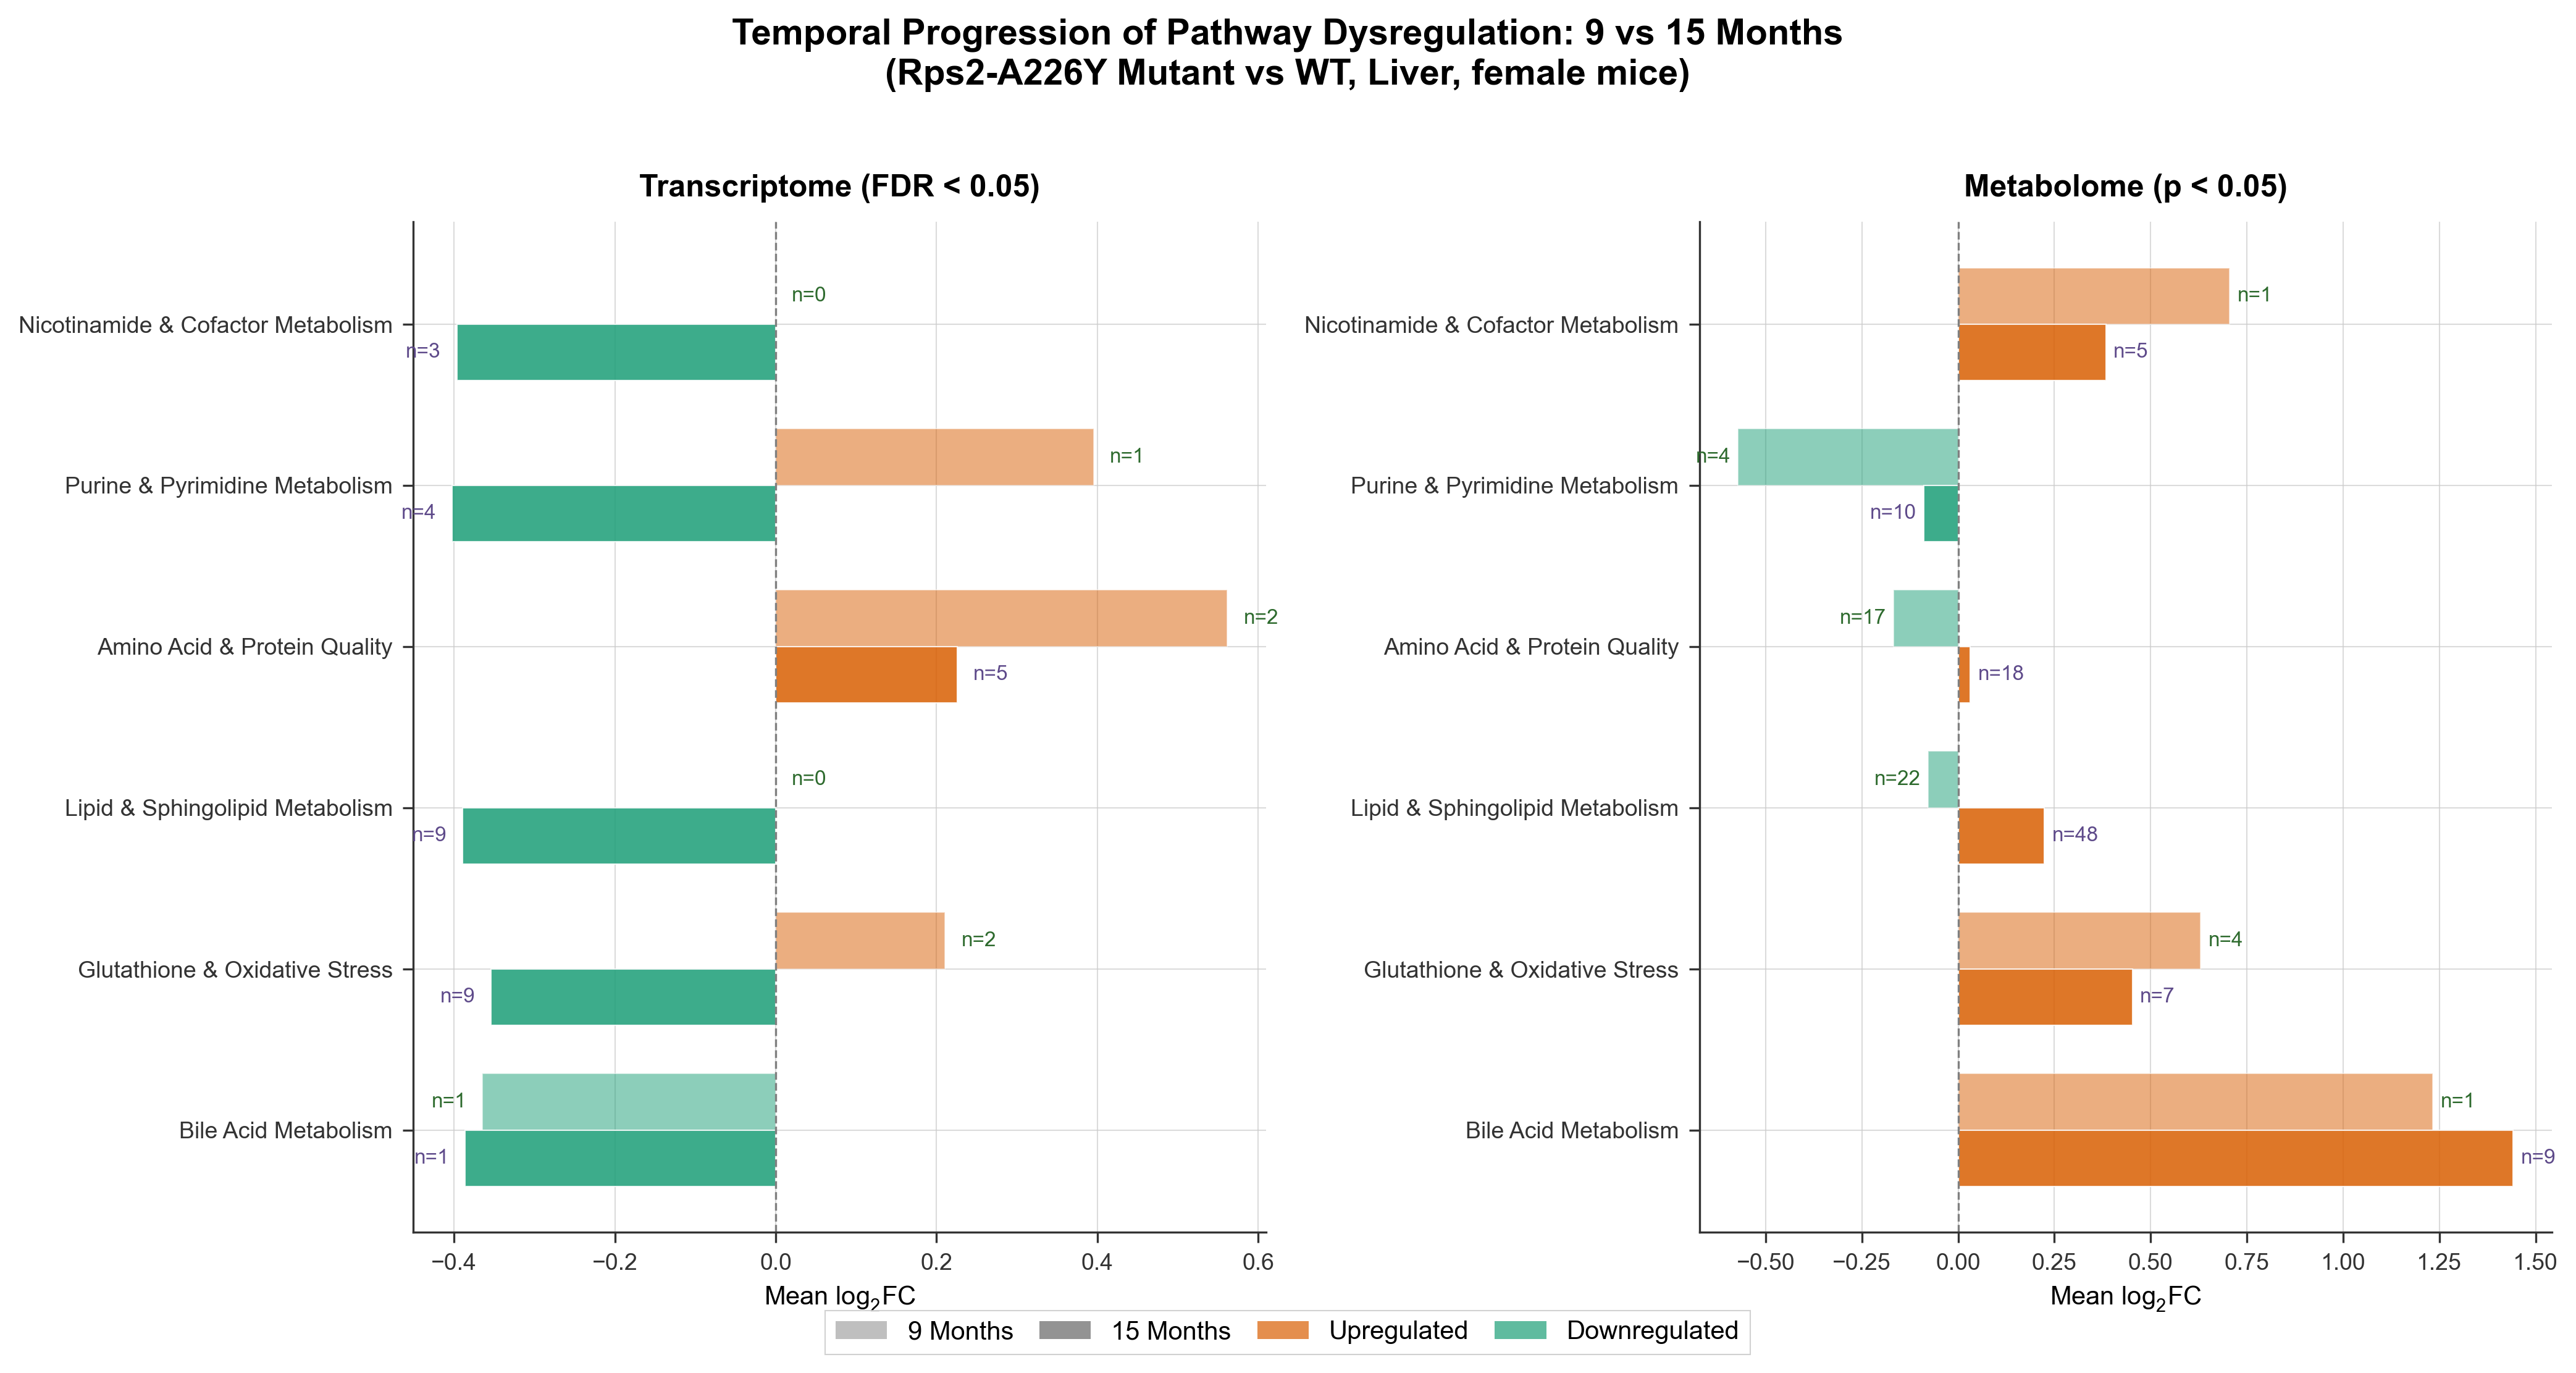

In [ ]:
# Now regenerate the key figures with corrected age labels
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.style.use("science_machine")

# Figure 3 (corrected): Pathway-level comparison 9m vs 15m
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

pathway_order = [
    'Bile Acid Metabolism',
    'Glutathione & Oxidative Stress', 
    'Lipid & Sphingolipid Metabolism',
    'Amino Acid & Protein Quality',
    'Purine & Pyrimidine Metabolism',
    'Nicotinamide & Cofactor Metabolism'
]
y_pos = np.arange(len(pathway_order))
bar_width = 0.35

for ax_idx, (ax, title, fc_col, n_col) in enumerate([
    (axes[0], 'Transcriptome (FDR < 0.05)', 'mean_gene_log2FC', 'n_genes_sig'),
    (axes[1], 'Metabolome (p < 0.05)', 'mean_met_log2FC', 'n_met_sig')
]):
    n_total_col = 'n_genes_found' if 'gene' in fc_col else 'n_met_found'
    pdf_9_ord = pdf_9m.set_index('Pathway').loc[pathway_order]
    pdf_15_ord = pdf_15m.set_index('Pathway').loc[pathway_order]
    
    for i in range(len(pathway_order)):
        fc9 = pdf_9_ord.iloc[i][fc_col]
        fc15 = pdf_15_ord.iloc[i][fc_col]
        c9 = '#d95f02' if fc9 > 0 else ('#1b9e77' if fc9 < 0 else '#999999')
        c15 = '#d95f02' if fc15 > 0 else ('#1b9e77' if fc15 < 0 else '#999999')
        ax.barh(i + bar_width/2, fc9, bar_width, color=c9, alpha=0.5, edgecolor='white')
        ax.barh(i - bar_width/2, fc15, bar_width, color=c15, alpha=0.85, edgecolor='white')
        
        n9 = int(pdf_9_ord.iloc[i][n_col])
        n15 = int(pdf_15_ord.iloc[i][n_col])
        off9 = 0.02 if fc9 >= 0 else -0.02; ha9 = 'left' if fc9 >= 0 else 'right'
        off15 = 0.02 if fc15 >= 0 else -0.02; ha15 = 'left' if fc15 >= 0 else 'right'
        ax.text(fc9 + off9, i + bar_width/2, f'n={n9}', va='center', ha=ha9, fontsize=8, color='#2d6a2d')
        ax.text(fc15 + off15, i - bar_width/2, f'n={n15}', va='center', ha=ha15, fontsize=8, color='#5e4a8a')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(pathway_order, fontsize=9)
    ax.axvline(0, color='grey', linewidth=0.8, linestyle='--')
    ax.set_xlabel(r'Mean $log_2$FC', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold')

legend_elements = [
    Patch(facecolor='grey', alpha=0.5, label='9 Months'),
    Patch(facecolor='grey', alpha=0.85, label='15 Months'),
    Patch(facecolor='#d95f02', alpha=0.7, label='Upregulated'),
    Patch(facecolor='#1b9e77', alpha=0.7, label='Downregulated'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=10, frameon=True, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Temporal Progression of Pathway Dysregulation: 9 vs 15 Months\n(Rps2-A226Y Mutant vs WT, Liver, female mice)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/figure3_corrected_pathway_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure3_corrected_pathway_comparison.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# Figure 4 (corrected): Temporal scatter - 9m vs 15m fold changes
from scipy.stats import pearsonr, spearmanr
from adjustText import adjust_text

# Merge metabolites
met9_for_merge = met9[['Biochem', 'FC', 'log2FC', 'p-value', 'Sub Pathway']].copy()
met9_for_merge.columns = ['Biochem', 'FC_9m', 'log2FC_9m', 'pval_9m', 'Sub Pathway']
met15_for_merge = met15[['Biochem', 'FC', 'log2FC', 'p-value', 'Sub Pathway']].copy()
met15_for_merge.columns = ['Biochem', 'FC_15m', 'log2FC_15m', 'pval_15m', 'Sub Pathway']
met_merged = met9_for_merge.merge(met15_for_merge[['Biochem', 'FC_15m', 'log2FC_15m', 'pval_15m']], on='Biochem', how='inner')

# Merge genes
tx_merged = tx9_clean[['gene_name', 'log2 Ratio', 'pValue', 'fdr']].merge(
    tx15_clean[['gene_name', 'log2 Ratio', 'pValue', 'fdr']], on='gene_name', suffixes=('_9m', '_15m'))

r_met, _ = pearsonr(met_merged['log2FC_9m'], met_merged['log2FC_15m'])
rho_met, _ = spearmanr(met_merged['log2FC_9m'], met_merged['log2FC_15m'])
r_tx, _ = pearsonr(tx_merged['log2 Ratio_9m'], tx_merged['log2 Ratio_15m'])
rho_tx, _ = spearmanr(tx_merged['log2 Ratio_9m'], tx_merged['log2 Ratio_15m'])

print(f"Metabolite correlation: r={r_met:.3f}, ρ={rho_met:.3f}")
print(f"Gene correlation: r={r_tx:.3f}, ρ={rho_tx:.3f}")
print(f"Common metabolites: {len(met_merged)}, Common genes: {len(tx_merged)}")

# Significance categories
met_merged['sig_cat'] = 'Neither'
met_merged.loc[(met_merged['pval_9m'] < 0.05) & (met_merged['pval_15m'] < 0.05), 'sig_cat'] = 'Both'
met_merged.loc[(met_merged['pval_9m'] < 0.05) & (met_merged['pval_15m'] >= 0.05), 'sig_cat'] = '9m only'
met_merged.loc[(met_merged['pval_9m'] >= 0.05) & (met_merged['pval_15m'] < 0.05), 'sig_cat'] = '15m only'

tx_merged['sig_cat'] = 'Neither'
tx_merged.loc[(tx_merged['fdr_9m'] < 0.05) & (tx_merged['fdr_15m'] < 0.05), 'sig_cat'] = 'Both'
tx_merged.loc[(tx_merged['fdr_9m'] < 0.05) & (tx_merged['fdr_15m'] >= 0.05), 'sig_cat'] = '9m only'
tx_merged.loc[(tx_merged['fdr_9m'] >= 0.05) & (tx_merged['fdr_15m'] < 0.05), 'sig_cat'] = '15m only'

print(f"\nMetabolites: Both={met_merged['sig_cat'].eq('Both').sum()}, 9m only={met_merged['sig_cat'].eq('9m only').sum()}, 15m only={met_merged['sig_cat'].eq('15m only').sum()}")
print(f"Genes: Both={tx_merged['sig_cat'].eq('Both').sum()}, 9m only={tx_merged['sig_cat'].eq('9m only').sum()}, 15m only={tx_merged['sig_cat'].eq('15m only').sum()}")


Metabolite correlation: r=0.274, ρ=0.242
Gene correlation: r=0.456, ρ=0.376
Common metabolites: 738, Common genes: 22660

Metabolites: Both=25, 9m only=67, 15m only=132
Genes: Both=118, 9m only=139, 15m only=1747


/app/backend/.venv/lib/python3.11/site-packages/matplotlib/pyplot.py:1250: UserWarning: Text labels overlap each other. This should be avoided.
  res = fig.savefig(*args, **kwargs)  # type: ignore[func-returns-value]


/app/backend/.venv/lib/python3.11/site-packages/matplotlib/pyplot.py:1250: UserWarning: Text labels overlap each other. This should be avoided.
  res = fig.savefig(*args, **kwargs)  # type: ignore[func-returns-value]


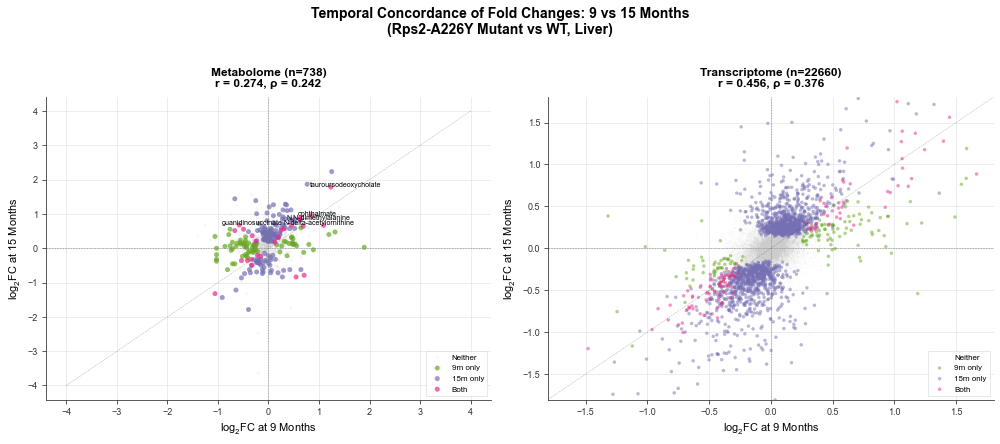

In [ ]:
# Figure 4: Temporal scatter plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Color map
cat_colors = {'Both': '#e7298a', '9m only': '#66a61e', '15m only': '#7570b3', 'Neither': '#cccccc'}
cat_order = ['Neither', '9m only', '15m only', 'Both']

# Metabolites
for cat in cat_order:
    sub = met_merged[met_merged['sig_cat'] == cat]
    alpha = 0.15 if cat == 'Neither' else 0.7
    s = 10 if cat == 'Neither' else 25
    ax1.scatter(sub['log2FC_9m'], sub['log2FC_15m'], c=cat_colors[cat], alpha=alpha, s=s, label=cat, edgecolors='none')

# Label top metabolites
top_met = met_merged[met_merged['sig_cat'] == 'Both'].nlargest(5, 'log2FC_15m')
texts = []
for _, row in top_met.iterrows():
    texts.append(ax1.text(row['log2FC_9m'], row['log2FC_15m'], row['Biochem'], fontsize=7))
adjust_text(texts, ax=ax1, arrowprops=dict(arrowstyle='-', color='grey', lw=0.5))

ax1.axhline(0, color='grey', lw=0.5, ls='--'); ax1.axvline(0, color='grey', lw=0.5, ls='--')
lims = max(abs(met_merged['log2FC_9m']).max(), abs(met_merged['log2FC_15m']).max()) * 1.1
ax1.plot([-lims, lims], [-lims, lims], 'k--', lw=0.5, alpha=0.3)
ax1.set_xlabel(r'$log_2$FC at 9 Months', fontsize=11)
ax1.set_ylabel(r'$log_2$FC at 15 Months', fontsize=11)
ax1.set_title(f'Metabolome (n={len(met_merged)})\nr = {r_met:.3f}, ρ = {rho_met:.3f}', fontsize=12, fontweight='bold')
ax1.legend(fontsize=8, loc='lower right')

# Genes
for cat in cat_order:
    sub = tx_merged[tx_merged['sig_cat'] == cat]
    alpha = 0.05 if cat == 'Neither' else 0.5
    s = 3 if cat == 'Neither' else 12
    ax2.scatter(sub['log2 Ratio_9m'], sub['log2 Ratio_15m'], c=cat_colors[cat], alpha=alpha, s=s, label=cat, edgecolors='none')

ax2.axhline(0, color='grey', lw=0.5, ls='--'); ax2.axvline(0, color='grey', lw=0.5, ls='--')
lims2 = max(abs(tx_merged['log2 Ratio_9m']).max(), abs(tx_merged['log2 Ratio_15m']).max()) * 0.5
ax2.set_xlim(-lims2, lims2); ax2.set_ylim(-lims2, lims2)
ax2.plot([-lims2, lims2], [-lims2, lims2], 'k--', lw=0.5, alpha=0.3)
ax2.set_xlabel(r'$log_2$FC at 9 Months', fontsize=11)
ax2.set_ylabel(r'$log_2$FC at 15 Months', fontsize=11)
ax2.set_title(f'Transcriptome (n={len(tx_merged)})\nr = {r_tx:.3f}, ρ = {rho_tx:.3f}', fontsize=12, fontweight='bold')
ax2.legend(fontsize=8, loc='lower right')

fig.suptitle('Temporal Concordance of Fold Changes: 9 vs 15 Months\n(Rps2-A226Y Mutant vs WT, Liver)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/figure4_corrected_temporal_scatter.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure4_corrected_temporal_scatter.pdf', bbox_inches='tight', facecolor='white')
plt.show()


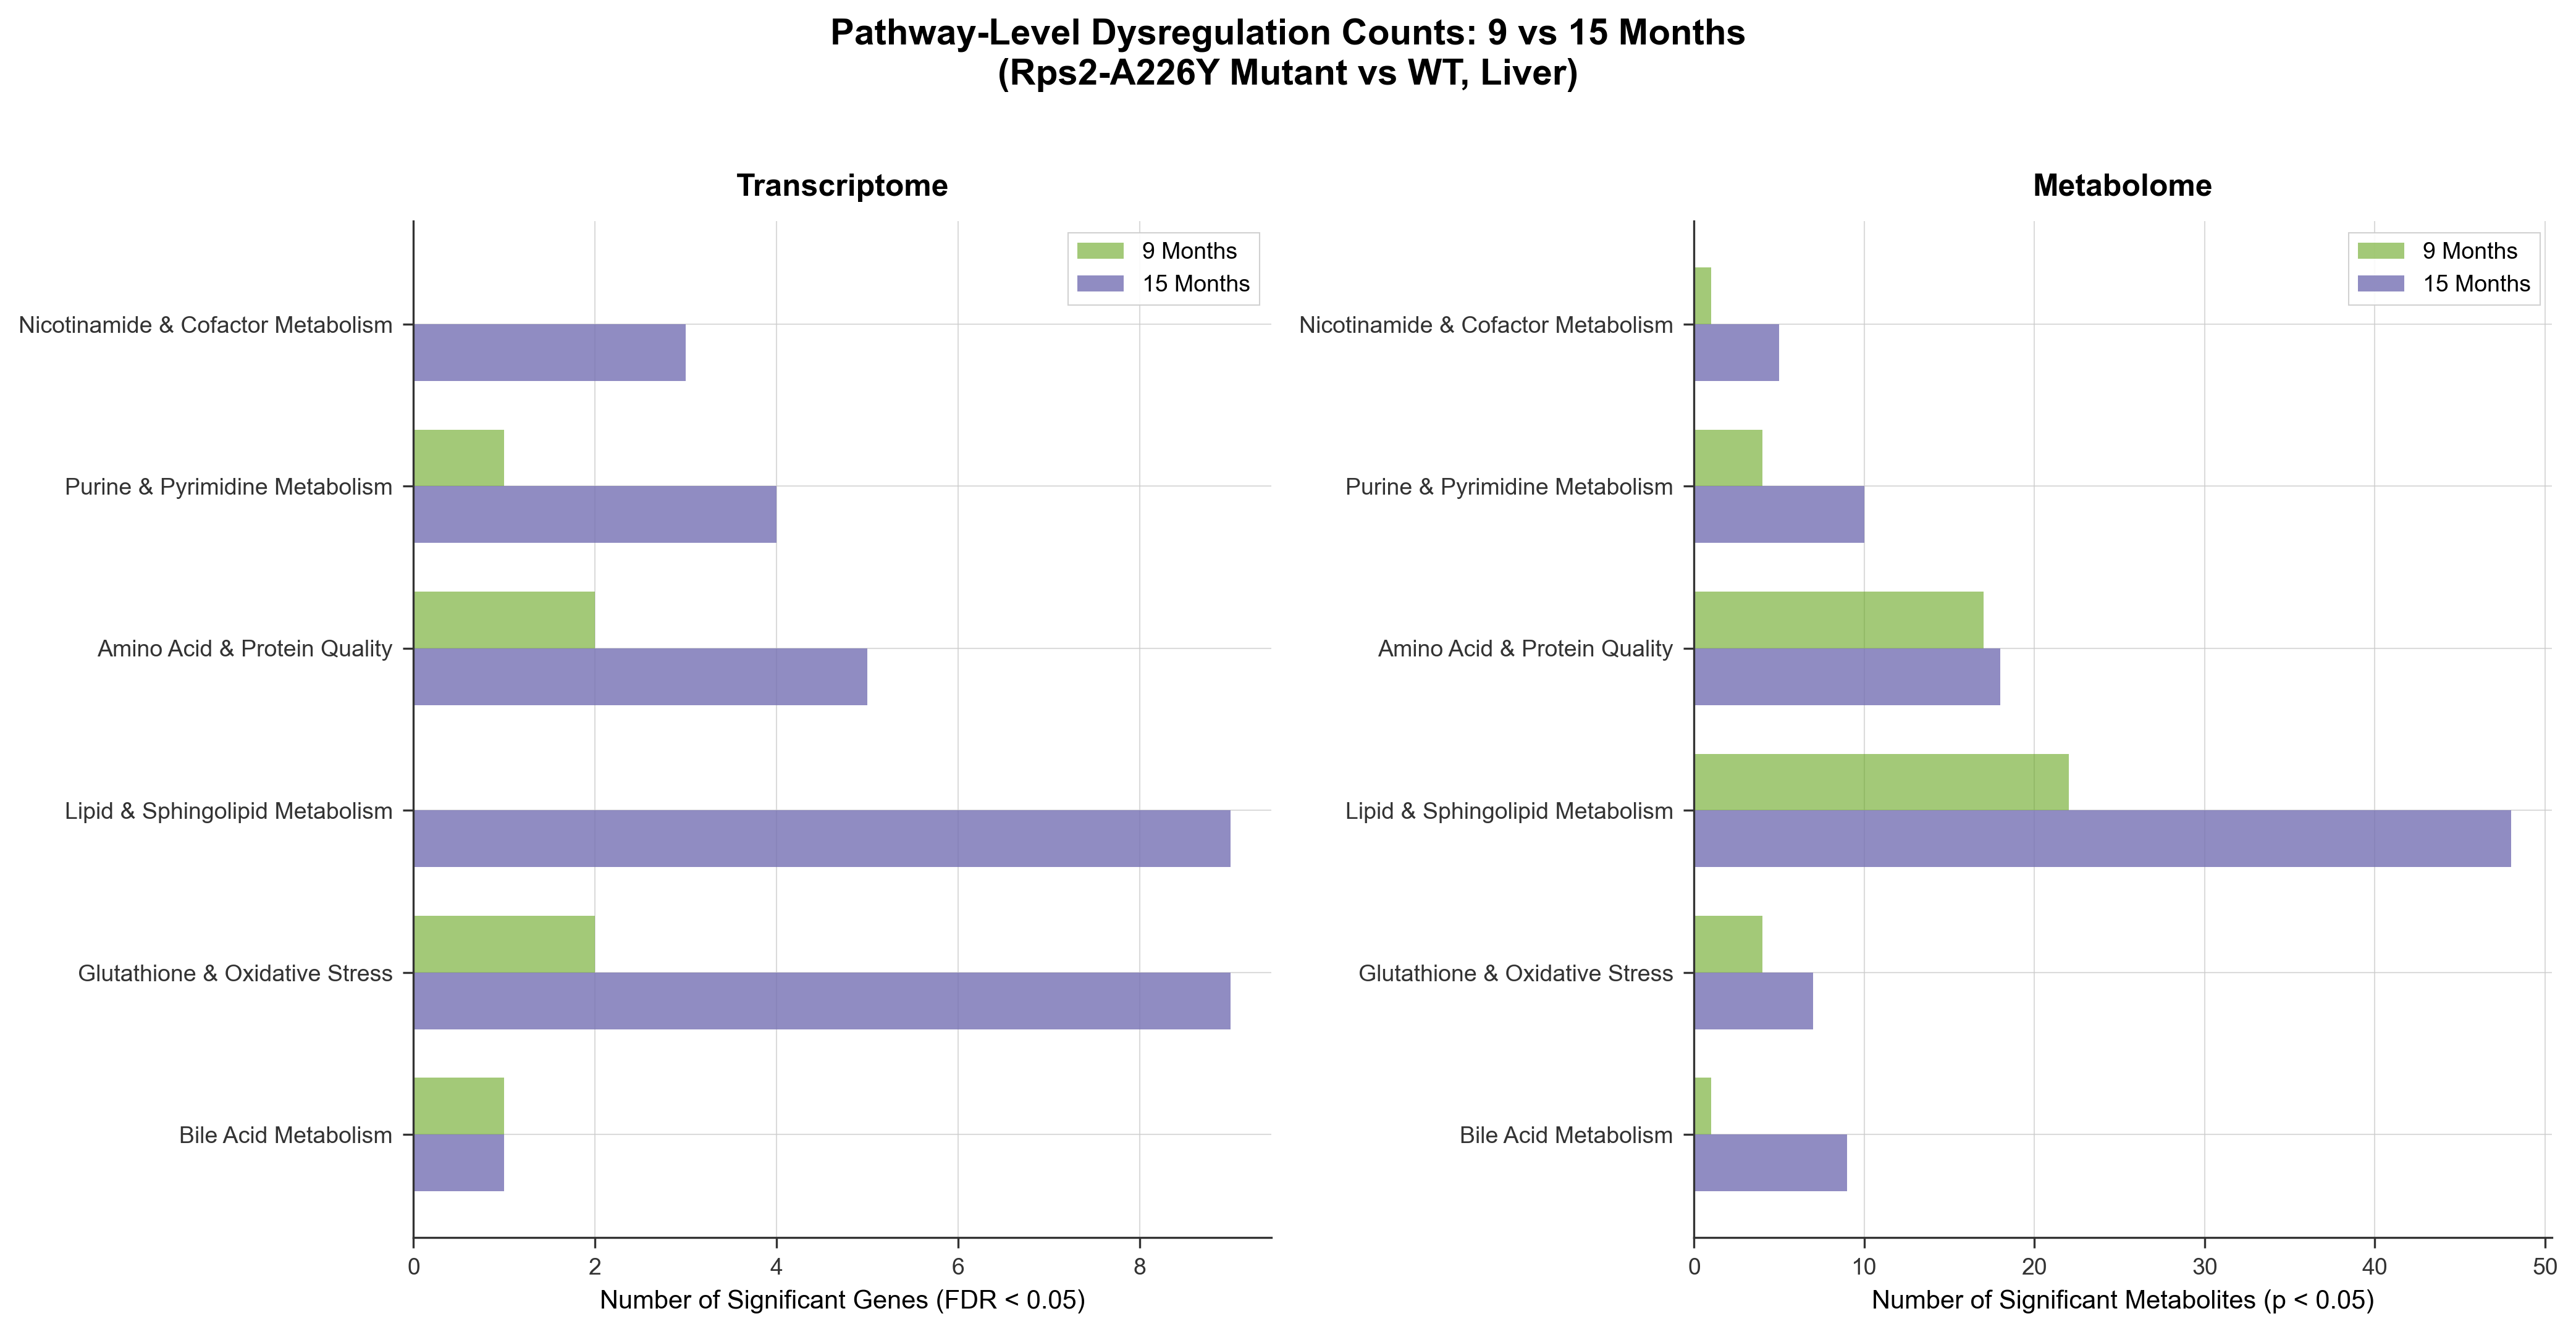

In [ ]:
# Figure 5: Temporal pathway comparison - bar chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# Transcriptome pathway comparison
x = np.arange(len(pathway_order))
width = 0.35

pdf_9_ord = pdf_9m.set_index('Pathway').loc[pathway_order]
pdf_15_ord = pdf_15m.set_index('Pathway').loc[pathway_order]

bars1 = ax1.barh(x + width/2, pdf_9_ord['n_genes_sig'], width, color='#66a61e', alpha=0.6, label='9 Months')
bars2 = ax1.barh(x - width/2, pdf_15_ord['n_genes_sig'], width, color='#7570b3', alpha=0.8, label='15 Months')
ax1.set_yticks(x)
ax1.set_yticklabels(pathway_order, fontsize=9)
ax1.set_xlabel('Number of Significant Genes (FDR < 0.05)', fontsize=10)
ax1.set_title('Transcriptome', fontsize=12, fontweight='bold')
ax1.legend(fontsize=9)

# Metabolome pathway comparison
bars3 = ax2.barh(x + width/2, pdf_9_ord['n_met_sig'], width, color='#66a61e', alpha=0.6, label='9 Months')
bars4 = ax2.barh(x - width/2, pdf_15_ord['n_met_sig'], width, color='#7570b3', alpha=0.8, label='15 Months')
ax2.set_yticks(x)
ax2.set_yticklabels(pathway_order, fontsize=9)
ax2.set_xlabel('Number of Significant Metabolites (p < 0.05)', fontsize=10)
ax2.set_title('Metabolome', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)

fig.suptitle('Pathway-Level Dysregulation Counts: 9 vs 15 Months\n(Rps2-A226Y Mutant vs WT, Liver)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/figure5_corrected_pathway_counts.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure5_corrected_pathway_counts.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# Figure 6: Key metabolite trajectories (9m → 15m)
# Select key metabolites from each pathway
key_metabolites = {
    'Bile Acid': ['taurocholate', 'cholate', 'taurochenodeoxycholate', 'glycocholate', 'tauro-beta-muricholate',
                  'taurodeoxycholate', 'deoxycholate', 'taurolithocholate 3-sulfate'],
    'Glutathione': ['ophthalmate', 'glutathione, reduced (GSH)', 'glutathione, oxidized (GSSG)', 
                    'cysteinylglycine', 'S-methylglutathione'],
    'Lipid': ['sphingomyelin (d18:1/18:0, d18:0/18:1)*', 'sphingomyelin (d18:2/16:0, d18:1/16:1)*',
              'palmitoyl sphingomyelin (d18:1/16:0)'],
}

# Gather data
traj_data = []
for pathway, mets in key_metabolites.items():
    for m in mets:
        row9 = met9[met9['Biochem'].str.lower() == m.lower()]
        row15 = met15[met15['Biochem'].str.lower() == m.lower()]
        if len(row9) > 0 and len(row15) > 0:
            traj_data.append({
                'Metabolite': row9.iloc[0]['Biochem'],
                'Pathway': pathway,
                'log2FC_9m': row9.iloc[0]['log2FC'],
                'log2FC_15m': row15.iloc[0]['log2FC'],
                'pval_9m': row9.iloc[0]['p-value'],
                'pval_15m': row15.iloc[0]['p-value'],
            })

traj_df = pd.DataFrame(traj_data)
print(f"Found {len(traj_df)} metabolites for trajectory plot")
print(traj_df[['Metabolite', 'Pathway', 'log2FC_9m', 'log2FC_15m', 'pval_9m', 'pval_15m']].to_string(index=False))


Found 14 metabolites for trajectory plot
                             Metabolite     Pathway  log2FC_9m  log2FC_15m  pval_9m  pval_15m
                           taurocholate   Bile Acid   0.286881    1.117695   0.5361    0.0194
                                cholate   Bile Acid   1.250962    2.235727   0.0953    0.0007
                 taurochenodeoxycholate   Bile Acid   0.454176    0.526069   0.2541    0.3741
                           glycocholate   Bile Acid   0.028569    0.545968   0.4158    0.4302
                 tauro-beta-muricholate   Bile Acid   0.765535    1.867896   0.2068    0.0018
                      taurodeoxycholate   Bile Acid  -0.120294    0.526069   0.5795    0.5219
                           deoxycholate   Bile Acid  -0.043943   -0.234465   0.9735    0.7864
            taurolithocholate 3-sulfate   Bile Acid   0.014355    1.207893   0.9812    0.0412
                            ophthalmate Glutathione   0.847997    0.956057   0.0265    0.0048
             glutat

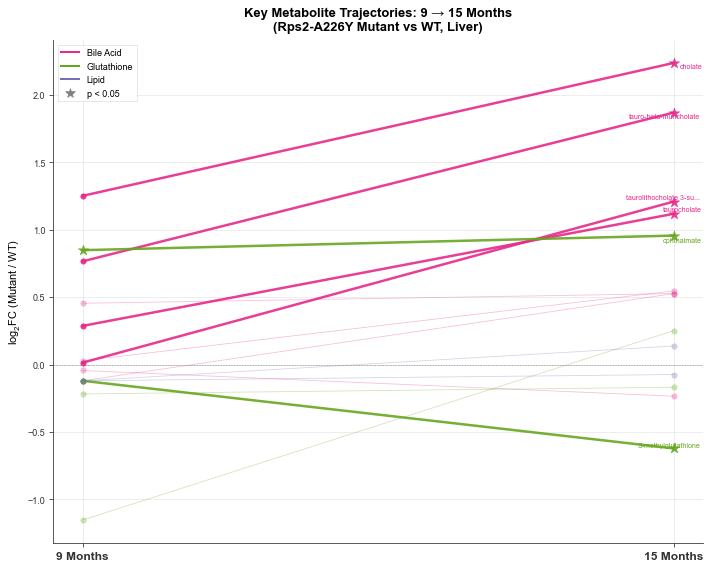

In [ ]:
# Figure 6: Metabolite trajectory plot (slope chart)
fig, ax = plt.subplots(figsize=(10, 8))

pathway_colors = {'Bile Acid': '#e7298a', 'Glutathione': '#66a61e', 'Lipid': '#7570b3'}

for _, row in traj_df.iterrows():
    color = pathway_colors[row['Pathway']]
    sig9 = row['pval_9m'] < 0.05
    sig15 = row['pval_15m'] < 0.05
    lw = 2.5 if (sig9 or sig15) else 0.8
    alpha = 0.9 if (sig9 or sig15) else 0.3
    
    ax.plot([0, 1], [row['log2FC_9m'], row['log2FC_15m']], color=color, lw=lw, alpha=alpha)
    
    # Markers
    m9 = '*' if sig9 else 'o'
    m15 = '*' if sig15 else 'o'
    s9 = 120 if sig9 else 30
    s15 = 120 if sig15 else 30
    ax.scatter(0, row['log2FC_9m'], color=color, marker=m9, s=s9, zorder=5, alpha=alpha)
    ax.scatter(1, row['log2FC_15m'], color=color, marker=m15, s=s15, zorder=5, alpha=alpha)

# Labels for significant metabolites
texts = []
for _, row in traj_df.iterrows():
    if row['pval_15m'] < 0.05 or row['pval_9m'] < 0.05:
        name = row['Metabolite']
        if len(name) > 25:
            name = name[:22] + '...'
        texts.append(ax.text(1.05, row['log2FC_15m'], name, fontsize=7, va='center', color=pathway_colors[row['Pathway']]))

adjust_text(texts, ax=ax, only_move={'points': 'y', 'text': 'y'})

ax.axhline(0, color='grey', lw=0.5, ls='--')
ax.set_xticks([0, 1])
ax.set_xticklabels(['9 Months', '15 Months'], fontsize=12, fontweight='bold')
ax.set_ylabel(r'$log_2$FC (Mutant / WT)', fontsize=11)
ax.set_title('Key Metabolite Trajectories: 9 → 15 Months\n(Rps2-A226Y Mutant vs WT, Liver)', fontsize=13, fontweight='bold')

legend_elements = [Line2D([0], [0], color=c, lw=2, label=p) for p, c in pathway_colors.items()]
legend_elements.append(Line2D([0], [0], marker='*', color='grey', markersize=10, lw=0, label='p < 0.05'))
ax.legend(handles=legend_elements, fontsize=9, loc='upper left')

plt.tight_layout()
plt.savefig('figures/figure6_corrected_metabolite_trajectory.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure6_corrected_metabolite_trajectory.pdf', bbox_inches='tight', facecolor='white')
plt.show()


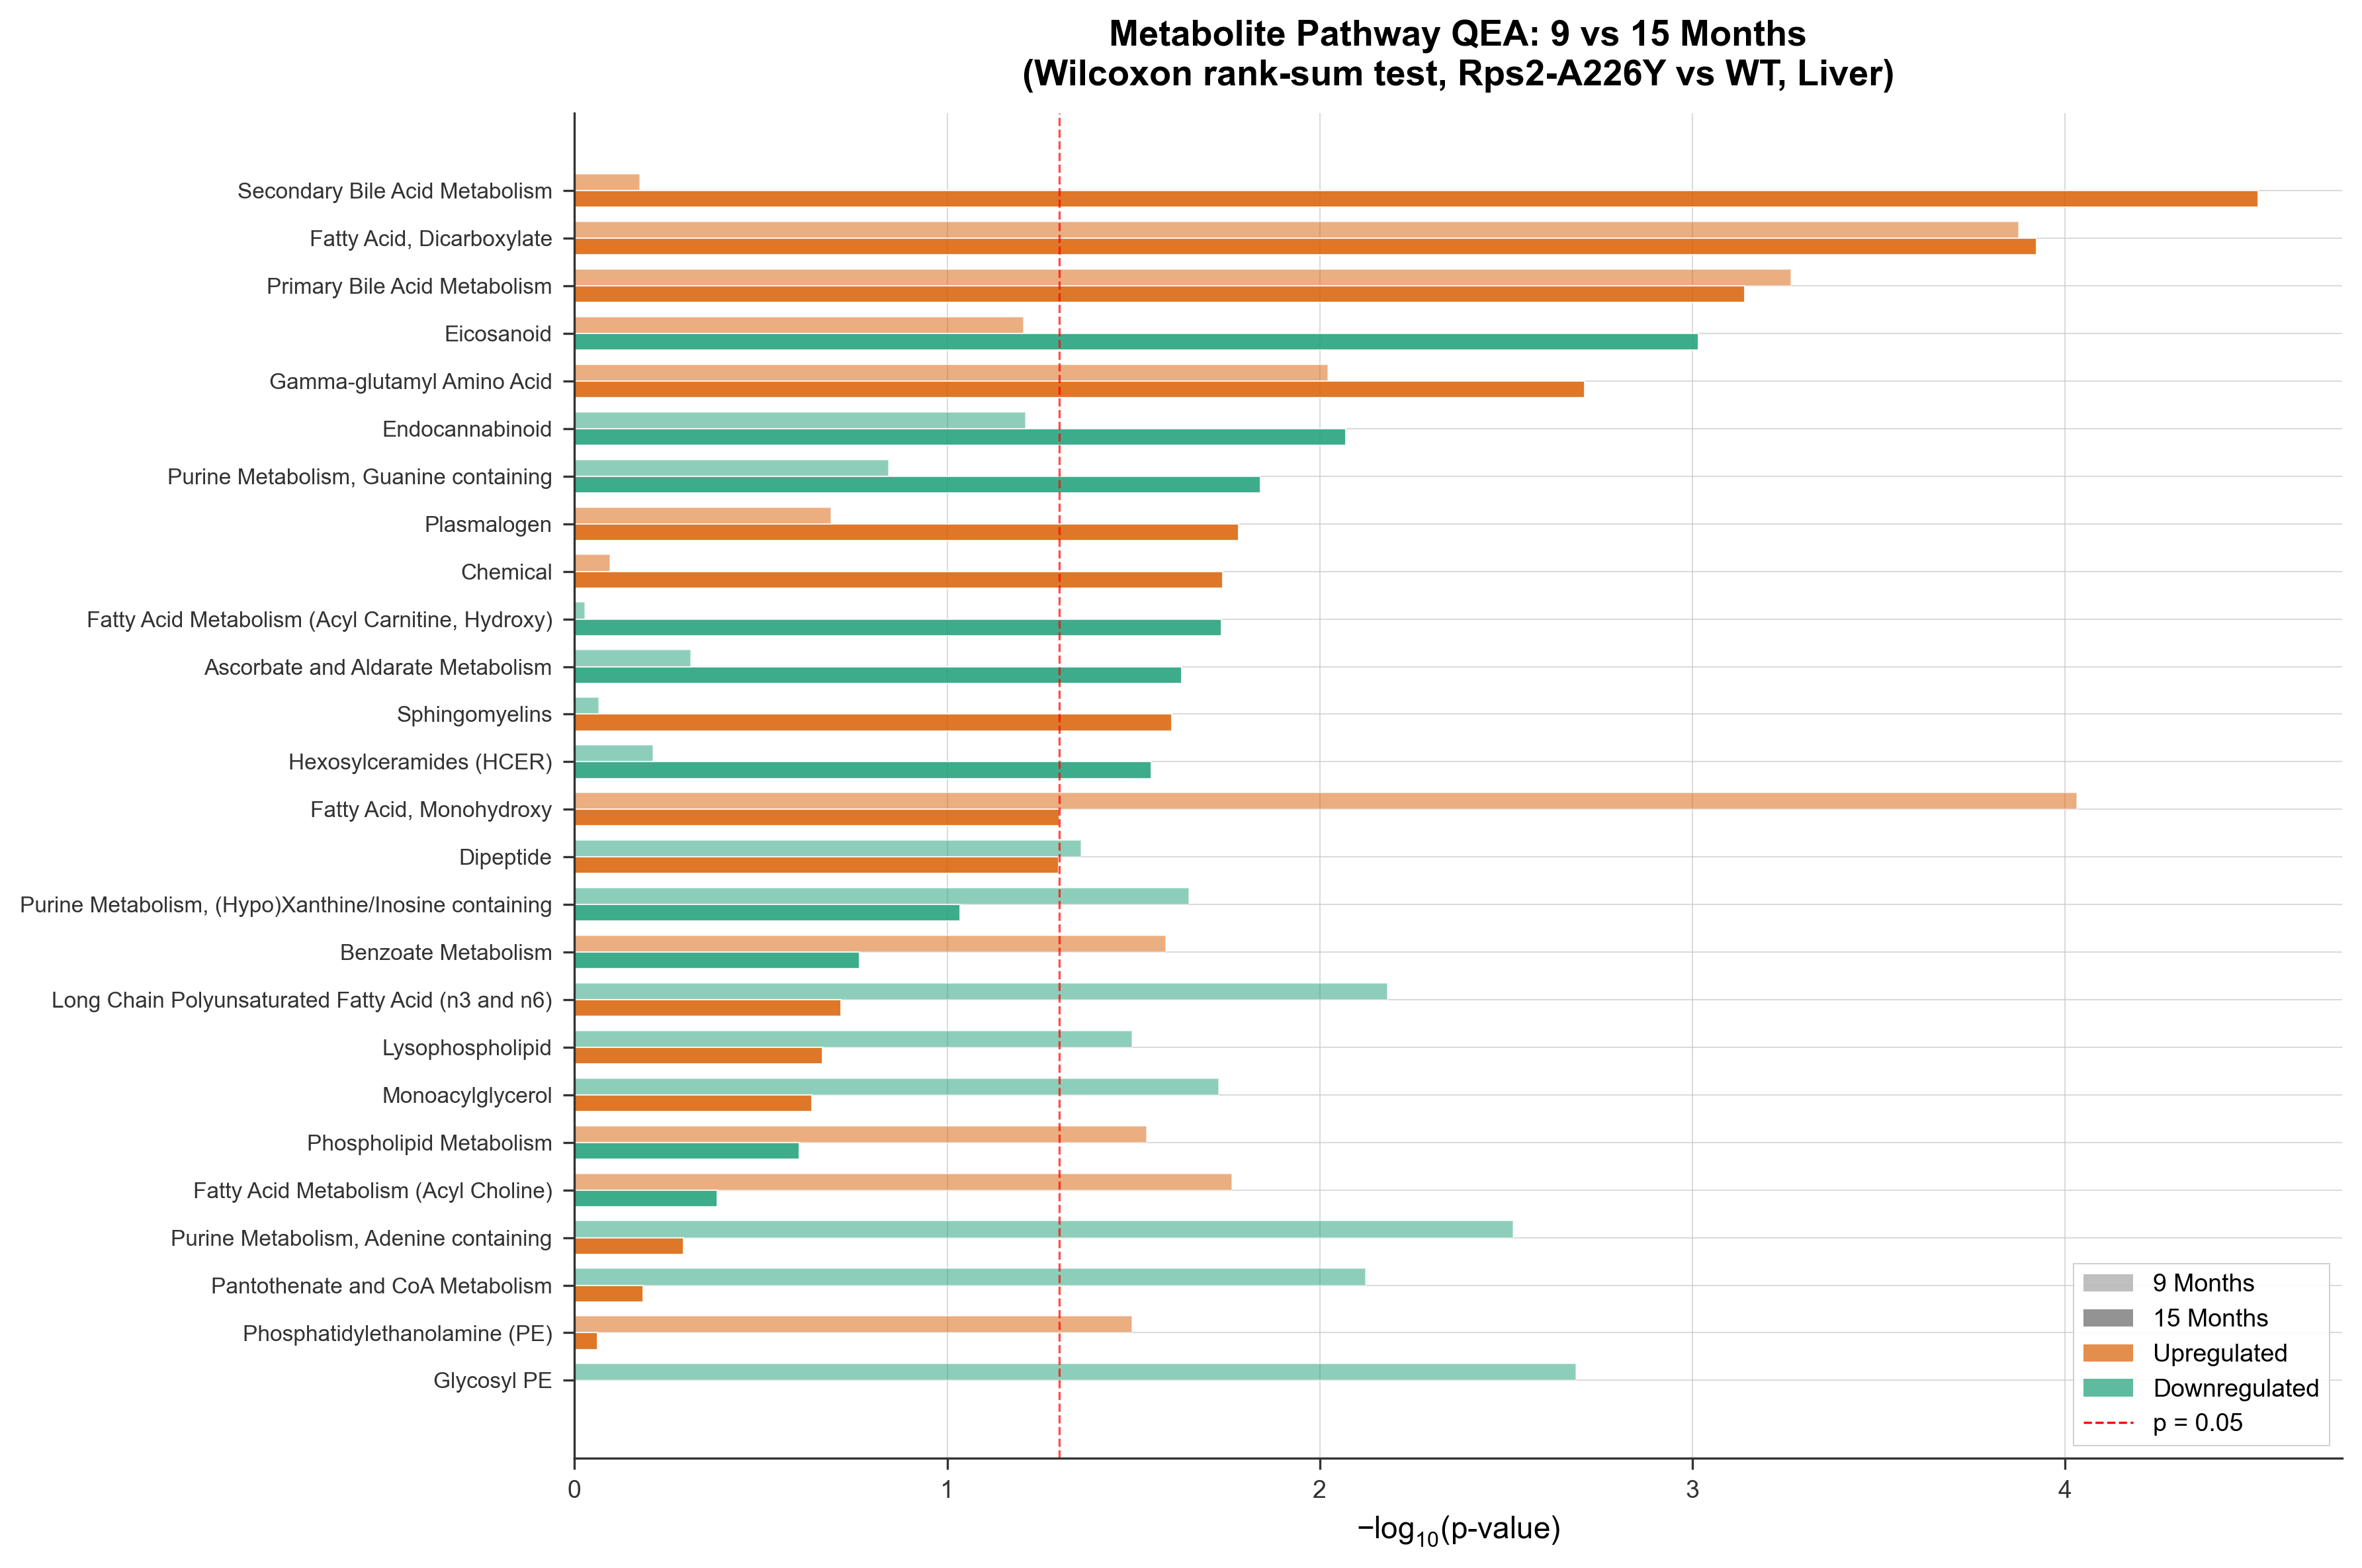

In [ ]:
# Figure 7: QEA comparison - 9m vs 15m metabolomics
# Get top pathways from both
met9_qea_top = met9_qea[met9_qea['wilcoxon_p'] < 0.1].head(15)
met15_qea_top = met15_qea[met15_qea['wilcoxon_p'] < 0.1].head(15)

# Union of top pathways
all_top_paths = list(set(met9_qea_top['Pathway'].tolist() + met15_qea_top['Pathway'].tolist()))

# Build comparison df
qea_comp = []
for p in all_top_paths:
    r9 = met9_qea[met9_qea['Pathway'] == p]
    r15 = met15_qea[met15_qea['Pathway'] == p]
    qea_comp.append({
        'Pathway': p,
        'neg_log10p_9m': -np.log10(r9['wilcoxon_p'].values[0]) if len(r9) > 0 else 0,
        'neg_log10p_15m': -np.log10(r15['wilcoxon_p'].values[0]) if len(r15) > 0 else 0,
        'dir_9m': r9['direction'].values[0] if len(r9) > 0 else 'NA',
        'dir_15m': r15['direction'].values[0] if len(r15) > 0 else 'NA',
        'n_9m': r9['n'].values[0] if len(r9) > 0 else 0,
        'n_15m': r15['n'].values[0] if len(r15) > 0 else 0,
    })
qea_comp_df = pd.DataFrame(qea_comp).sort_values('neg_log10p_15m', ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
y = np.arange(len(qea_comp_df))
width = 0.35

for i, (_, row) in enumerate(qea_comp_df.iterrows()):
    c9 = '#d95f02' if row['dir_9m'] == 'Up' else '#1b9e77'
    c15 = '#d95f02' if row['dir_15m'] == 'Up' else '#1b9e77'
    ax.barh(i + width/2, row['neg_log10p_9m'], width, color=c9, alpha=0.5, edgecolor='white')
    ax.barh(i - width/2, row['neg_log10p_15m'], width, color=c15, alpha=0.85, edgecolor='white')

ax.axvline(-np.log10(0.05), color='red', ls='--', lw=0.8, alpha=0.7, label='p = 0.05')
ax.set_yticks(y)
ax.set_yticklabels(qea_comp_df['Pathway'], fontsize=8)
ax.set_xlabel(r'$-log_{10}$(p-value)', fontsize=11)
ax.set_title('Metabolite Pathway QEA: 9 vs 15 Months\n(Wilcoxon rank-sum test, Rps2-A226Y vs WT, Liver)', fontsize=13, fontweight='bold')

legend_elements = [
    Patch(facecolor='grey', alpha=0.5, label='9 Months'),
    Patch(facecolor='grey', alpha=0.85, label='15 Months'),
    Patch(facecolor='#d95f02', alpha=0.7, label='Upregulated'),
    Patch(facecolor='#1b9e77', alpha=0.7, label='Downregulated'),
    Line2D([0], [0], color='red', ls='--', lw=0.8, label='p = 0.05'),
]
ax.legend(handles=legend_elements, fontsize=9, loc='lower right')

plt.tight_layout()
plt.savefig('figures/figure7_corrected_qea_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure7_corrected_qea_comparison.pdf', bbox_inches='tight', facecolor='white')
plt.show()


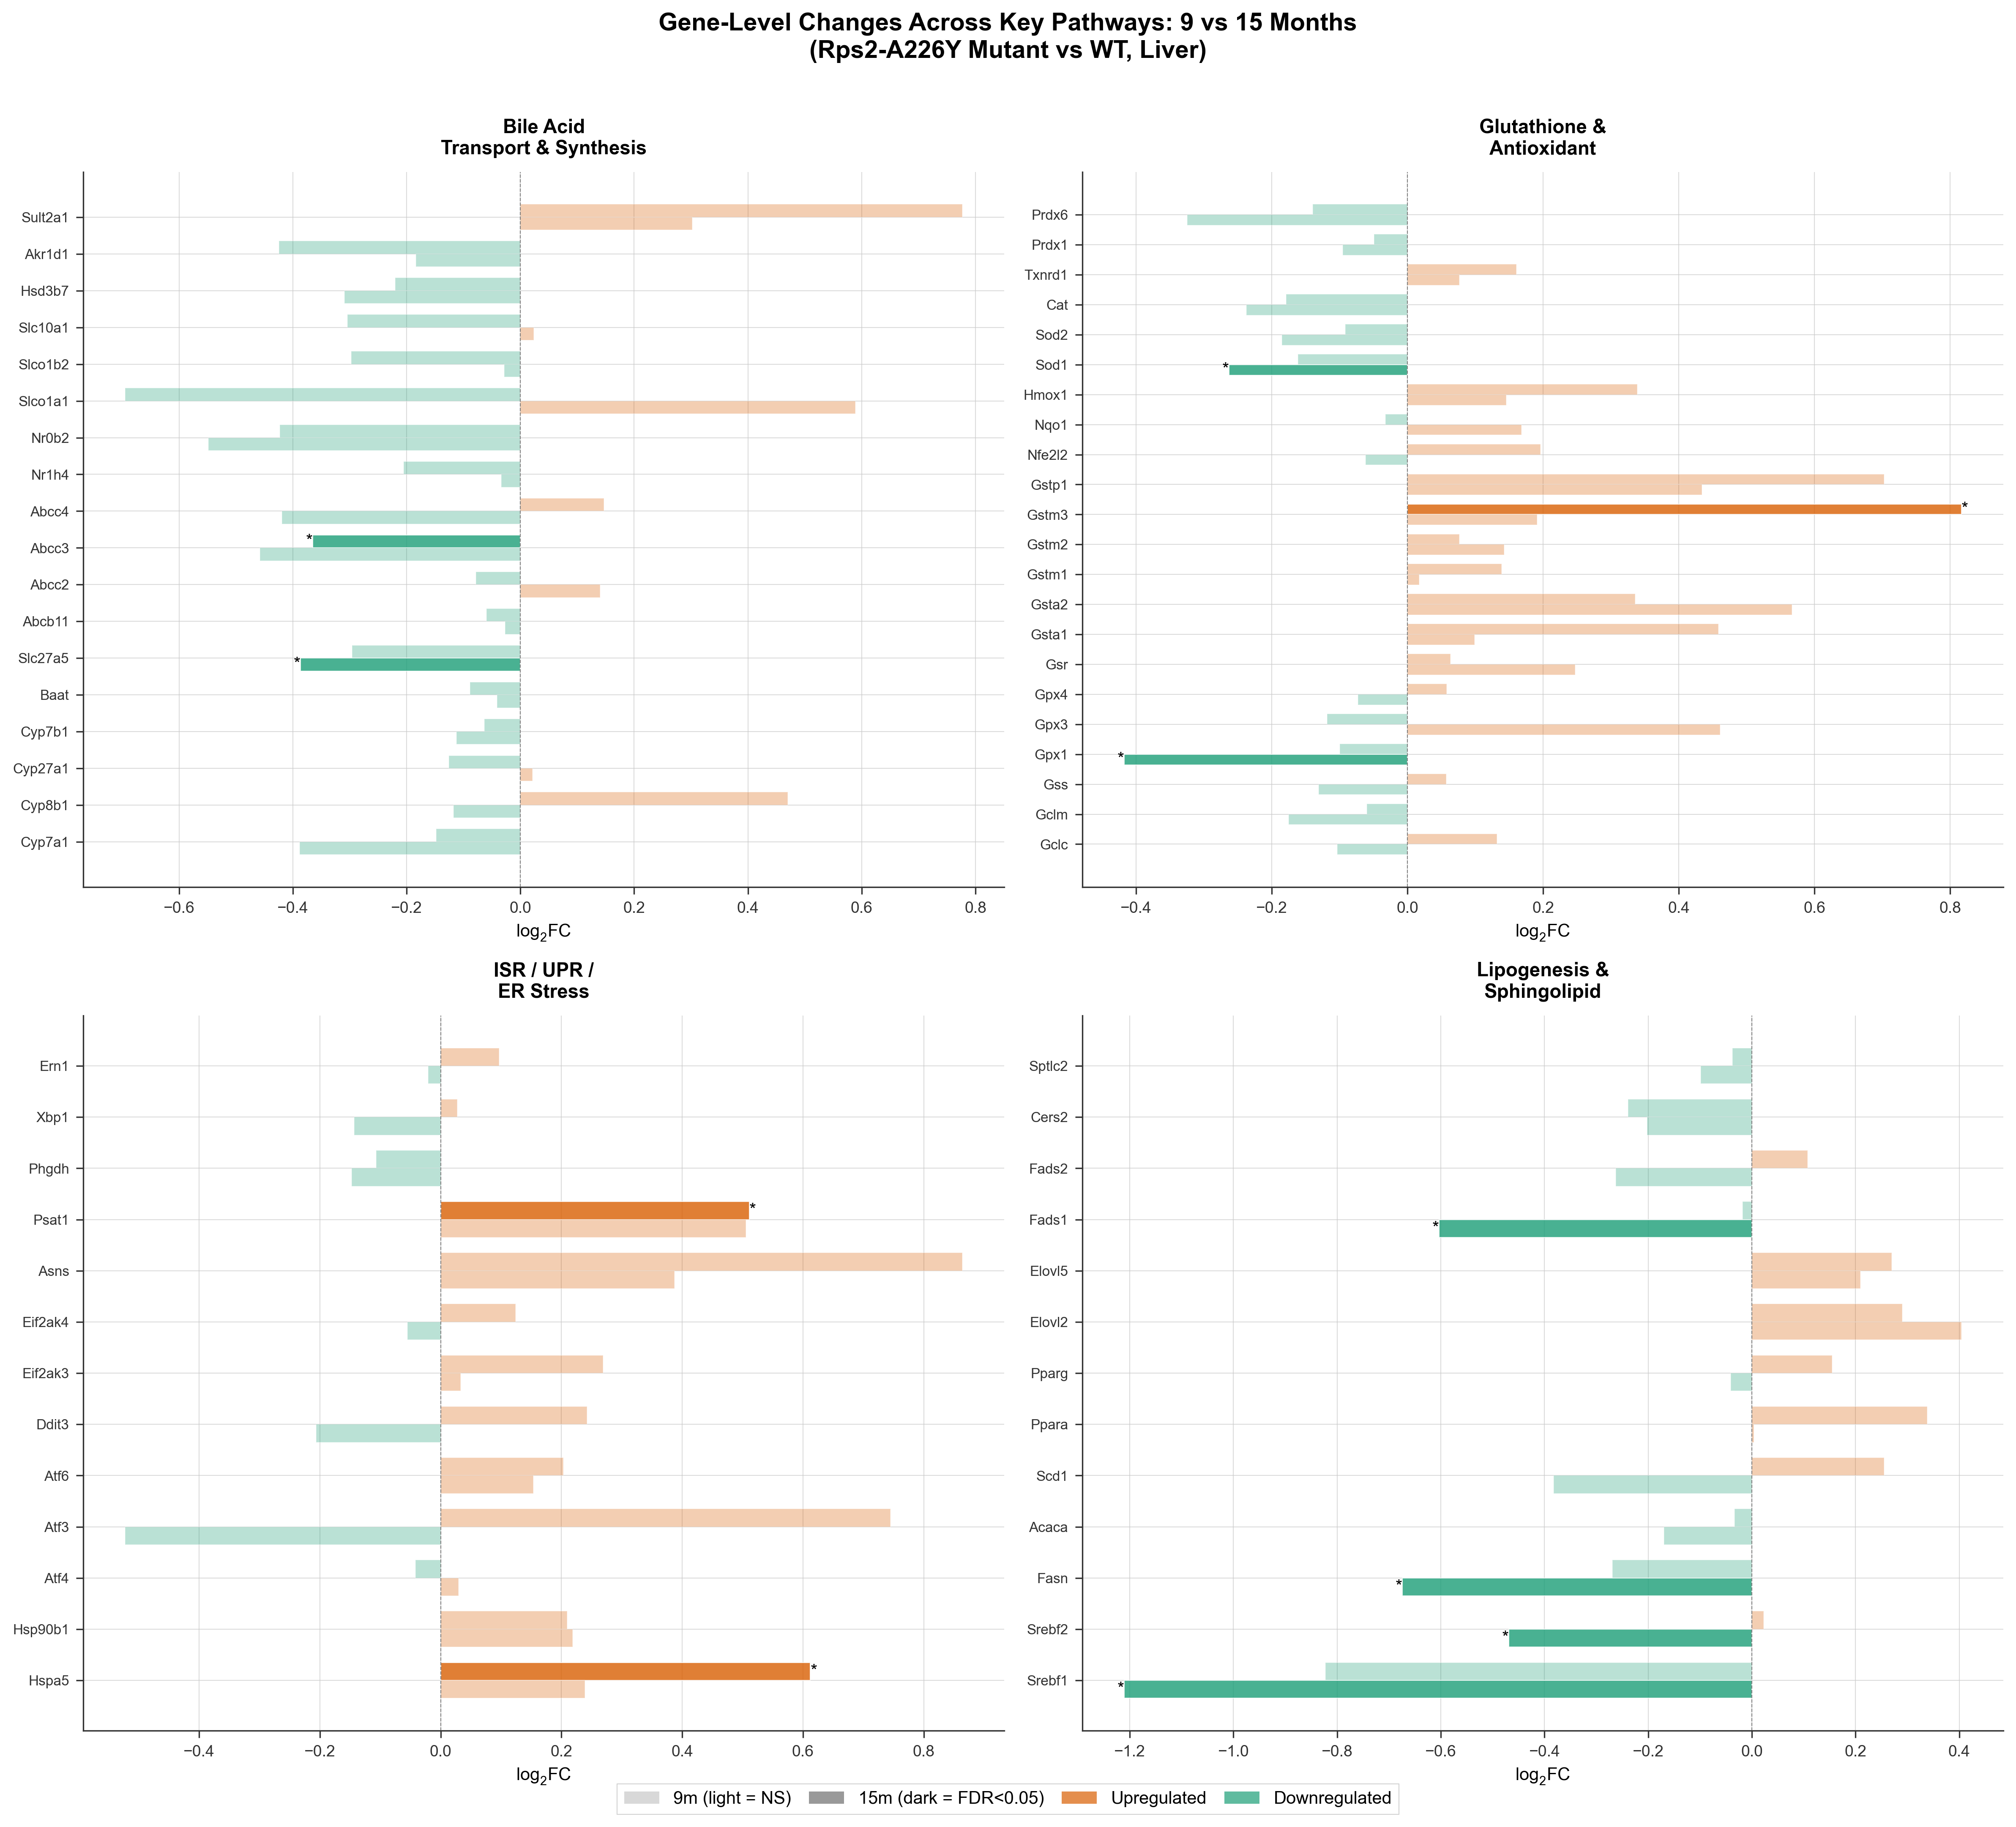

In [ ]:
# Figure 8: Gene-level detail for key pathways at both timepoints
# Focus on bile acid and glutathione genes
bile_genes = ['Cyp7a1', 'Cyp8b1', 'Cyp27a1', 'Cyp7b1', 'Baat', 'Slc27a5', 'Abcb11', 'Abcc2', 
              'Abcc3', 'Abcc4', 'Nr1h4', 'Nr0b2', 'Slco1a1', 'Slco1b2', 'Slc10a1',
              'Hsd3b7', 'Akr1d1', 'Sult2a1', 'Sult2a8']
gsh_genes = ['Gclc', 'Gclm', 'Gss', 'Gpx1', 'Gpx3', 'Gpx4', 'Gsr', 'Gsta1', 'Gsta2', 
             'Gstm1', 'Gstm2', 'Gstm3', 'Gstp1', 'Nfe2l2', 'Nqo1', 'Hmox1',
             'Sod1', 'Sod2', 'Cat', 'Txnrd1', 'Prdx1', 'Prdx6']
isr_genes = ['Hspa5', 'Hsp90b1', 'Atf4', 'Atf3', 'Atf6', 'Ddit3', 'Eif2ak3', 'Eif2ak4',
             'Asns', 'Psat1', 'Phgdh', 'Xbp1', 'Ern1']
lipid_genes = ['Srebf1', 'Srebf2', 'Fasn', 'Acaca', 'Scd1', 'Ppara', 'Pparg',
               'Elovl2', 'Elovl5', 'Fads1', 'Fads2', 'Cers2', 'Sptlc2']

gene_sets = {
    'Bile Acid\nTransport & Synthesis': bile_genes,
    'Glutathione &\nAntioxidant': gsh_genes,
    'ISR / UPR /\nER Stress': isr_genes,
    'Lipogenesis &\nSphingolipid': lipid_genes,
}

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, (panel_name, genes) in enumerate(gene_sets.items()):
    ax = axes[idx]
    gene_data = []
    for g in genes:
        r9 = tx9_clean[tx9_clean['gene_name'].str.lower() == g.lower()]
        r15 = tx15_clean[tx15_clean['gene_name'].str.lower() == g.lower()]
        if len(r9) > 0 and len(r15) > 0:
            gene_data.append({
                'Gene': r9.iloc[0]['gene_name'],
                'log2FC_9m': r9.iloc[0]['log2 Ratio'],
                'fdr_9m': r9.iloc[0]['fdr'],
                'log2FC_15m': r15.iloc[0]['log2 Ratio'],
                'fdr_15m': r15.iloc[0]['fdr'],
            })
    gdf = pd.DataFrame(gene_data)
    
    y = np.arange(len(gdf))
    w = 0.35
    for i, row in gdf.iterrows():
        c9 = '#d95f02' if row['log2FC_9m'] > 0 else '#1b9e77'
        c15 = '#d95f02' if row['log2FC_15m'] > 0 else '#1b9e77'
        a9 = 0.8 if row['fdr_9m'] < 0.05 else 0.3
        a15 = 0.8 if row['fdr_15m'] < 0.05 else 0.3
        ax.barh(i + w/2, row['log2FC_9m'], w, color=c9, alpha=a9, edgecolor='white')
        ax.barh(i - w/2, row['log2FC_15m'], w, color=c15, alpha=a15, edgecolor='white')
        if row['fdr_9m'] < 0.05:
            ax.text(row['log2FC_9m'], i + w/2, '*', fontsize=10, va='center', ha='left' if row['log2FC_9m'] > 0 else 'right')
        if row['fdr_15m'] < 0.05:
            ax.text(row['log2FC_15m'], i - w/2, '*', fontsize=10, va='center', ha='left' if row['log2FC_15m'] > 0 else 'right')
    
    ax.set_yticks(y)
    ax.set_yticklabels(gdf['Gene'], fontsize=8)
    ax.axvline(0, color='grey', lw=0.5, ls='--')
    ax.set_xlabel(r'$log_2$FC', fontsize=10)
    ax.set_title(panel_name, fontsize=11, fontweight='bold')

legend_elements = [
    Patch(facecolor='grey', alpha=0.3, label='9m (light = NS)'),
    Patch(facecolor='grey', alpha=0.8, label='15m (dark = FDR<0.05)'),
    Patch(facecolor='#d95f02', alpha=0.7, label='Upregulated'),
    Patch(facecolor='#1b9e77', alpha=0.7, label='Downregulated'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=10, frameon=True, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('Gene-Level Changes Across Key Pathways: 9 vs 15 Months\n(Rps2-A226Y Mutant vs WT, Liver)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/figure8_corrected_gene_detail.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure8_corrected_gene_detail.pdf', bbox_inches='tight', facecolor='white')
plt.show()


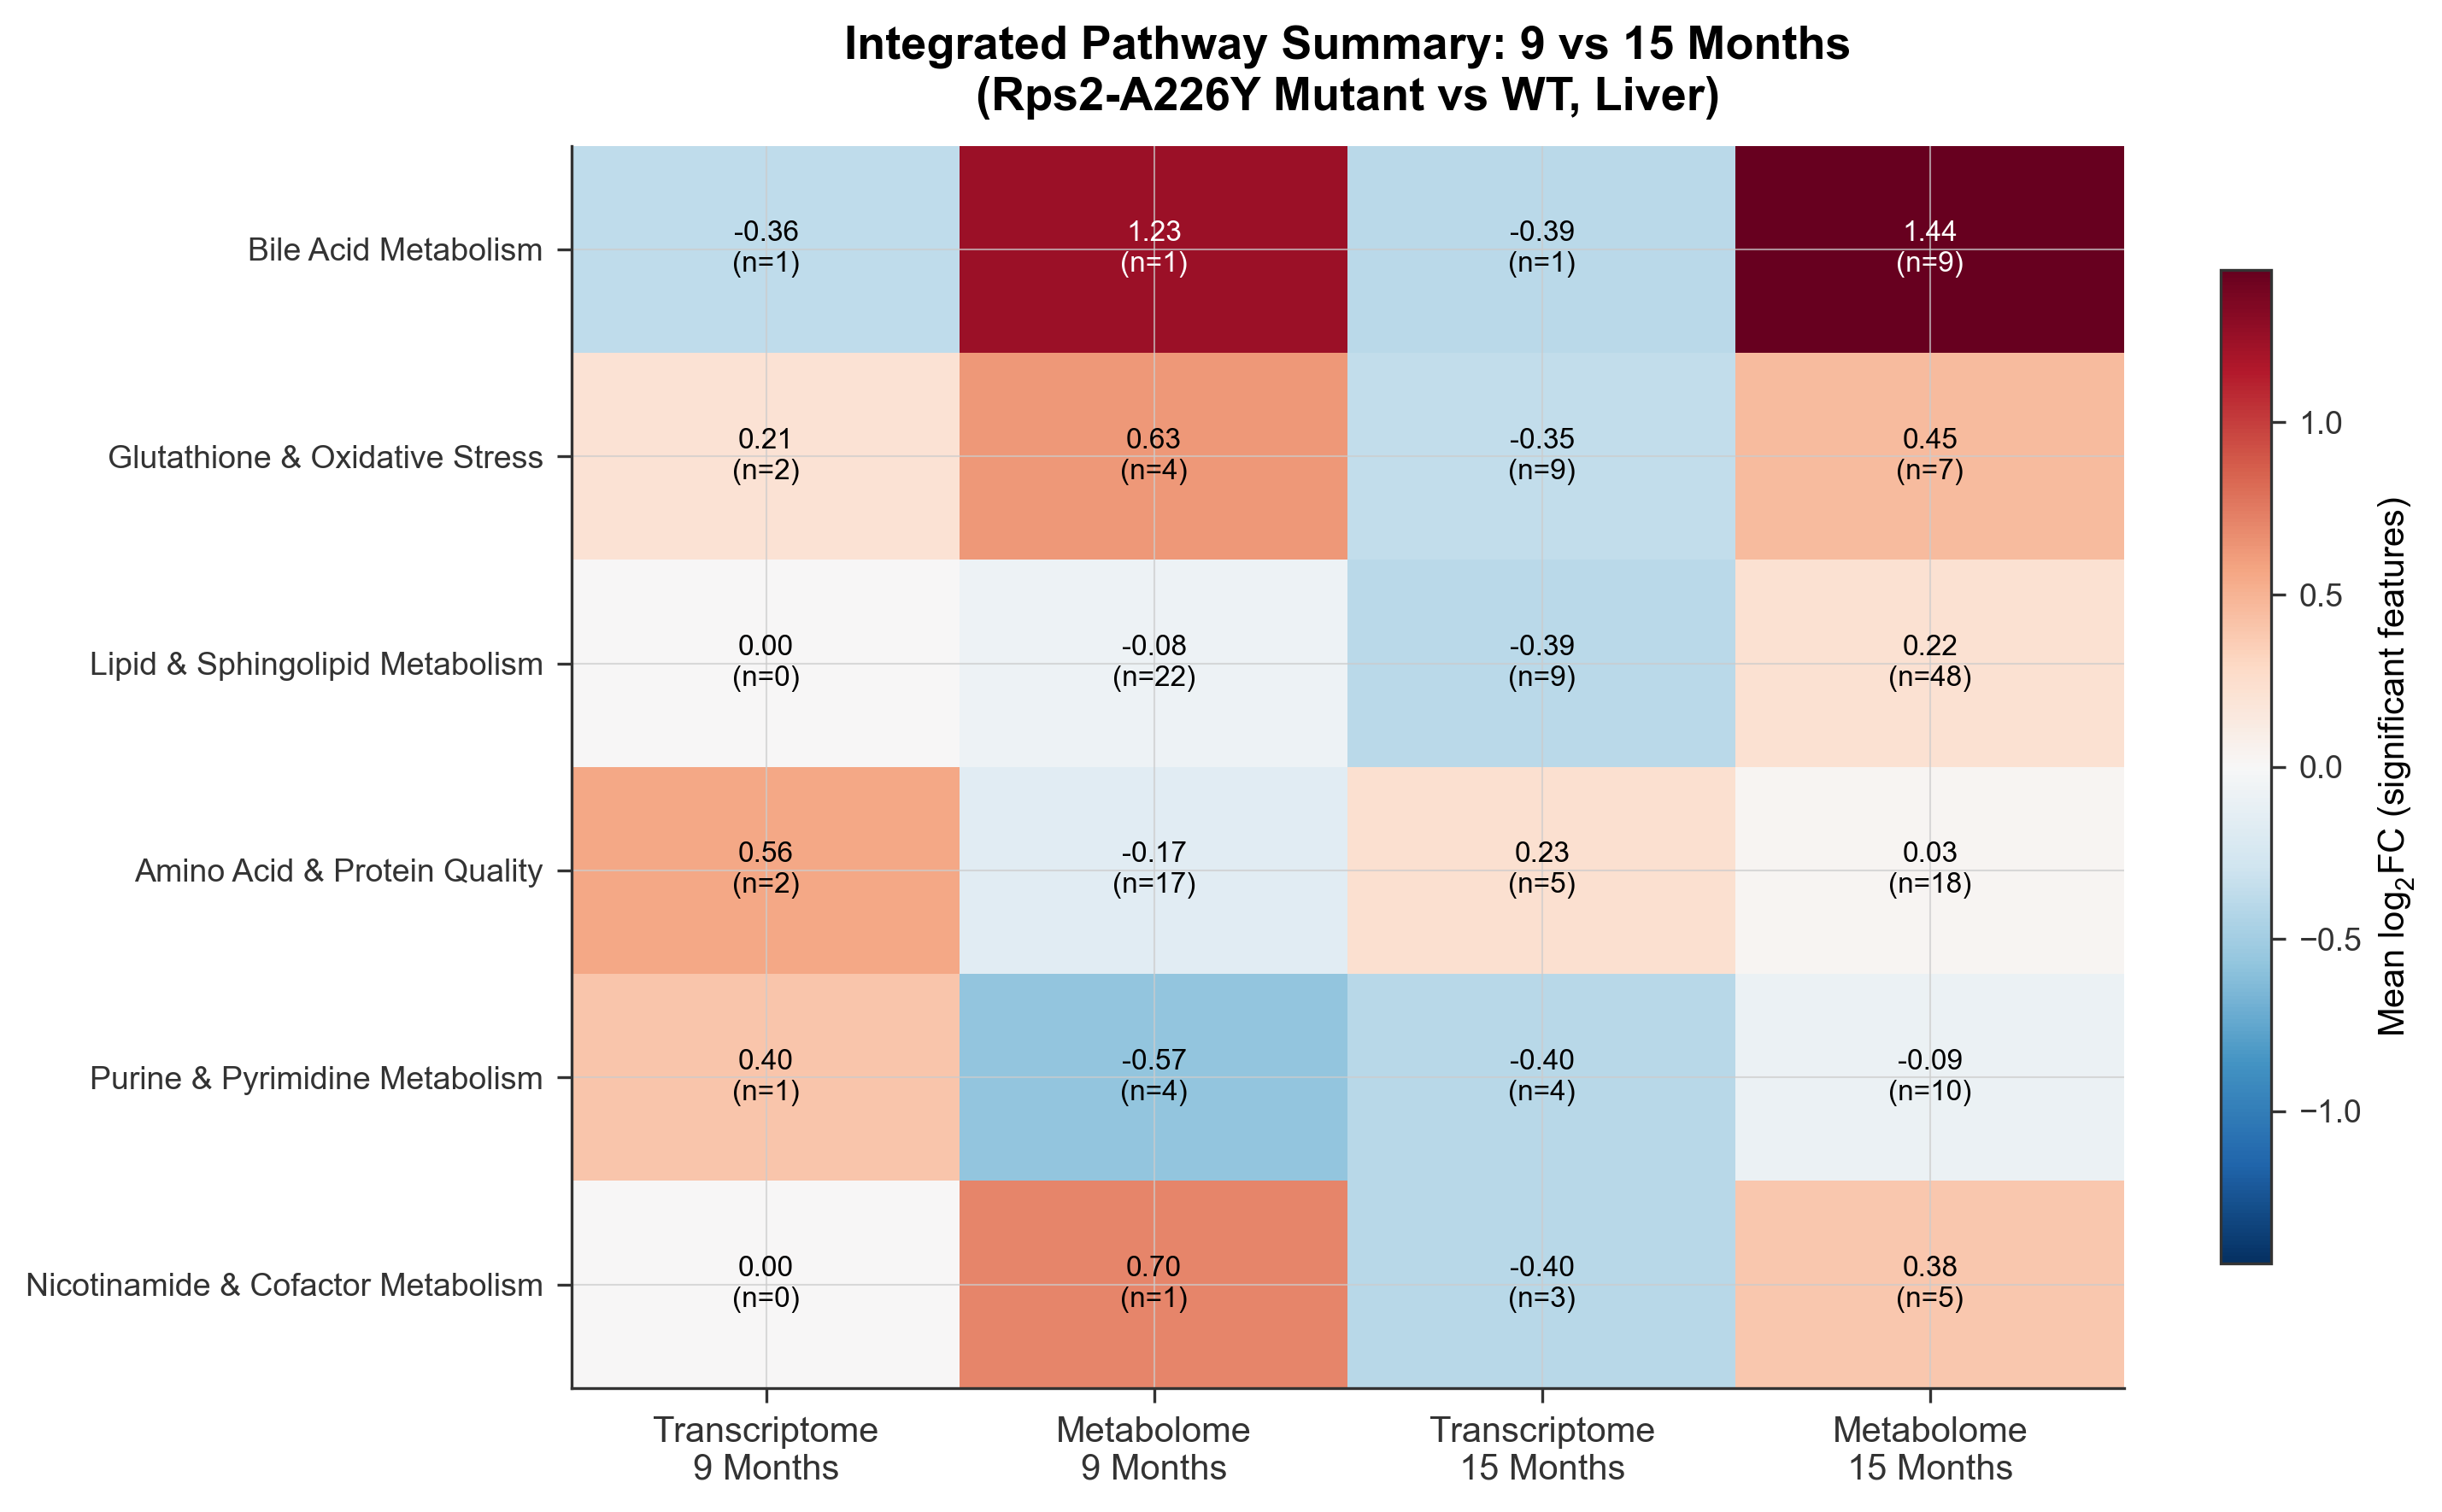

In [ ]:
# Figure 9: Integrated summary heatmap - pathway-level changes at both timepoints
import matplotlib.colors as mcolors

# Build a comprehensive summary
summary_data = []
for pathway in pathway_order:
    info = pathway_gene_map[pathway]
    
    # 9m transcriptome
    tx9_pw = tx9_clean[tx9_clean['gene_name'].str.lower().isin([g.lower() for g in info['genes']])]
    tx9_sig = tx9_pw[tx9_pw['fdr'] < 0.05]
    
    # 15m transcriptome
    tx15_pw = tx15_clean[tx15_clean['gene_name'].str.lower().isin([g.lower() for g in info['genes']])]
    tx15_sig = tx15_pw[tx15_pw['fdr'] < 0.05]
    
    # 9m metabolome
    met9_pw = met9[met9['Sub Pathway'].isin(info['metabolites'])]
    met9_sig = met9_pw[met9_pw['p-value'] < 0.05]
    
    # 15m metabolome
    met15_pw = met15[met15['Sub Pathway'].isin(info['metabolites'])]
    met15_sig = met15_pw[met15_pw['p-value'] < 0.05]
    
    summary_data.append({
        'Pathway': pathway,
        'Tx_9m_meanFC': tx9_sig['log2 Ratio'].mean() if len(tx9_sig) > 0 else 0,
        'Tx_15m_meanFC': tx15_sig['log2 Ratio'].mean() if len(tx15_sig) > 0 else 0,
        'Met_9m_meanFC': met9_sig['log2FC'].mean() if len(met9_sig) > 0 else 0,
        'Met_15m_meanFC': met15_sig['log2FC'].mean() if len(met15_sig) > 0 else 0,
        'Tx_9m_n': len(tx9_sig),
        'Tx_15m_n': len(tx15_sig),
        'Met_9m_n': len(met9_sig),
        'Met_15m_n': len(met15_sig),
    })

sdf = pd.DataFrame(summary_data)

fig, ax = plt.subplots(figsize=(10, 6))

# Create heatmap matrix
cols = ['Tx_9m_meanFC', 'Met_9m_meanFC', 'Tx_15m_meanFC', 'Met_15m_meanFC']
col_labels = ['Transcriptome\n9 Months', 'Metabolome\n9 Months', 'Transcriptome\n15 Months', 'Metabolome\n15 Months']
n_cols = ['Tx_9m_n', 'Met_9m_n', 'Tx_15m_n', 'Met_15m_n']

heatmap_data = sdf[cols].values
vmax = max(abs(heatmap_data.min()), abs(heatmap_data.max()))

cmap = plt.cm.RdBu_r
norm = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

im = ax.imshow(heatmap_data, cmap=cmap, norm=norm, aspect='auto')

# Add text annotations
for i in range(len(sdf)):
    for j in range(len(cols)):
        val = heatmap_data[i, j]
        n = sdf.iloc[i][n_cols[j]]
        text = f'{val:.2f}\n(n={n})'
        color = 'white' if abs(val) > vmax * 0.5 else 'black'
        ax.text(j, i, text, ha='center', va='center', fontsize=8, color=color)

ax.set_xticks(range(len(col_labels)))
ax.set_xticklabels(col_labels, fontsize=10)
ax.set_yticks(range(len(sdf)))
ax.set_yticklabels(sdf['Pathway'], fontsize=9)

cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label(r'Mean $log_2$FC (significant features)', fontsize=10)

ax.set_title('Integrated Pathway Summary: 9 vs 15 Months\n(Rps2-A226Y Mutant vs WT, Liver)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/figure9_corrected_integrated_heatmap.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('figures/figure9_corrected_integrated_heatmap.pdf', bbox_inches='tight', facecolor='white')
plt.show()


In [ ]:
# Check directionality consistency for genes significant at both timepoints
both_sig_genes = tx_merged[tx_merged['sig_cat'] == 'Both']
same_dir = ((both_sig_genes['log2 Ratio_9m'] > 0) & (both_sig_genes['log2 Ratio_15m'] > 0)) | \
           ((both_sig_genes['log2 Ratio_9m'] < 0) & (both_sig_genes['log2 Ratio_15m'] < 0))
print(f"Genes significant at both timepoints: {len(both_sig_genes)}")
print(f"Same direction: {same_dir.sum()} ({same_dir.mean()*100:.1f}%)")

# Check metabolites
both_sig_met = met_merged[met_merged['sig_cat'] == 'Both']
same_dir_met = ((both_sig_met['log2FC_9m'] > 0) & (both_sig_met['log2FC_15m'] > 0)) | \
               ((both_sig_met['log2FC_9m'] < 0) & (both_sig_met['log2FC_15m'] < 0))
print(f"\nMetabolites significant at both timepoints: {len(both_sig_met)}")
print(f"Same direction: {same_dir_met.sum()} ({same_dir_met.mean()*100:.1f}%)")

# Amplification: are 15m effects larger?
amp = (both_sig_genes['log2 Ratio_15m'].abs() > both_sig_genes['log2 Ratio_9m'].abs())
print(f"\nGenes with amplified effect at 15m: {amp.sum()}/{len(both_sig_genes)} ({amp.mean()*100:.1f}%)")

amp_met = (both_sig_met['log2FC_15m'].abs() > both_sig_met['log2FC_9m'].abs())
print(f"Metabolites with amplified effect at 15m: {amp_met.sum()}/{len(both_sig_met)} ({amp_met.mean()*100:.1f}%)")


Genes significant at both timepoints: 118
Same direction: 118 (100.0%)

Metabolites significant at both timepoints: 25
Same direction: 18 (72.0%)

Genes with amplified effect at 15m: 61/118 (51.7%)
Metabolites with amplified effect at 15m: 17/25 (68.0%)


In [ ]:
# Check the 7 metabolites that changed direction
discordant = both_sig_met[~same_dir_met]
print("Metabolites significant at both timepoints but with OPPOSITE direction:")
print(discordant[['Biochem', 'log2FC_9m', 'log2FC_15m', 'pval_9m', 'pval_15m']].to_string(index=False))


Metabolites significant at both timepoints but with OPPOSITE direction:
                  Biochem  log2FC_9m  log2FC_15m  pval_9m  pval_15m
  N-acetylaspartate (NAA)  -0.666576    0.516015   0.0022    0.0054
               picolinate   0.545968   -0.836501   0.0384    0.0009
       guanidinosuccinate  -0.577767    0.678072   0.0491    0.0146
                 fumarate  -0.321928    0.367371   0.0112    0.0046
                   malate  -0.251539    0.201634   0.0093    0.0243
 1-linolenoyl-GPC (18:3)*  -0.494109    0.555816   0.0298    0.0225
nicotinate ribonucleoside   0.704872   -0.785875   0.0279    0.0329


In [ ]:
# Key ISR/UPR gene check
isr_check = ['Hspa5', 'Hsp90b1', 'Atf4', 'Atf3', 'Atf6', 'Ddit3', 'Eif2ak3', 'Xbp1', 'Ern1', 'Asns']
print("ISR/UPR Gene Changes:")
print(f"{'Gene':<12} {'9m log2FC':>10} {'9m FDR':>10} {'15m log2FC':>11} {'15m FDR':>10}")
for g in isr_check:
    r9 = tx9_clean[tx9_clean['gene_name'].str.lower() == g.lower()]
    r15 = tx15_clean[tx15_clean['gene_name'].str.lower() == g.lower()]
    if len(r9) > 0 and len(r15) > 0:
        fc9 = r9.iloc[0]['log2 Ratio']
        fdr9 = r9.iloc[0]['fdr']
        fc15 = r15.iloc[0]['log2 Ratio']
        fdr15 = r15.iloc[0]['fdr']
        sig9 = '*' if fdr9 < 0.05 else ''
        sig15 = '*' if fdr15 < 0.05 else ''
        print(f"{g:<12} {fc9:>10.4f}{sig9:<1} {fdr9:>10.4f} {fc15:>11.4f}{sig15:<1} {fdr15:>10.4f}")


ISR/UPR Gene Changes:
Gene          9m log2FC     9m FDR  15m log2FC    15m FDR
Hspa5            0.6121*     0.0486      0.2391      0.2907
Hsp90b1          0.2092      0.3352      0.2185      0.1930
Atf4            -0.0418      0.8344      0.0298      0.8294
Atf3             0.7449      0.1092     -0.5225      0.1930
Atf6             0.2035      0.2459      0.1534      0.2212
Ddit3            0.2426      0.3884     -0.2062      0.3018
Eif2ak3          0.2690      0.1354      0.0328      0.8484
Xbp1             0.0275      0.9186     -0.1432      0.1647
Ern1             0.0971      0.6920     -0.0206      0.9155
Asns             0.8641      0.1883      0.3873      0.3281


In [ ]:
# Key lipogenesis genes
lipo_check = ['Srebf1', 'Srebf2', 'Fasn', 'Acaca', 'Scd1', 'Scd2', 'Ppara']
print("Lipogenesis Gene Changes:")
print(f"{'Gene':<12} {'9m log2FC':>10} {'9m FDR':>10} {'15m log2FC':>11} {'15m FDR':>10}")
for g in lipo_check:
    r9 = tx9_clean[tx9_clean['gene_name'].str.lower() == g.lower()]
    r15 = tx15_clean[tx15_clean['gene_name'].str.lower() == g.lower()]
    if len(r9) > 0 and len(r15) > 0:
        fc9 = r9.iloc[0]['log2 Ratio']
        fdr9 = r9.iloc[0]['fdr']
        fc15 = r15.iloc[0]['log2 Ratio']
        fdr15 = r15.iloc[0]['fdr']
        sig9 = '*' if fdr9 < 0.05 else ''
        sig15 = '*' if fdr15 < 0.05 else ''
        print(f"{g:<12} {fc9:>10.4f}{sig9:<1} {fdr9:>10.4f} {fc15:>11.4f}{sig15:<1} {fdr15:>10.4f}")

# Key antioxidant genes
print("\nAntioxidant Gene Changes:")
antioxidant_check = ['Gpx1', 'Gpx3', 'Gpx4', 'Gsr', 'Gsta1', 'Gsta2', 'Gstm1', 'Gstm2', 'Gstm3', 'Nqo1', 'Sod1', 'Sod2', 'Cat']
for g in antioxidant_check:
    r9 = tx9_clean[tx9_clean['gene_name'].str.lower() == g.lower()]
    r15 = tx15_clean[tx15_clean['gene_name'].str.lower() == g.lower()]
    if len(r9) > 0 and len(r15) > 0:
        fc9 = r9.iloc[0]['log2 Ratio']
        fdr9 = r9.iloc[0]['fdr']
        fc15 = r15.iloc[0]['log2 Ratio']
        fdr15 = r15.iloc[0]['fdr']
        sig9 = '*' if fdr9 < 0.05 else ''
        sig15 = '*' if fdr15 < 0.05 else ''
        print(f"{g:<12} {fc9:>10.4f}{sig9:<1} {fdr9:>10.4f} {fc15:>11.4f}{sig15:<1} {fdr15:>10.4f}")


Lipogenesis Gene Changes:
Gene          9m log2FC     9m FDR  15m log2FC    15m FDR
Srebf1          -0.8224      0.0689     -1.2110*     0.0048
Srebf2           0.0228      0.9513     -0.4686*     0.0136
Fasn            -0.2687      0.3800     -0.6744*     0.0126
Acaca           -0.0332      0.9169     -0.1699      0.2428
Scd1             0.2550      0.8086     -0.3827      0.4511
Scd2            -0.4035      0.2033     -0.0550      0.7853
Ppara            0.3380      0.1368      0.0041      0.9846

Antioxidant Gene Changes:
Gpx1            -0.0999      0.6422     -0.4179*     0.0073
Gpx3            -0.1187      0.7472      0.4612      0.0669
Gpx4             0.0576      0.7944     -0.0730      0.5318
Gsr              0.0632      0.7827      0.2470      0.0669
Gsta1            0.4583         nan      0.0990         nan
Gsta2            0.3354      0.2962      0.5667      0.2754
Gstm1            0.1387      0.6344      0.0172      0.9402
Gstm2            0.0764      0.8710      0.1425  

In [ ]:
# Check the 15m QEA results more carefully - compare with old pre-filtered results
print("=== 15m QEA with FULL background (738 metabolites) ===")
print(met15_qea[met15_qea['wilcoxon_fdr'] < 0.05][['Pathway', 'n', 'mean_log2FC', 'wilcoxon_p', 'wilcoxon_fdr', 'direction']].to_string(index=False))

print("\n=== 9m QEA (738 metabolites) ===")
print(met9_qea[met9_qea['wilcoxon_fdr'] < 0.05][['Pathway', 'n', 'mean_log2FC', 'wilcoxon_p', 'wilcoxon_fdr', 'direction']].to_string(index=False))


=== 15m QEA with FULL background (738 metabolites) ===
                       Pathway  n  mean_log2FC  wilcoxon_p  wilcoxon_fdr direction
Secondary Bile Acid Metabolism 14     0.818245    0.000030      0.002310        Up
     Fatty Acid, Dicarboxylate 19     0.423516    0.000119      0.004534        Up
  Primary Bile Acid Metabolism  8     0.960825    0.000725      0.018337        Up
                    Eicosanoid  6    -0.496120    0.000965      0.018337      Down
     Gamma-glutamyl Amino Acid  9     0.452180    0.001946      0.029573        Up

=== 9m QEA (738 metabolites) ===
                              Pathway  n  mean_log2FC  wilcoxon_p  wilcoxon_fdr direction
              Fatty Acid, Monohydroxy 13     0.268263    0.000093      0.005066        Up
            Fatty Acid, Dicarboxylate 19     0.200906    0.000133      0.005066        Up
         Primary Bile Acid Metabolism  8     0.471873    0.000545      0.013810        Up
                          Glycosyl PE  7    -0.378990

In [ ]:
# Check the TCA cycle metabolites that switched direction (fumarate, malate)
tca_mets = ['fumarate', 'malate', 'succinate', 'citrate', 'alpha-ketoglutarate', 'isocitrate']
print("TCA Cycle Metabolites:")
print(f"{'Metabolite':<25} {'9m log2FC':>10} {'9m p':>8} {'15m log2FC':>11} {'15m p':>8}")
for m in tca_mets:
    r9 = met9[met9['Biochem'].str.lower() == m.lower()]
    r15 = met15[met15['Biochem'].str.lower() == m.lower()]
    if len(r9) > 0 and len(r15) > 0:
        print(f"{m:<25} {r9.iloc[0]['log2FC']:>10.4f} {r9.iloc[0]['p-value']:>8.4f} {r15.iloc[0]['log2FC']:>11.4f} {r15.iloc[0]['p-value']:>8.4f}")

# NAA and picolinate - interesting direction switches
print("\nDirection-switching metabolites context:")
for m in ['N-acetylaspartate (NAA)', 'picolinate', 'nicotinate ribonucleoside']:
    r9 = met9[met9['Biochem'] == m]
    r15 = met15[met15['Biochem'] == m]
    if len(r9) > 0 and len(r15) > 0:
        print(f"  {m}: Sub Pathway = {r9.iloc[0]['Sub Pathway']}")
        print(f"    9m: FC={r9.iloc[0]['log2FC']:.3f}, p={r9.iloc[0]['p-value']:.4f}")
        print(f"    15m: FC={r15.iloc[0]['log2FC']:.3f}, p={r15.iloc[0]['p-value']:.4f}")


TCA Cycle Metabolites:
Metabolite                 9m log2FC     9m p  15m log2FC    15m p
fumarate                     -0.3219   0.0112      0.3674   0.0046
malate                       -0.2515   0.0093      0.2016   0.0243
succinate                    -0.2515   0.2073      0.1506   0.5888
citrate                       0.0144   0.8864      0.1763   0.6141
alpha-ketoglutarate          -0.6439   0.0096      0.0566   0.9952

Direction-switching metabolites context:
  N-acetylaspartate (NAA): Sub Pathway = Alanine and Aspartate Metabolism
    9m: FC=-0.667, p=0.0022
    15m: FC=0.516, p=0.0054
  picolinate: Sub Pathway = Tryptophan Metabolism
    9m: FC=0.546, p=0.0384
    15m: FC=-0.837, p=0.0009
  nicotinate ribonucleoside: Sub Pathway = Nicotinate and Nicotinamide Metabolism
    9m: FC=0.705, p=0.0279
    15m: FC=-0.786, p=0.0329


In [ ]:
# Summary statistics for the final answer
print("=" * 60)
print("CORRECTED ANALYSIS SUMMARY")
print("=" * 60)

print("\n--- Dataset Sizes ---")
print(f"9-month transcriptome: {len(tx9_clean)} genes, {tx9_clean['significant'].sum()} significant (FDR<0.05)")
print(f"15-month transcriptome: {len(tx15_clean)} genes, {tx15_clean['significant'].sum()} significant (FDR<0.05)")
print(f"9-month metabolome: {len(met9)} metabolites, {met9['significant'].sum()} significant (p<0.05)")
print(f"15-month metabolome: {len(met15)} metabolites, {met15['significant'].sum()} significant (p<0.05)")

print("\n--- Temporal Concordance ---")
print(f"Genes sig at both: {len(both_sig_genes)}, 100% same direction")
print(f"Metabolites sig at both: {len(both_sig_met)}, {same_dir_met.sum()}/{len(both_sig_met)} ({same_dir_met.mean()*100:.0f}%) same direction")
print(f"  7 metabolites switched direction (TCA intermediates, NAA, picolinate, nicotinate ribonucleoside)")

print("\n--- Key Pathway Changes (15m QEA, FDR<0.05) ---")
for _, row in met15_qea[met15_qea['wilcoxon_fdr'] < 0.05].iterrows():
    print(f"  {row['Pathway']}: mean log2FC={row['mean_log2FC']:.3f}, p={row['wilcoxon_p']:.2e}, FDR={row['wilcoxon_fdr']:.4f} ({row['direction']})")

print("\n--- Key Biological Findings (unchanged by correction) ---")
print("1. Progressive phenotype confirmed: 9m → 15m shows escalating dysregulation")
print("2. Bile acid accumulation: Primary BA enriched at BOTH timepoints (9m & 15m)")
print("   Secondary BA enrichment emerges strongly at 15m")
print("3. Hspa5/BiP: significantly UP at 9m (FDR=0.049), NOT significant at 15m (FDR=0.29)")
print("   → ISR/UPR silencing confirmed at 15m")
print("4. Lipogenesis suppression at 15m: Srebf1 (FDR=0.005), Srebf2 (FDR=0.014), Fasn (FDR=0.013)")
print("5. Antioxidant downregulation at 15m: Gpx1 (FDR=0.007), Sod1 (FDR=0.048)")
print("6. TCA intermediates SWITCH direction: fumarate/malate DOWN at 9m → UP at 15m")
print("   → Suggests metabolic remodeling from reduced TCA flux to TCA backup/overflow")


CORRECTED ANALYSIS SUMMARY

--- Dataset Sizes ---
9-month transcriptome: 22524 genes, 255 significant (FDR<0.05)
15-month transcriptome: 22524 genes, 1892 significant (FDR<0.05)
9-month metabolome: 738 metabolites, 92 significant (p<0.05)
15-month metabolome: 738 metabolites, 157 significant (p<0.05)

--- Temporal Concordance ---
Genes sig at both: 118, 100% same direction
Metabolites sig at both: 25, 18/25 (72%) same direction
  7 metabolites switched direction (TCA intermediates, NAA, picolinate, nicotinate ribonucleoside)

--- Key Pathway Changes (15m QEA, FDR<0.05) ---
  Secondary Bile Acid Metabolism: mean log2FC=0.818, p=3.04e-05, FDR=0.0023 (Up)
  Fatty Acid, Dicarboxylate: mean log2FC=0.424, p=1.19e-04, FDR=0.0045 (Up)
  Primary Bile Acid Metabolism: mean log2FC=0.961, p=7.25e-04, FDR=0.0183 (Up)
  Eicosanoid: mean log2FC=-0.496, p=9.65e-04, FDR=0.0183 (Down)
  Gamma-glutamyl Amino Acid: mean log2FC=0.452, p=1.95e-03, FDR=0.0296 (Up)

--- Key Biological Findings (unchanged by c